# Trabajo Fin de Máster Mantenimiento Predictivo

# Notebook 04 - Detección de anomalías y degradación en FD001

## Objetivo

El objetivo de este notebook es desarrollar y evaluar métodos de detección de anomalías capaces de identificar desviaciones en el comportamiento multivariante de los motores del subconjunto FD001 a partir de las señales de sus sensores.

C-MAPSS no proporciona una etiqueta que indique explícitamente el ciclo exacto en el que comienza la degradación de cada motor. Por este motivo, el problema no puede plantearse directamente como una clasificación supervisada convencional entre estados normales y anómalos.

El enfoque consistirá en caracterizar un comportamiento inicial de referencia y utilizar diferentes métodos para cuantificar posteriormente el grado de desviación de las observaciones respecto a dicho comportamiento.

La salida principal de los modelos será una puntuación continua de anomalía (*anomaly score*), que permitirá estudiar cómo evoluciona el estado del motor a lo largo de su trayectoria.

La variable RUL no se utilizará como entrada de los detectores. Se empleará únicamente durante el análisis posterior de los resultados para estudiar la relación entre las puntuaciones de anomalía y la proximidad al final de vida.

## 0. Importación de librerías necesarias en el notebook

Se importan las librerías necesarias para la carga y análisis de los datos, así como para el entrenamiento y evaluación de los métodos de detección de anomalías.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import joblib
import tensorflow as tf

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from scipy.stats import spearmanr
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

## 1. Carga de los datos preprocesados

El análisis partirá de los conjuntos generados durante el preprocesamiento de FD001. De esta forma se reutilizarán la selección de variables y las transformaciones definidas previamente sin repetir el proceso de preparación de los datos.

Se cargarán el conjunto de entrenamiento preprocesado y la información almacenada sobre el procedimiento de preprocesamiento.

Aunque el conjunto de test también se encuentra disponible, inicialmente el desarrollo y análisis de los métodos de detección de anomalías se realizará sobre las trayectorias completas del conjunto de entrenamiento. Estas trayectorias permiten observar la evolución de cada motor hasta el final de su vida y estudiar posteriormente cómo cambia la puntuación de anomalía a medida que disminuye la RUL.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_PATH = "/content/drive/MyDrive/TFM"
RAW_DATA_PATH = f"{PROJECT_PATH}/data/raw"
PROCESSED_DATA_PATH = f"{PROJECT_PATH}/data/processed"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
train = pd.read_csv(
    f"{PROCESSED_DATA_PATH}/train_FD001_preprocessed.csv"
)

preprocessing_info = joblib.load(
    f"{PROCESSED_DATA_PATH}/preprocessing_FD001.pkl"
)

sensor_features = preprocessing_info["sensor_features"]

print("Dimensiones:", train.shape)
print("Motores:", train["unit"].nunique())

print("\nVariables predictoras:")
print(sensor_features)

print("\nNúmero de sensores:", len(sensor_features))

Dimensiones: (20631, 20)
Motores: 100

Variables predictoras:
['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']

Número de sensores: 14


Los datos preprocesados se han recuperado correctamente. El conjunto contiene 20.631 observaciones correspondientes a los 100 motores de entrenamiento de FD001 y mantiene los 14 sensores seleccionados durante la etapa de preprocesamiento.

Estos sensores constituirán las variables de entrada iniciales para los métodos de detección de anomalías. Las variables estructurales y la RUL se conservarán únicamente para organizar las trayectorias y analizar posteriormente los resultados, pero no se utilizarán como variables de entrada del detector.

## 2. Planteamiento de la detección de anomalías

Antes de aplicar los diferentes métodos de detección de anomalías es necesario definir cómo se abordará el problema en C-MAPSS.

### 2.1. Ausencia de etiquetas explícitas de anomalía

El conjunto C-MAPSS describe trayectorias de degradación progresiva, pero no proporciona una variable que identifique explícitamente cada observación como normal o anómala ni indica el ciclo exacto en el que comienza el daño.

Por tanto, no existe una etiqueta real que permita plantear directamente el problema como una clasificación supervisada.

El objetivo será caracterizar el comportamiento de referencia de los motores y estudiar posteriormente cuánto se alejan las observaciones de dicho comportamiento a medida que avanza su vida operativa.

### 2.2. Definición inicial del comportamiento de referencia

La documentación de C-MAPSS establece que las trayectorias comienzan en condiciones de funcionamiento normal y que la degradación se desarrolla posteriormente. Sin embargo, el instante exacto de inicio del proceso de degradación no está disponible.

Durante el preprocesamiento se utilizó el primer 10 % de la trayectoria de cada motor como región inicial de referencia para estudiar la evolución conjunta de varios sensores. Esta selección permitió comparar motores con diferentes longitudes de vida mediante una escala temporal relativa.

La variable `relative_life` se utiliza exclusivamente durante el desarrollo del modelo para seleccionar retrospectivamente la región inicial de referencia a partir de las trayectorias completas de entrenamiento. No se utilizará como variable de entrada del detector, ya que su cálculo requiere conocer la duración final de cada trayectoria.

En este notebook se partirá de esta misma región como candidata para caracterizar el comportamiento inicial de los motores. No obstante, esta región no se interpretará como una etiqueta real de estado saludable, sino como una aproximación al comportamiento inicial de referencia proporcionado por las propias trayectorias.

In [ ]:
train["max_cycle"] = (
    train.groupby("unit")["cycle"].transform("max")
)

train["relative_life"] = (
    (train["cycle"] - 1) /
    (train["max_cycle"] - 1)
)

reference_data = train[
    train["relative_life"] <= 0.10
].copy()

In [ ]:
print("Observaciones totales:", len(train))
print("Observaciones de referencia:", len(reference_data))

print(
    "Porcentaje utilizado como referencia:",
    round(len(reference_data) / len(train) * 100, 2),
    "%"
)

print(
    "Motores representados:",
    reference_data["unit"].nunique()
)

print("\nObservaciones de referencia por motor:")
print(reference_data.groupby("unit").size().describe())

Observaciones totales: 20631
Observaciones de referencia: 2106
Porcentaje utilizado como referencia: 10.21 %
Motores representados: 100

Observaciones de referencia por motor:
count    100.000000
mean      21.060000
std        4.690028
min       13.000000
25%       18.000000
50%       20.000000
75%       23.000000
max       37.000000
dtype: float64



La región inicial seleccionada contiene 2.106 observaciones, equivalentes aproximadamente al 10,21 % del conjunto de entrenamiento completo.

Los 100 motores de FD001 están representados en esta región. Debido a que las trayectorias presentan diferentes longitudes, el número de observaciones aportadas por cada unidad también varía, con un mínimo de 13 ciclos, un máximo de 37 y una mediana de 20 observaciones.

La utilización de una proporción relativa de la trayectoria, en lugar de un número fijo de ciclos, permite adaptar la región de referencia a la duración de cada motor. Esta región se utilizará como aproximación al comportamiento inicial de los motores, sin asumir que constituye una etiqueta exacta de funcionamiento saludable.

## 3. Separación de motores para desarrollo y evaluación

La estructura temporal de C-MAPSS hace necesario realizar la separación de los datos a nivel de motor y no mediante una división aleatoria de observaciones.

Si diferentes ciclos de una misma unidad aparecieran simultáneamente en los conjuntos utilizados para desarrollar y evaluar el detector, existiría dependencia entre ambos conjuntos y la evaluación no representaría adecuadamente el comportamiento del método ante motores no utilizados durante su ajuste.

Por este motivo, los 100 motores de `train_FD001` se dividirán en dos grupos independientes:

- **80 motores de desarrollo**, utilizados para construir y ajustar los métodos de detección de anomalías.
- **20 motores de evaluación**, reservados para analizar el comportamiento de los detectores sobre trayectorias de motores no utilizadas durante su ajuste.

La división se realizará utilizando los identificadores de los motores, de forma que todas las observaciones pertenecientes a una misma unidad permanezcan siempre en el mismo grupo.

### 3.1. División de las unidades

La división se realizará de forma aleatoria pero reproducible utilizando una semilla fija. La selección se aplicará sobre los identificadores de los motores y no sobre las observaciones individuales.

De esta forma se garantiza que ningún motor utilizado para la evaluación haya participado en el desarrollo del detector.

In [ ]:
units = train["unit"].unique()

development_units, evaluation_units = train_test_split(
    units,
    test_size=0.20,
    random_state=42
)

development_data = train[
    train["unit"].isin(development_units)
].copy()

evaluation_data = train[
    train["unit"].isin(evaluation_units)
].copy()

print("Motores de desarrollo:", development_data["unit"].nunique())
print("Motores de evaluación:", evaluation_data["unit"].nunique())

print("\nObservaciones de desarrollo:", len(development_data))
print("Observaciones de evaluación:", len(evaluation_data))

print(
    "\nMotores presentes en ambos conjuntos:",
    len(set(development_units) & set(evaluation_units))
)

Motores de desarrollo: 80
Motores de evaluación: 20

Observaciones de desarrollo: 16561
Observaciones de evaluación: 4070

Motores presentes en ambos conjuntos: 0


La división realizada genera dos grupos completamente independientes a nivel de motor. El conjunto de desarrollo contiene 80 unidades y 16.561 observaciones, mientras que el conjunto de evaluación contiene 20 unidades y 4.070 observaciones.

No existe ningún motor compartido entre ambos conjuntos, por lo que todas las observaciones pertenecientes a una misma unidad permanecen dentro del mismo grupo.

Esta separación permitirá desarrollar los métodos de detección de anomalías utilizando únicamente los motores del conjunto de desarrollo y analizar posteriormente su comportamiento sobre trayectorias completas de motores no utilizados durante el ajuste.

### 3.2. Selección de la región de referencia para el desarrollo

El conjunto de desarrollo contiene las trayectorias completas de 80 motores, incluyendo tanto sus etapas iniciales como las regiones próximas al final de vida. Por este motivo, no todas sus observaciones se utilizarán para caracterizar el comportamiento de referencia.

Para el ajuste inicial de los detectores se seleccionarán únicamente las observaciones correspondientes al primer 10 % de la trayectoria de cada uno de los motores de desarrollo.

De esta forma, los modelos aprenderán a partir de una aproximación al comportamiento inicial de los motores, mientras que las observaciones posteriores quedarán disponibles para estudiar cómo evoluciona la puntuación de anomalía a medida que avanza cada trayectoria.

In [ ]:
development_reference = development_data[
    development_data["relative_life"] <= 0.10
].copy()

print(
    "Observaciones de referencia para desarrollo:",
    len(development_reference)
)

print(
    "Motores representados:",
    development_reference["unit"].nunique()
)

print("\nObservaciones de referencia por motor:")
print(
    development_reference.groupby("unit")
    .size()
    .describe()
)

Observaciones de referencia para desarrollo: 1691
Motores representados: 80

Observaciones de referencia por motor:
count    80.000000
mean     21.137500
std       4.825417
min      13.000000
25%      18.000000
50%      20.000000
75%      22.000000
max      37.000000
dtype: float64


In [ ]:
reference_units = set(development_reference["unit"].unique())
evaluation_units_set = set(evaluation_data["unit"].unique())

print(
    "Motores de evaluación presentes en la referencia:",
    len(reference_units & evaluation_units_set)
)

Motores de evaluación presentes en la referencia: 0


La región utilizada para caracterizar el comportamiento inicial contiene 1.691 observaciones procedentes exclusivamente de los 80 motores del conjunto de desarrollo.

Cada motor aporta entre 13 y 37 observaciones, con una mediana de 20 ciclos. Estas diferencias se deben a que la selección se realiza utilizando el primer 10 % de cada trayectoria y los motores presentan distintas longitudes de vida.

La comprobación de independencia confirma que ninguno de los 20 motores reservados para evaluación está presente en esta región. Por tanto, los detectores podrán ajustarse utilizando únicamente información procedente de los motores de desarrollo y evaluarse posteriormente sobre unidades completamente independientes.

### 3.3. Escalado de las variables predictoras sin fuga de información

Durante el preprocesamiento del Notebook 03, los sensores seleccionados se conservaron con sus valores originales, sin aplicar transformaciones de escalado. De esta forma, el escalado puede realizarse posteriormente según las necesidades de los modelos y respetando las particiones de entrenamiento y evaluación.

Para evitar fugas de información (*data leakage*), se ajustará un escalador `StandardScaler` utilizando exclusivamente las observaciones de los 80 motores del conjunto de desarrollo. Posteriormente, este mismo escalador se aplicará a los motores de evaluación interna, sin utilizar sus datos para calcular los parámetros de normalización.

In [ ]:
# Convertir los sensores a float64 antes del escalado
development_data = development_data.astype(
    {sensor: "float64" for sensor in sensor_features}
)

evaluation_data = evaluation_data.astype(
    {sensor: "float64" for sensor in sensor_features}
)

# Ajustar el escalador únicamente con los motores de desarrollo
scaler_development = StandardScaler()

scaler_development.fit(
    development_data[sensor_features]
)

# Transformar desarrollo y evaluación con el mismo escalador
development_data.loc[:, sensor_features] = scaler_development.transform(
    development_data[sensor_features]
)

evaluation_data.loc[:, sensor_features] = scaler_development.transform(
    evaluation_data[sensor_features]
)

# Reconstruir la región de referencia con los sensores escalados
development_reference = development_data[
    development_data["relative_life"] <= 0.10
].copy()

print("Escalado ajustado exclusivamente con motores de desarrollo.")
print("Motores de desarrollo:", development_data["unit"].nunique())
print("Motores de evaluación:", evaluation_data["unit"].nunique())

print("\nMedia máxima absoluta de los sensores de desarrollo:")
print(development_data[sensor_features].mean().abs().max())

print("\nDesviación estándar mínima y máxima en desarrollo:")
print(development_data[sensor_features].std(ddof=0).min())
print(development_data[sensor_features].std(ddof=0).max())

Escalado ajustado exclusivamente con motores de desarrollo.
Motores de desarrollo: 80
Motores de evaluación: 20

Media máxima absoluta de los sensores de desarrollo:
1.1174858045268914e-12

Desviación estándar mínima y máxima en desarrollo:
0.9999999999999885
1.0000000000000537


El escalado se ha ajustado utilizando exclusivamente los 80 motores del conjunto de desarrollo, manteniendo separados los 20 motores destinados a la evaluación interna.

La comprobación de los sensores transformados muestra medias prácticamente iguales a cero y desviaciones estándar próximas a uno, confirmando la correcta aplicación de `StandardScaler`.

De esta forma, los parámetros de normalización se calculan sin utilizar información de los motores reservados para evaluación, evitando que sus estadísticas intervengan en el preprocesamiento.

## 4. Definición de las entradas y estrategia de evaluación

### 4.1. Variables de entrada

Los métodos de detección de anomalías utilizarán exclusivamente los 14 sensores seleccionados durante el preprocesamiento de FD001.

Las variables `unit` y `cycle` se conservarán únicamente para identificar los motores y mantener el orden temporal de sus trayectorias. Las variables operativas no se incluirán inicialmente como predictores debido a la existencia de una única condición operativa en FD001.

Las variables `RUL` y `RUL_piecewise` tampoco formarán parte de las entradas de los detectores. Estas variables se utilizarán exclusivamente para analizar posteriormente la relación entre las puntuaciones de anomalía obtenidas y la proximidad al final de vida.

Las variables auxiliares utilizadas durante el análisis, como `relative_life` y `max_cycle`, tampoco se introducirán en los modelos.

In [ ]:
X_reference = development_reference[sensor_features].copy()
X_development = development_data[sensor_features].copy()
X_evaluation = evaluation_data[sensor_features].copy()

print("Referencia para ajuste:", X_reference.shape)
print("Desarrollo completo:", X_development.shape)
print("Evaluación completa:", X_evaluation.shape)

print("\nNúmero de variables:")
print(X_reference.shape[1])

Referencia para ajuste: (1691, 14)
Desarrollo completo: (16561, 14)
Evaluación completa: (4070, 14)

Número de variables:
14


Las matrices de entrada presentan la estructura esperada. La región utilizada para ajustar los detectores contiene 1.691 observaciones y 14 variables predictoras, correspondientes exclusivamente a los sensores seleccionados.

El conjunto completo de desarrollo contiene 16.561 observaciones pertenecientes a 80 motores, mientras que el conjunto independiente de evaluación contiene 4.070 observaciones correspondientes a los 20 motores reservados.

En todos los casos se utilizan exactamente las mismas 14 variables predictoras. Las variables estructurales, auxiliares y las relacionadas con la RUL quedan excluidas de las matrices de entrada.

### 4.2. Estrategia de evaluación

La ausencia de etiquetas explícitas sobre el inicio de la degradación impide evaluar directamente los detectores mediante métricas supervisadas convencionales como `accuracy`, `precision` o `recall`.

Por este motivo, la evaluación se centrará inicialmente en el comportamiento de la puntuación continua de anomalía generada por cada método.

Un detector útil debería cumplir, de forma general, las siguientes propiedades:

1. Producir puntuaciones relativamente bajas y estables durante las regiones iniciales de las trayectorias.
2. Mostrar un incremento de la puntuación de anomalía conforme el comportamiento de los sensores se aleja de la referencia inicial.
3. Presentar, a nivel global, una relación coherente entre una mayor anomalía y una menor RUL.
4. Mantener este comportamiento en motores que no hayan participado durante el ajuste del detector.
5. Evitar generar de forma sistemática puntuaciones elevadas durante las primeras etapas de funcionamiento.

La RUL se utilizará únicamente como variable externa de referencia para estudiar estas propiedades y no como información proporcionada al detector.

### 4.3. Criterios de comparación

Para facilitar una comparación homogénea entre los diferentes métodos, se analizarán los siguientes aspectos:

- Distribución de las puntuaciones de anomalía en la región inicial de referencia.
- Evolución de la puntuación a lo largo de las trayectorias de los motores.
- Evolución media de la puntuación respecto a la RUL.
- Relación entre la puntuación de anomalía y la proximidad al final de vida.
- Comportamiento sobre los motores independientes reservados para evaluación.
- Frecuencia de puntuaciones elevadas durante las regiones iniciales, con el objetivo de estudiar posibles falsas alarmas.

Estos criterios permitirán comparar los métodos sin asumir la existencia de una etiqueta real de inicio de degradación.

In [ ]:
print("Nulos en X_reference:", X_reference.isna().sum().sum())
print("Nulos en X_development:", X_development.isna().sum().sum())
print("Nulos en X_evaluation:", X_evaluation.isna().sum().sum())

print("\nMotores usados para ajustar el detector:",
      development_reference["unit"].nunique())

print("Motores reservados para evaluación:",
      evaluation_data["unit"].nunique())

Nulos en X_reference: 0
Nulos en X_development: 0
Nulos en X_evaluation: 0

Motores usados para ajustar el detector: 80
Motores reservados para evaluación: 20


Las matrices de entrada no contienen valores nulos y mantienen las 14 variables predictoras seleccionadas.

La separación entre desarrollo y evaluación se conserva correctamente. Tanto el ajuste del escalador como la caracterización del comportamiento de referencia utilizan exclusivamente los 80 motores de desarrollo, mientras que los 20 motores restantes permanecen reservados para la evaluación interna.

Por tanto, los datos se encuentran preparados para comenzar el desarrollo de los métodos de detección de anomalías.

## 5. Método estadístico de referencia

Antes de aplicar algoritmos de Machine Learning se construirá un método estadístico sencillo que actuará como baseline para la comparación posterior.

El objetivo es determinar si los modelos de detección de anomalías más complejos aportan una mejora respecto a una medida básica de desviación del comportamiento inicial.

### 5.1. Puntuación de desviación respecto a la referencia

El método se basará en las 1.691 observaciones de referencia correspondientes a los 80 motores de desarrollo.

Para cada sensor se calcularán su media y desviación estándar dentro de esta región. Posteriormente, cada observación podrá expresarse como una desviación estandarizada respecto al comportamiento de referencia:

$$
z_{ij} = \frac{x_{ij}-\mu_j}{\sigma_j}
$$

donde ($x_{ij}$) representa el valor del sensor ($j$) en la observación ($i$), mientras que ($\mu_j$) y ($\sigma_j$) corresponden a la media y desviación estándar de dicho sensor calculadas exclusivamente sobre la región de referencia de los motores de desarrollo.

A partir de las desviaciones de los 14 sensores se calculará una puntuación conjunta:

$$
AnomalyScore_i =
\frac{1}{p}\sum_{j=1}^{p}|z_{ij}|
$$

donde ($p=14$) es el número de sensores utilizados.

Una puntuación reducida indicará un comportamiento similar al observado en la región inicial de referencia, mientras que valores mayores indicarán una desviación multivariante más elevada.

Este método no utilizará información sobre la RUL para calcular la puntuación de anomalía.

### 5.2. Cálculo de los parámetros de referencia

La media y la desviación estándar de cada sensor se estimarán utilizando exclusivamente las observaciones pertenecientes a la región de referencia del conjunto de desarrollo.

Estos parámetros constituirán el comportamiento de referencia aprendido por el método y se mantendrán fijos al calcular las puntuaciones sobre el resto de las trayectorias.

In [ ]:
reference_mean = X_reference.mean()
reference_std = X_reference.std()

reference_stats = pd.DataFrame({
    "mean": reference_mean,
    "std": reference_std
})

reference_stats

,mean,std
sensor_2,-0.628018,0.750510
sensor_3,-0.636417,0.763774
sensor_4,-0.708530,0.653551
sensor_7,0.690279,0.706880
sensor_8,-0.578378,0.760090
sensor_9,-0.407854,0.367159
sensor_11,-0.733103,0.653315
sensor_12,0.703599,0.675575
sensor_13,-0.589462,0.758468
sensor_14,-0.318273,0.396265


In [ ]:
print("Desviaciones estándar iguales a 0:",
      (reference_std == 0).sum())

print("\nRango de desviaciones estándar:")
print("Mínima:", reference_std.min())
print("Máxima:", reference_std.max())

Desviaciones estándar iguales a 0: 0

Rango de desviaciones estándar:
Mínima: 0.36715922803584805
Máxima: 0.7637735983373733


Los 14 sensores presentan variabilidad dentro de la región inicial utilizada como referencia. Ninguna de las desviaciones estándar es igual a cero, con valores comprendidos aproximadamente entre 0,367 y 0,764.

Por tanto, todos los sensores seleccionados pueden utilizarse para calcular las desviaciones estandarizadas sin necesidad de eliminar nuevas variables en esta etapa.

Las medias obtenidas no se encuentran necesariamente centradas en cero, aunque los sensores hayan sido previamente estandarizados. Esto se debe a que el escalador ajustado en el apartado 3.3 utiliza todas las observaciones de los 80 motores de desarrollo, mientras que los parámetros calculados en este apartado corresponden exclusivamente a su región inicial de referencia.

Por tanto, las diferencias observadas reflejan que el comportamiento estadístico de los sensores durante las primeras etapas de funcionamiento no tiene por qué coincidir con el comportamiento global de sus trayectorias.

Estos parámetros se mantendrán fijos y constituirán la referencia utilizada por el baseline estadístico.

### 5.3. Cálculo de la puntuación de anomalía

A partir de los parámetros estimados en la región de referencia se calculará la desviación estandarizada de cada sensor para todas las observaciones de los conjuntos de desarrollo y evaluación.

Posteriormente, se obtendrá una única puntuación de anomalía por observación mediante la media de los valores absolutos de las desviaciones estandarizadas de los 14 sensores.

Los parámetros de referencia permanecerán fijos durante todo el proceso. Por tanto, las observaciones pertenecientes a los motores de evaluación se puntuarán utilizando exclusivamente información aprendida a partir de los motores de desarrollo.

In [ ]:
def calculate_baseline_score(data, features, ref_mean, ref_std):
    z_scores = (
        data[features] - ref_mean
    ) / ref_std

    return z_scores.abs().mean(axis=1)


development_data["baseline_score"] = calculate_baseline_score(
    development_data,
    sensor_features,
    reference_mean,
    reference_std
)

evaluation_data["baseline_score"] = calculate_baseline_score(
    evaluation_data,
    sensor_features,
    reference_mean,
    reference_std
)

In [ ]:
print("DESARROLLO")
print(development_data["baseline_score"].describe())

print("\nEVALUACIÓN")
print(evaluation_data["baseline_score"].describe())

print("\nValores nulos:")
print(
    "Desarrollo:",
    development_data["baseline_score"].isna().sum()
)
print(
    "Evaluación:",
    evaluation_data["baseline_score"].isna().sum()
)

DESARROLLO
count    16561.000000
mean         1.355763
std          0.928935
min          0.263534
25%          0.726353
50%          0.997327
75%          1.651994
max          7.231021
Name: baseline_score, dtype: float64

EVALUACIÓN
count    4070.000000
mean        1.387354
std         0.888520
min         0.251853
25%         0.772932
50%         1.061191
75%         1.696762
max         5.053388
Name: baseline_score, dtype: float64

Valores nulos:
Desarrollo: 0
Evaluación: 0


El baseline estadístico ha generado una puntuación de anomalía para todas las observaciones de los conjuntos de desarrollo y evaluación, sin producir valores nulos.

En el conjunto de desarrollo se obtiene una puntuación media de 1,356 y una mediana de 0,997, mientras que en el conjunto de evaluación la media es 1,387 y la mediana 1,061. Las distribuciones presentan, por tanto, magnitudes similares a pesar de que los motores de evaluación no participaron en la estimación de los parámetros de referencia.

En ambos conjuntos se observa además una distribución asimétrica, con puntuaciones máximas considerablemente superiores a las medianas. No obstante, estos valores elevados no pueden interpretarse todavía directamente como degradación.

Para determinar si la puntuación obtenida resulta útil como indicador del estado del motor es necesario estudiar su evolución temporal y su relación con la RUL.

### 5.4. Evolución de la puntuación respecto a la RUL

Una puntuación de desviación elevada no implica por sí misma que el método esté identificando correctamente el proceso de degradación. Para estudiar su utilidad como indicador del estado del motor, se analizará su relación con la vida útil restante.

La RUL se utilizará únicamente en esta fase de evaluación y no ha intervenido en el cálculo de las puntuaciones.

Para facilitar la interpretación, las observaciones de los motores de evaluación se agruparán en intervalos de 10 ciclos de RUL y se calculará la puntuación media de anomalía correspondiente a cada intervalo.

Si el baseline captura adecuadamente el proceso de degradación, se espera observar puntuaciones relativamente reducidas cuando la RUL es elevada y un incremento progresivo conforme los motores se aproximan al final de vida.

In [ ]:
evaluation_data["RUL_bin"] = (
    evaluation_data["RUL"] // 10
) * 10

baseline_by_rul = (
    evaluation_data
    .groupby("RUL_bin")["baseline_score"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

baseline_by_rul

,RUL_bin,mean,std,count
0,0,3.792646,0.517401,200
1,10,3.074289,0.431817,200
2,20,2.538240,0.406291,200
3,30,2.091469,0.402856,200
4,40,1.771689,0.399493,200
5,50,1.520849,0.389152,200
6,60,1.295350,0.394705,200
7,70,1.142948,0.366254,200
8,80,1.042711,0.349760,200
9,90,0.987594,0.328869,200


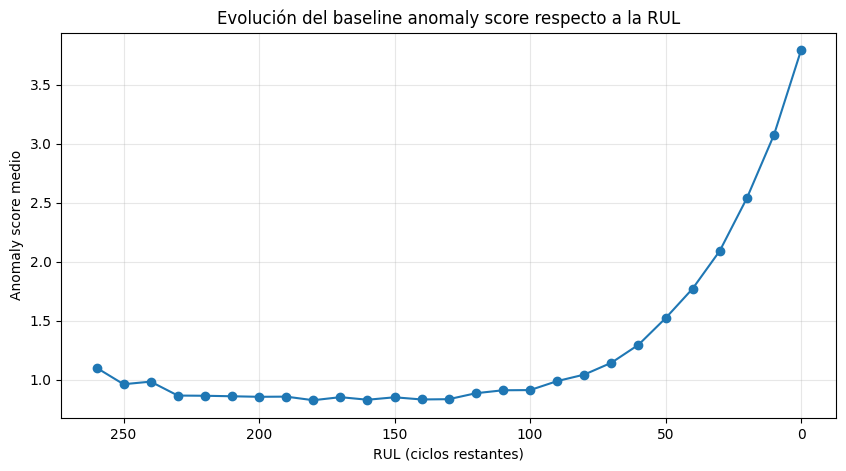

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    baseline_by_rul["RUL_bin"],
    baseline_by_rul["mean"],
    marker="o"
)

plt.xlabel("RUL (ciclos restantes)")
plt.ylabel("Anomaly score medio")
plt.title("Evolución del baseline anomaly score respecto a la RUL")

plt.grid(alpha=0.3)
plt.gca().invert_xaxis()

plt.show()

La evolución de la puntuación de anomalía muestra un comportamiento claramente relacionado con la vida útil restante de los motores.

Para valores elevados de RUL, la puntuación media se mantiene relativamente estable, generalmente alrededor de 0,8–1,0. Esto indica que, durante las etapas alejadas del final de vida, el comportamiento conjunto de los sensores permanece próximo al patrón aprendido a partir de la región inicial de referencia.

A medida que disminuye la RUL comienza a observarse un incremento progresivo de la puntuación. Este crecimiento es inicialmente moderado, pero se hace cada vez más pronunciado al aproximarse al final de vida. Por ejemplo, la puntuación media pasa de aproximadamente 0,91 para una RUL de 100 ciclos a 1,30 en 60 ciclos, 1,77 en 40 ciclos, 2,54 en 20 ciclos y 3,79 en los últimos 10 ciclos.

Por tanto, el baseline no se limita a producir valores elevados de forma aleatoria, sino que presenta una evolución coherente con el proceso de degradación: las observaciones se alejan progresivamente del comportamiento inicial de referencia conforme disminuye la vida útil restante.

También se observa que para valores de RUL muy elevados, especialmente por encima de aproximadamente 230 ciclos, la puntuación presenta algunas oscilaciones. Sin embargo, estos intervalos contienen un número considerablemente menor de observaciones que las regiones próximas al final de vida. Por ejemplo, el intervalo de RUL 260 contiene únicamente 16 observaciones, frente a las 200 observaciones disponibles en cada intervalo entre 0 y 120 ciclos. Por ello, estas variaciones iniciales deben interpretarse con cautela.

En conjunto, los resultados indican que la puntuación estadística propuesta constituye un baseline adecuado para representar la desviación progresiva del comportamiento de los sensores respecto a la referencia inicial.

Además, el comportamiento observado resulta coherente con la elección de `RUL_MAX = 120` realizada durante el preprocesamiento. En torno a esta región la puntuación comienza a abandonar progresivamente el nivel relativamente estable observado para valores elevados de RUL y su crecimiento se intensifica conforme se aproxima el final de vida. Esto no implica que 120 ciclos represente el instante físico exacto de inicio de la degradación, pero aporta evidencia adicional de que constituye una región razonable de transición para el modelado de la prognosis.

### 5.5. Relación entre anomaly score y RUL

Además del análisis visual, se calculará la correlación de Spearman entre la puntuación de anomalía y la RUL.

Esta medida permite estudiar si existe una relación monótona entre ambas variables sin asumir una relación estrictamente lineal.

Dado que una mayor degradación debería corresponderse con una menor vida útil restante, un comportamiento coherente del detector se reflejaría en una correlación negativa: puntuaciones de anomalía mayores asociadas, en términos generales, a valores menores de RUL.

In [ ]:
spearman_corr, p_value = spearmanr(
    evaluation_data["RUL"],
    evaluation_data["baseline_score"]
)

print("Correlación de Spearman:", spearman_corr)
print("p-value:", p_value)

Correlación de Spearman: -0.713620790228582
p-value: 0.0


La correlación de Spearman obtenida entre la RUL y la puntuación de anomalía es de aproximadamente -0,714, lo que indica una relación negativa fuerte entre ambas variables.

Este resultado significa que, en términos generales, las puntuaciones de anomalía tienden a aumentar conforme disminuye la vida útil restante del motor. Por tanto, la medida de desviación construida a partir del comportamiento inicial contiene información relacionada con la progresión hacia el final de vida.

El resultado es coherente con la evolución observada gráficamente, donde la puntuación permanece relativamente estable durante las regiones de RUL elevada y aumenta progresivamente, con mayor intensidad, durante las etapas próximas al final de vida.

El valor p obtenido es extremadamente pequeño y aparece representado como 0.0 debido a la precisión numérica utilizada por el software.

No obstante, esta correlación no implica que la puntuación constituya una estimación directa de la RUL ni demuestra por sí sola la existencia de un instante concreto de inicio de la degradación. Su interpretación se limita a indicar que el anomaly score presenta una evolución consistente con el deterioro progresivo de los motores.

Debe señalarse que las observaciones correspondientes a un mismo motor presentan dependencia temporal. Por tanto, el valor p calculado sobre todas las observaciones debe interpretarse con cautela y no constituye por sí solo una prueba de significación basada en observaciones independientes.

### 5.6. Análisis de trayectorias individuales

Los resultados anteriores muestran el comportamiento global del método sobre el conjunto de evaluación. Sin embargo, la utilización de valores medios puede ocultar diferencias importantes entre motores.

Por este motivo, se analizará la evolución temporal de la puntuación de anomalía en diferentes motores del conjunto de evaluación.

Este análisis permitirá comprobar si el incremento observado a nivel global también aparece en trayectorias individuales y estudiar la variabilidad existente entre motores.

In [ ]:
evaluation_lengths = (
    evaluation_data
    .groupby("unit")["cycle"]
    .max()
    .sort_values()
)

short_unit = evaluation_lengths.index[0]

median_length = evaluation_lengths.median()
median_unit = (
    (evaluation_lengths - median_length)
    .abs()
    .idxmin()
)

long_unit = evaluation_lengths.index[-1]

representative_units = [
    short_unit,
    median_unit,
    long_unit
]

print("Motor con trayectoria corta:",
      short_unit, "-", evaluation_lengths.loc[short_unit], "ciclos")

print("Motor próximo a la mediana:",
      median_unit, "-", evaluation_lengths.loc[median_unit], "ciclos")

print("Motor con trayectoria larga:",
      long_unit, "-", evaluation_lengths.loc[long_unit], "ciclos")

Motor con trayectoria corta: 91 - 135 ciclos
Motor próximo a la mediana: 1 - 192 ciclos
Motor con trayectoria larga: 5 - 269 ciclos


Para estudiar el comportamiento del método a nivel individual se han seleccionado tres motores del conjunto de evaluación en función de la longitud de sus trayectorias.

El motor 91 presenta la trayectoria más corta, con 135 ciclos; el motor 1 tiene una duración de 192 ciclos, próxima a la mediana del conjunto de evaluación; y el motor 5 presenta la trayectoria más larga, con 269 ciclos.

Esta selección permite analizar el comportamiento del anomaly score en motores con diferentes duraciones sin escoger manualmente las unidades en función de los resultados obtenidos por el detector.

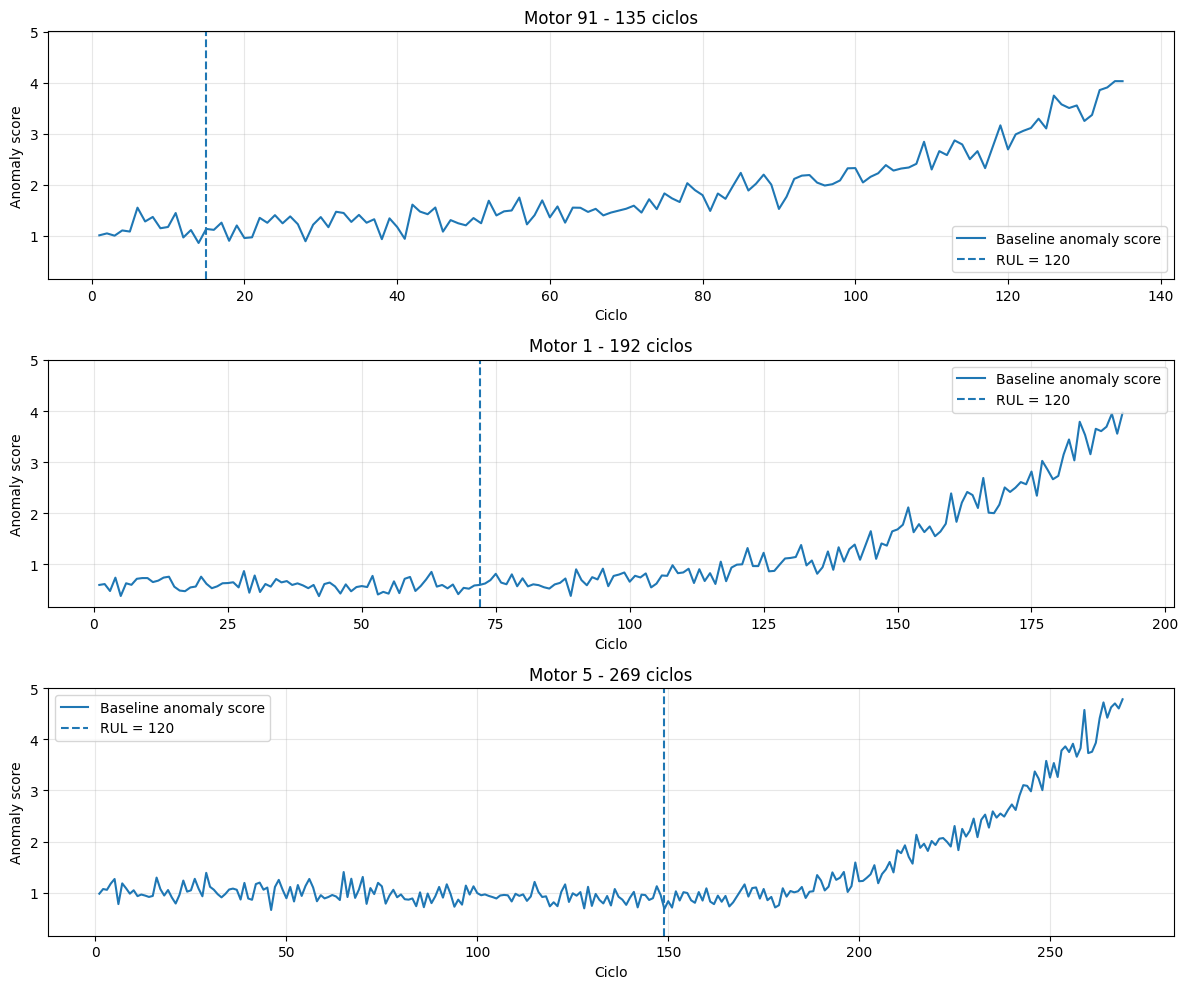

In [ ]:
fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 10),
    sharey=True
)

for ax, unit in zip(axes, representative_units):

    motor_data = (
        evaluation_data[
            evaluation_data["unit"] == unit
        ]
        .sort_values("cycle")
    )

    max_cycle = motor_data["cycle"].max()
    transition_cycle = max_cycle - 120

    ax.plot(
        motor_data["cycle"],
        motor_data["baseline_score"],
        label="Baseline anomaly score"
    )

    if transition_cycle > 0:
        ax.axvline(
            transition_cycle,
            linestyle="--",
            label="RUL = 120"
        )

    ax.set_title(
        f"Motor {unit} - {max_cycle} ciclos"
    )
    ax.set_xlabel("Ciclo")
    ax.set_ylabel("Anomaly score")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

El análisis de las trayectorias individuales permite observar que el comportamiento identificado de forma agregada también aparece en los tres motores seleccionados, que presentan diferentes duraciones de vida.

En los tres motores seleccionados, la puntuación de anomalía permanece relativamente reducida y estable durante una parte inicial de la trayectoria y aumenta progresivamente conforme el motor se aproxima al final de vida. Aunque existen oscilaciones entre ciclos consecutivos, la tendencia general de crecimiento resulta claramente visible.

El motor 91, correspondiente a la trayectoria más corta, presenta puntuaciones próximas a 1 durante los primeros ciclos. Posteriormente se observa un crecimiento progresivo que se intensifica durante la segunda mitad de la trayectoria, alcanzando valores próximos a 4 al final de su vida.

El motor 1, cuya longitud se encuentra próxima a la mediana, muestra inicialmente puntuaciones incluso inferiores a 1 y relativamente estables. A partir de etapas posteriores comienza una tendencia ascendente que se vuelve especialmente pronunciada durante los últimos ciclos, donde la puntuación se aproxima también a valores de 4.

El motor 5, que presenta la trayectoria más larga de los tres, mantiene durante un periodo considerable una puntuación aproximadamente estable alrededor de 1. Posteriormente comienza una desviación progresiva y, durante la parte final de la trayectoria, el crecimiento se intensifica hasta alcanzar valores próximos a 5.

Las diferencias en el momento y la intensidad del incremento muestran que la evolución de las puntuaciones de anomalía no es idéntica en todos los motores. Sin embargo, los tres casos presentan el mismo comportamiento general: una región inicial relativamente estable seguida de una desviación creciente respecto al patrón de referencia.

La línea correspondiente a `RUL = 120` permite comparar visualmente estas trayectorias con la región de transición utilizada para definir la RUL *piecewise*. No debe interpretarse como el instante exacto de inicio físico de la degradación. De hecho, el incremento de la puntuación es gradual y su manifestación varía entre motores.

En conjunto, estos resultados refuerzan la utilidad del baseline estadístico como indicador continuo de desviaciones respecto al comportamiento inicial, relacionadas con la proximidad al final de vida, ya que el aumento de la puntuación observado a nivel global también se reproduce en los tres motores individuales analizados, que no fueron utilizados para construir la referencia.

### 5.7. Definición de un umbral de anomalía

Hasta este punto, el método proporciona una puntuación continua que cuantifica el grado de desviación de cada observación respecto al comportamiento inicial de referencia.

Para utilizar esta información como sistema de detección es necesario establecer un criterio que permita identificar puntuaciones suficientemente elevadas como para generar una alerta.

Dado que C-MAPSS no proporciona una etiqueta real que indique el instante exacto de inicio de la degradación, el umbral no se determinará utilizando la RUL ni optimizando métricas de clasificación supervisada. En su lugar, se estimará exclusivamente a partir de la distribución de las puntuaciones obtenidas en la región de referencia de los motores de desarrollo.

Se analizarán diferentes percentiles de esta distribución. De esta forma, una observación será considerada anómala cuando su puntuación sea inusualmente elevada respecto al comportamiento utilizado para caracterizar el estado inicial de los motores.

In [ ]:
development_reference["baseline_score"] = calculate_baseline_score(
    development_reference,
    sensor_features,
    reference_mean,
    reference_std
)

print(
    development_reference["baseline_score"].describe(
        percentiles=[0.90, 0.95, 0.975, 0.99]
    )
)

count    1691.000000
mean        0.812061
std         0.239420
min         0.313328
50%         0.785912
90%         1.140202
95%         1.224189
97.5%       1.313803
99%         1.469313
max         1.685885
Name: baseline_score, dtype: float64


In [ ]:
thresholds = {
    "P90": development_reference["baseline_score"].quantile(0.90),
    "P95": development_reference["baseline_score"].quantile(0.95),
    "P97.5": development_reference["baseline_score"].quantile(0.975),
    "P99": development_reference["baseline_score"].quantile(0.99)
}

for name, value in thresholds.items():
    print(f"{name}: {value:.4f}")

P90: 1.1402
P95: 1.2242
P97.5: 1.3138
P99: 1.4693


Las observaciones utilizadas para caracterizar el comportamiento inicial presentan una puntuación media de anomalía de 0,812 y una mediana de 0,786. La mayor parte de las observaciones se concentra, por tanto, en valores relativamente reducidos del `baseline_score`.

A partir de esta distribución se han obtenido cuatro posibles umbrales de detección. El percentil 90 establece un límite de 1,140, el percentil 95 de 1,224, el percentil 97,5 de 1,314 y el percentil 99 de 1,469.

El incremento del percentil utilizado produce un criterio progresivamente más conservador. Un umbral bajo, como P90, permitirá detectar desviaciones más pequeñas respecto al comportamiento de referencia, pero también será más sensible a las fluctuaciones propias de los sensores. Por el contrario, P99 exigirá una desviación considerablemente mayor para generar una alerta.

Estos porcentajes describen el comportamiento sobre la región utilizada para construir la referencia y no permiten todavía determinar cuál de los umbrales es el más adecuado. Para ello será necesario analizar su comportamiento sobre las etapas iniciales de motores que no participaron en su definición.

#### 5.7.1. Evaluación del umbral sobre motores no vistos

Para estudiar la capacidad de generalización de los posibles umbrales, se analizará su comportamiento sobre el primer 10 % de las trayectorias de los 20 motores reservados para evaluación.

Esta región no se considerará una etiqueta real de funcionamiento normal, sino una aproximación independiente al comportamiento inicial. Se calculará el porcentaje de observaciones de esta región cuya puntuación supera cada uno de los umbrales candidatos.

Un porcentaje excesivamente elevado indicaría que el umbral se supera con frecuencia incluso durante las etapas iniciales de motores que no participaron en su definición.

In [ ]:
evaluation_reference = evaluation_data[
    evaluation_data["relative_life"] <= 0.10
].copy()

print("Observaciones iniciales de evaluación:",
      len(evaluation_reference))

print("Motores representados:",
      evaluation_reference["unit"].nunique())

Observaciones iniciales de evaluación: 415
Motores representados: 20


In [ ]:
false_alarm_results = []

for name, threshold in thresholds.items():

    percentage = (
        evaluation_reference["baseline_score"] > threshold
    ).mean() * 100

    false_alarm_results.append({
        "threshold": name,
        "value": threshold,
        "initial_exceedance_pct": percentage
    })

false_alarm_table = pd.DataFrame(false_alarm_results)

false_alarm_table

,threshold,value,initial_exceedance_pct
0,P90,1.140202,15.421687
1,P95,1.224189,7.228916
2,P97.5,1.313803,1.927711
3,P99,1.469313,0.722892


La región inicial de los motores de evaluación contiene 415 observaciones correspondientes a las 20 unidades reservadas. Al aplicar los umbrales obtenidos exclusivamente a partir de los motores de desarrollo se observan diferencias importantes entre los distintos percentiles.

El umbral P90 genera una superación en aproximadamente el 15,42 % de las observaciones iniciales. Este porcentaje resulta considerablemente superior al 10 % esperado sobre la propia región utilizada para definir el umbral, lo que indica una elevada sensibilidad ante las diferencias existentes entre motores.

El umbral P95 reduce el porcentaje de superaciones iniciales hasta aproximadamente el 7,23 %. Aunque supone una reducción importante respecto a P90, todavía se supera en un número apreciable de observaciones durante las primeras etapas de motores no utilizados para construir la referencia.

Los umbrales más conservadores presentan un comportamiento considerablemente más estable. P97,5 reduce el porcentaje de superaciones iniciales hasta aproximadamente el 1,93 %, mientras que P99 lo sitúa en únicamente el 0,72 %.

Estos resultados muestran el compromiso existente entre sensibilidad y robustez frente a variaciones iniciales entre motores. Los umbrales más bajos permiten detectar desviaciones menores, pero también generan un mayor número de superaciones durante las regiones iniciales. Por el contrario, los umbrales más elevados reducen estas posibles falsas alertas, aunque podrían retrasar la detección de la degradación.

Por tanto, el porcentaje de superaciones iniciales no es suficiente por sí solo para seleccionar el umbral definitivo. Es necesario estudiar también con cuánta anticipación detecta cada umbral la desviación sostenida de los motores respecto al comportamiento de referencia.

### 5.8. Análisis temporal de las alertas

Además de estudiar las superaciones producidas durante la región inicial, es necesario analizar en qué momento de la trayectoria comienzan a aparecer las alertas.

En primer lugar, se determinará para cada motor la primera observación cuya puntuación de anomalía supera cada uno de los umbrales candidatos. Se registrará tanto el ciclo en el que se produce como la RUL correspondiente.

Este análisis proporciona una medida exploratoria de anticipación de las primeras superaciones del umbral, pero debe interpretarse con cautela, ya que una única superación puede estar causada por una fluctuación puntual de los sensores y no necesariamente por una desviación persistente asociada al proceso de degradación.

In [ ]:
first_alert_results = []

for name, threshold in thresholds.items():

    for unit in evaluation_units:

        motor_data = (
            evaluation_data[
                evaluation_data["unit"] == unit
            ]
            .sort_values("cycle")
        )

        alerts = motor_data[
            motor_data["baseline_score"] > threshold
        ]

        if len(alerts) > 0:
            first_alert = alerts.iloc[0]

            first_alert_results.append({
                "threshold": name,
                "unit": unit,
                "first_alert_cycle": first_alert["cycle"],
                "RUL_at_first_alert": first_alert["RUL"]
            })

        else:
            first_alert_results.append({
                "threshold": name,
                "unit": unit,
                "first_alert_cycle": np.nan,
                "RUL_at_first_alert": np.nan
            })

first_alert_table = pd.DataFrame(first_alert_results)

In [ ]:
first_alert_summary = (
    first_alert_table
    .groupby("threshold")
    .agg(
        motors_detected=("RUL_at_first_alert", "count"),
        mean_RUL_first_alert=("RUL_at_first_alert", "mean"),
        median_RUL_first_alert=("RUL_at_first_alert", "median"),
        min_RUL_first_alert=("RUL_at_first_alert", "min"),
        max_RUL_first_alert=("RUL_at_first_alert", "max")
    )
    .reindex(["P90", "P95", "P97.5", "P99"])
)

first_alert_summary

,motors_detected,mean_RUL_first_alert,median_RUL_first_alert,min_RUL_first_alert,max_RUL_first_alert
threshold,,,,,
P90,20,161.50,155.5,55.0,266.0
P95,20,150.15,137.5,55.0,266.0
P97.5,20,111.20,89.5,38.0,266.0
P99,20,84.75,68.5,38.0,266.0


Los cuatro umbrales generan al menos una superación en los 20 motores del conjunto de evaluación. Sin embargo, el momento en el que aparece la primera superación varía considerablemente en función del nivel utilizado.

Como era esperable, los umbrales más sensibles producen alertas generalmente más tempranas. Con P90, la primera superación aparece con una RUL media de 161,5 ciclos y una mediana de 155,5 ciclos. P95 presenta un comportamiento similar, aunque algo más conservador, con una RUL media de 150,15 ciclos y una mediana de 137,5.

Al aumentar el umbral, las primeras superaciones se producen generalmente más cerca del final de vida. Para P97,5, la RUL media en la primera alerta disminuye hasta 111,2 ciclos y la mediana hasta 89,5. Con P99, el criterio más conservador, estos valores se reducen a 84,75 y 68,5 ciclos, respectivamente.

Sin embargo, existe una elevada variabilidad entre motores. En todos los umbrales aparece algún motor cuya primera superación se produce con una RUL de 266 ciclos. Este resultado es especialmente relevante en P97,5 y P99, ya que demuestra que incluso los umbrales más conservadores pueden presentar alguna superación aislada durante etapas muy tempranas de determinadas trayectorias.

En el extremo contrario, algunos motores no presentan su primera superación hasta valores de RUL comprendidos entre 38 y 55 ciclos. Por tanto, utilizar únicamente la primera observación que supera el umbral produce diferencias considerables entre unidades y puede confundir fluctuaciones puntuales de los sensores con una señal sostenida de degradación.

Estos resultados justifican la incorporación de un criterio de persistencia temporal. En lugar de considerar anómalo un motor por una única superación, se estudiará si exigir varias superaciones consecutivas permite reducir las alertas aisladas manteniendo una anticipación suficiente respecto al final de vida.

#### 5.8.1. Incorporación de persistencia temporal

La primera superación puntual de un umbral puede estar provocada por fluctuaciones aisladas de los sensores. Para reducir esta sensibilidad se incorporará un criterio de persistencia temporal.

Se compararán tres niveles de persistencia: una, tres y cinco observaciones consecutivas por encima del umbral. El primer caso corresponde al análisis puntual realizado anteriormente, mientras que los otros dos exigen que la desviación se mantenga durante varios ciclos antes de generar una alerta.

El objetivo es estudiar si la persistencia permite eliminar alertas tempranas aisladas sin retrasar excesivamente la identificación de una desviación sostenida.

In [ ]:
def first_persistent_alert(motor_data, threshold, consecutive_cycles):

    motor_data = motor_data.sort_values("cycle").copy()

    above_threshold = (
        motor_data["baseline_score"] > threshold
    ).astype(int)

    persistent = (
        above_threshold
        .rolling(
            window=consecutive_cycles,
            min_periods=consecutive_cycles
        )
        .sum()
        == consecutive_cycles
    )

    if persistent.any():

        # La alerta se considera confirmada en el último ciclo
        # de la secuencia consecutiva.
        alert_position = np.flatnonzero(persistent.to_numpy())[0]

        return motor_data.iloc[alert_position]

    return None

In [ ]:
persistent_results = []

for name, threshold in thresholds.items():

    for persistence in [1, 3, 5]:

        for unit in evaluation_units:

            motor_data = evaluation_data[
                evaluation_data["unit"] == unit
            ]

            alert = first_persistent_alert(
                motor_data,
                threshold,
                persistence
            )

            persistent_results.append({
                "threshold": name,
                "persistence": persistence,
                "unit": unit,
                "RUL_at_alert":
                    alert["RUL"] if alert is not None else np.nan
            })

persistent_alerts = pd.DataFrame(persistent_results)

In [ ]:
persistent_summary = (
    persistent_alerts
    .groupby(["threshold", "persistence"])
    .agg(
        motors_detected=("RUL_at_alert", "count"),
        mean_RUL=("RUL_at_alert", "mean"),
        median_RUL=("RUL_at_alert", "median"),
        min_RUL=("RUL_at_alert", "min"),
        max_RUL=("RUL_at_alert", "max")
    )
)

persistent_summary

motors_detected  mean_RUL  median_RUL  min_RUL  max_RUL
threshold persistence                                                         
P90       1                         20    161.50       155.5     55.0    266.0
          3                         20     95.85        78.5     36.0    254.0
          5                         20     75.55        63.5     34.0    156.0
P95       1                         20    150.15       137.5     55.0    266.0
          3                         20     78.30        71.0     34.0    214.0
          5                         20     66.40        59.5     32.0    156.0
P97.5     1                         20    111.20        89.5     38.0    266.0
          3                         20     67.05        59.5     32.0    154.0
          5                         20     59.85        57.0     28.0    137.0
P99       1                         20     84.75        68.5     38.0    266.0
          3                         20     58.20        53.5     28.0    114.0
          5                         20     51.90        51.0     26.0    112.0

La incorporación de persistencia temporal reduce de forma considerable la sensibilidad a superaciones aisladas del umbral. En los cuatro umbrales analizados, exigir tres o cinco ciclos consecutivos provoca que la alerta se confirme más cerca del final de vida que cuando se utiliza una única superación.

Este efecto es especialmente visible en los valores máximos de RUL. Con una única superación, los cuatro umbrales presentan alguna alerta extremadamente temprana con una RUL de 266 ciclos. Al exigir persistencia, estas alertas aisladas se reducen progresivamente. Por ejemplo, para P97,5 la RUL máxima disminuye de 266 ciclos con una única superación a 154 con tres ciclos consecutivos y a 137 con cinco. Para P99, la reducción es todavía mayor, pasando de 266 a 114 y 112 ciclos, respectivamente.

La persistencia también produce una disminución de la anticipación media. En P97,5, la RUL media en el momento de la alerta pasa de 111,2 ciclos con una única superación a 67,05 con tres ciclos y 59,85 con cinco. De forma similar, para P99 disminuye de 84,75 a 58,20 y 51,90 ciclos.

Los umbrales P90 y P95 mantienen una mayor anticipación, pero presentan también una mayor dispersión entre motores. Incluso utilizando tres ciclos consecutivos, se observan alertas con RUL máximas de 254 y 214 ciclos, respectivamente. La utilización de cinco ciclos reduce considerablemente este comportamiento, aunque también retrasa la mediana de detección hasta 63,5 ciclos para P90 y 59,5 para P95.

Por el contrario, P99 combinado con persistencia presenta el comportamiento más conservador. Con cinco ciclos consecutivos, la alerta se produce con una mediana de 51 ciclos y todos los motores son detectados entre 26 y 112 ciclos de RUL. Aunque este criterio reduce las alertas tempranas, también proporciona el menor margen de anticipación.

En conjunto, los resultados muestran que tanto el umbral como la persistencia controlan el compromiso entre sensibilidad y anticipación. Los criterios menos restrictivos permiten detectar antes las desviaciones, pero son más sensibles a fluctuaciones tempranas, mientras que los criterios más exigentes generan alertas más estables a costa de retrasar su aparición.

#### 5.8.2. Selección del criterio de alerta del baseline

A partir de los resultados obtenidos se seleccionará, para el baseline estadístico, el percentil 97,5 combinado con una persistencia de tres ciclos consecutivos.

Esta elección no representa un umbral óptimo en sentido supervisado, ya que C-MAPSS no proporciona etiquetas reales sobre el instante de inicio de la degradación. La selección se basa en el compromiso observado entre estabilidad durante las regiones iniciales y anticipación de la alerta.

El umbral P97,5 presenta únicamente un 1,93 % de superaciones individuales durante la región inicial de los motores de validación. Al exigir tres ciclos consecutivos por encima del umbral, los 20 motores de evaluación generan una alerta persistente, con una RUL media de 67,05 ciclos y una mediana de 59,5 ciclos.

En comparación, los umbrales P90 y P95 proporcionan generalmente una mayor anticipación, pero presentan una mayor frecuencia de superaciones iniciales y alertas persistentes considerablemente más tempranas en algunos motores. P99 reduce todavía más las superaciones iniciales, pero retrasa la detección.

La persistencia de tres ciclos también ofrece un compromiso respecto a cinco ciclos consecutivos, ya que permite eliminar gran parte de las superaciones aisladas sin retrasar excesivamente la generación de la alerta.

Por tanto, se utilizará P97,5 con tres ciclos consecutivos como criterio operativo del baseline para los análisis posteriores. Esta elección deberá interpretarse como una decisión metodológica basada en los datos y no como la identificación del instante físico real de inicio de la degradación.

Dado que los motores reservados se utilizan en esta etapa para comparar los criterios candidatos y seleccionar la combinación de umbral y persistencia, este conjunto desempeña también una función de validación metodológica. La combinación seleccionada se mantendrá fija en análisis posteriores, evitando reajustarla a partir de nuevos resultados.

### 5.9. Visualización del criterio de alerta

Finalmente, se representará el criterio seleccionado sobre los tres motores utilizados anteriormente como ejemplos de trayectorias corta, intermedia y larga.

Además de la puntuación continua, se mostrará el umbral P97,5 y el instante en el que se confirma la primera alerta persistente tras observar tres ciclos consecutivos por encima de dicho umbral.

Esta representación permitirá diferenciar entre las superaciones puntuales del umbral y la generación efectiva de una alerta persistente.

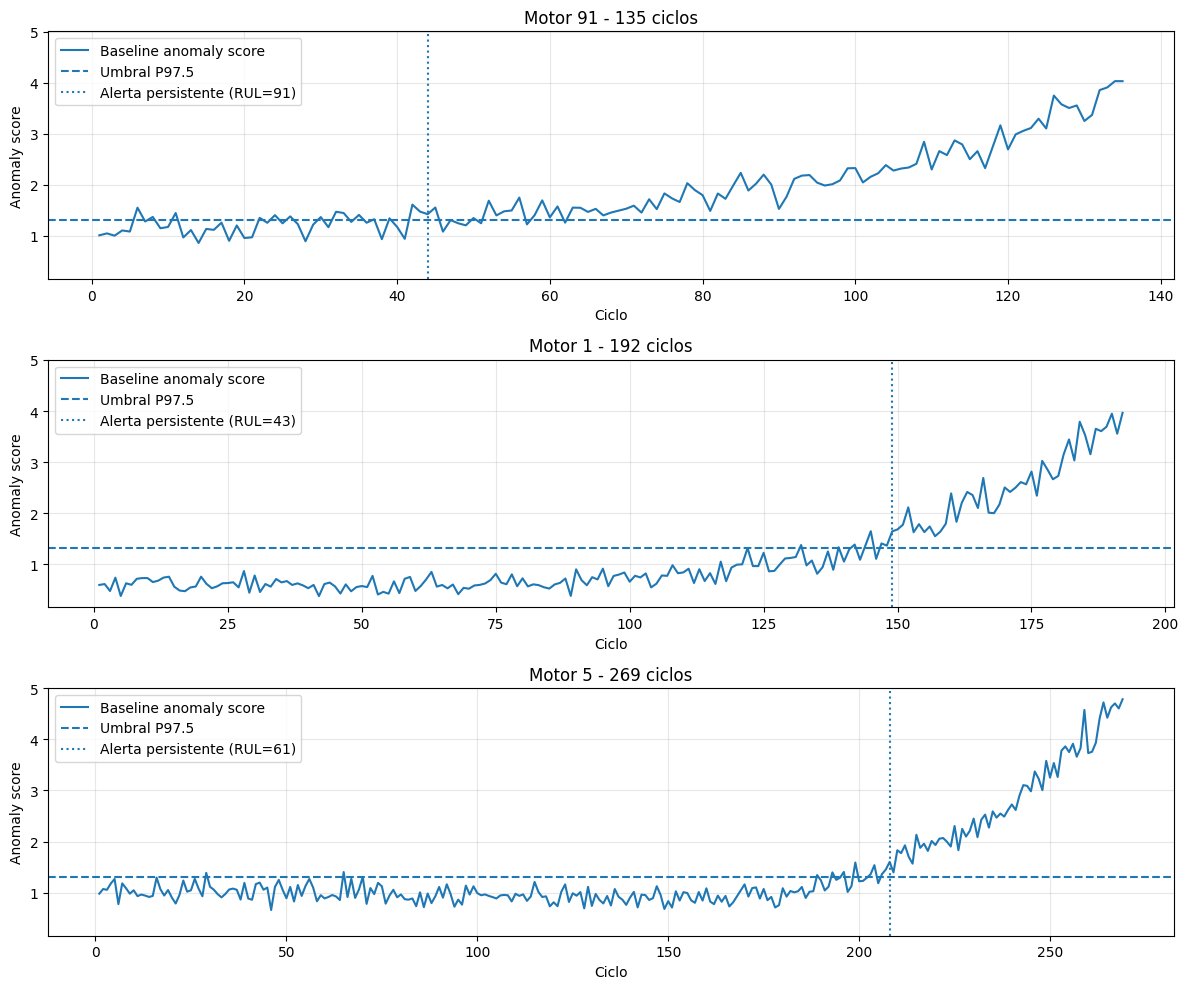

In [ ]:
selected_threshold = thresholds["P97.5"]
selected_persistence = 3

fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 10),
    sharey=True
)

for ax, unit in zip(axes, representative_units):

    motor_data = (
        evaluation_data[
            evaluation_data["unit"] == unit
        ]
        .sort_values("cycle")
    )

    alert = first_persistent_alert(
        motor_data,
        selected_threshold,
        selected_persistence
    )

    ax.plot(
        motor_data["cycle"],
        motor_data["baseline_score"],
        label="Baseline anomaly score"
    )

    ax.axhline(
        selected_threshold,
        linestyle="--",
        label="Umbral P97.5"
    )

    if alert is not None:
        ax.axvline(
            alert["cycle"],
            linestyle=":",
            label=f"Alerta persistente (RUL={int(alert['RUL'])})"
        )

    ax.set_title(
        f"Motor {unit} - {motor_data['cycle'].max()} ciclos"
    )

    ax.set_xlabel("Ciclo")
    ax.set_ylabel("Anomaly score")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

La representación de los tres motores permite observar el funcionamiento del criterio de alerta seleccionado, basado en el umbral P97,5 y en la necesidad de superar dicho valor durante tres ciclos consecutivos.

En los tres casos se observan superaciones puntuales del umbral antes de que se confirme una alerta persistente. Estas fluctuaciones no generan inmediatamente una alerta, lo que muestra la utilidad del criterio de persistencia para reducir la sensibilidad frente a desviaciones aisladas de los sensores.

En el motor 91, correspondiente a la trayectoria más corta, la alerta persistente se confirma cuando quedan 91 ciclos de RUL. Antes de este punto se observan varias superaciones aisladas del umbral que no se mantienen durante tres ciclos consecutivos. Posteriormente, aunque la puntuación vuelve a situarse por debajo del umbral en algunas ocasiones, presenta una tendencia general creciente hasta alcanzar sus valores máximos al final de la trayectoria.

El motor 1 presenta una región inicial especialmente estable, con puntuaciones generalmente inferiores al umbral durante gran parte de su vida. La alerta persistente se confirma más tarde, con una RUL de 43 ciclos, tras comenzar una fase de crecimiento más pronunciado de la puntuación.

En el motor 5, que presenta la trayectoria más larga, la puntuación permanece relativamente estable durante una parte considerable de su funcionamiento. La alerta persistente se confirma con una RUL de 61 ciclos y, a partir de ese momento, se observa un crecimiento progresivo y cada vez más pronunciado hasta el final de vida.

Los tres ejemplos muestran que el momento de generación de la alerta no es idéntico entre motores. Esto resulta coherente con la variabilidad existente entre las trayectorias y muestra que las desviaciones detectadas no evolucionan exactamente de la misma forma ni aparecen en el mismo momento en todas las unidades.

En conjunto, la combinación del umbral P97,5 con una persistencia de tres ciclos permite ignorar parte de las superaciones aisladas y confirmar una alerta cuando la puntuación supera el umbral durante tres ciclos consecutivos, aunque esto no garantiza que permanezca elevada posteriormente. El instante obtenido debe interpretarse como un criterio operativo de detección y no como una estimación del instante físico exacto de inicio del daño.

### 5.10. Conclusiones del baseline estadístico

El método estadístico desarrollado permite obtener una puntuación continua de anomalía a partir de la desviación conjunta de los 14 sensores respecto al comportamiento inicial aprendido exclusivamente de los motores de desarrollo.

El análisis realizado sobre los 20 motores reservados, no utilizados para construir la referencia estadística, muestra que la puntuación permanece relativamente estable durante las regiones alejadas del final de vida y aumenta progresivamente conforme disminuye la RUL. La correlación de Spearman entre la puntuación y la RUL fue de aproximadamente -0,714, mostrando una asociación negativa fuerte entre ambas variables.

Para transformar la puntuación continua en una posible señal de alerta se analizaron diferentes percentiles de la distribución de referencia. Los resultados mostraron el compromiso existente entre anticipación y frecuencia de superaciones durante las etapas iniciales.

También se comprobó que una única superación del umbral puede estar provocada por fluctuaciones aisladas. Por este motivo se incorporó un criterio de persistencia temporal y se compararon una, tres y cinco observaciones consecutivas por encima del umbral.

Finalmente, se seleccionó como criterio operativo del baseline el percentil 97,5 combinado con tres ciclos consecutivos. Con esta configuración, los 20 motores de evaluación presentaron una alerta persistente, con una RUL media de 67,05 ciclos y una mediana de 59,5 ciclos. Además, el umbral P97,5 presentó un 1,93 % de superaciones individuales en la región inicial de los motores de evaluación, antes de aplicar el criterio de persistencia.

La visualización de tres motores con diferentes longitudes de trayectoria permitió comprobar que el incremento de la puntuación también aparece en los ejemplos individuales analizados, aunque el momento y la intensidad de la desviación varían entre unidades.

Estos resultados permiten utilizar el método estadístico como baseline para comparar posteriormente algoritmos de detección de anomalías más complejos. El objetivo de los siguientes métodos será determinar si pueden representar la degradación y generar alertas estables con un comportamiento comparable o superior al obtenido mediante esta aproximación sencilla.

Los resultados no deben interpretarse como una identificación del instante físico exacto de inicio del daño, sino como una caracterización basada en datos de la desviación progresiva respecto al comportamiento inicial de referencia. Asimismo, debe tenerse en cuenta que los 20 motores reservados se utilizaron para comparar y seleccionar el criterio de alerta, por lo que sus resultados describen el comportamiento durante esta fase de validación metodológica.

## 6. Isolation Forest

Una vez establecido el método estadístico de referencia, se aplicará Isolation Forest como primer algoritmo de Machine Learning para la detección de anomalías.

### 6.1. Fundamento del método

Isolation Forest es un algoritmo no supervisado diseñado específicamente para la detección de anomalías. A diferencia de métodos que intentan modelar explícitamente la distribución de los datos normales, su funcionamiento se basa en aislar las observaciones mediante particiones aleatorias del espacio de características.

La idea principal es que las observaciones poco habituales tienden a ser más fáciles de aislar y, por tanto, requieren un menor número de particiones que aquellas situadas en regiones más densas y representativas del comportamiento habitual.

En este trabajo, el modelo se ajustará exclusivamente utilizando las observaciones correspondientes a la región inicial de referencia de los 80 motores de desarrollo. De esta forma, Isolation Forest aprenderá la estructura multivariante asociada al comportamiento inicial de los 14 sensores.

Posteriormente, el modelo se aplicará sobre las trayectorias completas de los motores. Las observaciones cuyo comportamiento conjunto resulte diferente al aprendido durante el ajuste deberían presentar una mayor puntuación de anomalía.

La RUL no se utilizará durante el entrenamiento ni para calcular las puntuaciones. Se empleará únicamente de forma posterior para analizar si las anomalías detectadas presentan una evolución coherente con la proximidad al final de vida.

### 6.2. Configuración inicial del modelo

El modelo se configurará con `contamination="auto"`, evitando imponer manualmente una proporción conocida de anomalías, ya que dicha proporción no está disponible en C-MAPSS. Dado que el análisis se basará inicialmente en `score_samples()` y posteriormente se definirá un criterio de alerta propio, no se utilizará directamente la clasificación binaria proporcionada por Isolation Forest.

Se utilizará una semilla fija para garantizar la reproducibilidad de los resultados.

In [ ]:
isolation_forest = IsolationForest(
    n_estimators=200,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

isolation_forest.fit(X_reference)

IsolationForest(n_estimators=200, n_jobs=-1, random_state=42)

### 6.3. Obtención de la puntuación de anomalía

Isolation Forest proporciona una puntuación continua mediante el método `score_samples()`. En su definición original, los valores más reducidos corresponden a observaciones consideradas más anómalas.

Para mantener una interpretación homogénea con el baseline estadístico y facilitar la comparación posterior entre métodos, se invertirá el signo de esta puntuación. De esta forma, en los análisis posteriores se utilizará la convención:

$$
\text{mayor puntuación} \rightarrow \text{mayor grado de anomalía}
$$

Esta transformación modifica únicamente la dirección de la escala y no altera la ordenación de las observaciones producida por el modelo.

In [ ]:
development_data["if_score"] = -isolation_forest.score_samples(
    X_development
)

evaluation_data["if_score"] = -isolation_forest.score_samples(
    X_evaluation
)

development_reference["if_score"] = -isolation_forest.score_samples(
    X_reference
)

In [ ]:
print("REFERENCIA")
print(development_reference["if_score"].describe())

print("\nDESARROLLO")
print(development_data["if_score"].describe())

print("\nEVALUACIÓN")
print(evaluation_data["if_score"].describe())

print("\nValores nulos:")
print(
    "Referencia:",
    development_reference["if_score"].isna().sum()
)
print(
    "Desarrollo:",
    development_data["if_score"].isna().sum()
)
print(
    "Evaluación:",
    evaluation_data["if_score"].isna().sum()
)

REFERENCIA
count    1691.000000
mean        0.445804
std         0.031620
min         0.377401
25%         0.423752
50%         0.441998
75%         0.463386
max         0.582564
Name: if_score, dtype: float64

DESARROLLO
count    16561.000000
mean         0.509927
std          0.096191
min          0.375943
25%          0.436533
50%          0.474435
75%          0.566120
max          0.738852
Name: if_score, dtype: float64

EVALUACIÓN
count    4070.000000
mean        0.515325
std         0.095127
min         0.378864
25%         0.441283
50%         0.481587
75%         0.577255
max         0.738852
Name: if_score, dtype: float64

Valores nulos:
Referencia: 0
Desarrollo: 0
Evaluación: 0


Isolation Forest ha generado correctamente una puntuación de anomalía para todas las observaciones, sin producir valores nulos.

La región de referencia utilizada para ajustar el modelo presenta las puntuaciones más reducidas, con una media de 0,446 y una mediana de 0,442. Además, la dispersión es relativamente pequeña, con una desviación estándar de 0,032. Este comportamiento es coherente con el hecho de que estas observaciones constituyen el patrón inicial utilizado para ajustar el modelo.

Al aplicar Isolation Forest sobre las trayectorias completas de los motores de desarrollo, la puntuación media aumenta hasta 0,510 y la dispersión hasta 0,096. Esto indica que, al considerar las trayectorias completas, aparecen observaciones que el modelo considera más diferentes respecto al comportamiento aprendido en la región inicial.

El conjunto de motores reservados presenta un comportamiento muy similar, con una puntuación media de 0,515, una mediana de 0,482 y una desviación estándar de 0,095. La similitud entre las distribuciones de desarrollo y evaluación constituye una primera indicación de que el modelo mantiene una escala de puntuaciones comparable al aplicarse sobre motores que no participaron en su ajuste.

Además, las puntuaciones máximas alcanzan aproximadamente 0,739 tanto en desarrollo como en evaluación, mientras que en la región de referencia el máximo es 0,583. Esto muestra que durante las trayectorias completas aparecen observaciones con puntuaciones de aislamiento superiores a las observadas en la región inicial de referencia.

No obstante, estas diferencias de distribución no demuestran todavía que Isolation Forest esté capturando específicamente el proceso de degradación. Para comprobarlo será necesario analizar la evolución de la puntuación respecto a la RUL y a lo largo de las trayectorias de los motores.

### 6.4. Evolución de la puntuación respecto a la RUL

Para estudiar si la puntuación generada por Isolation Forest contiene información relacionada con la progresión de la degradación, se analizará su evolución respecto a la RUL en los 20 motores reservados para evaluación, que no han sido utilizados durante el ajuste del modelo.

Al igual que en el baseline estadístico, la RUL se utilizará exclusivamente como variable externa de evaluación. El modelo no ha recibido esta información ni durante su entrenamiento ni durante el cálculo de las puntuaciones.

Las observaciones se agruparán en intervalos de 10 ciclos de RUL y se calculará la puntuación media de anomalía en cada intervalo.

Si Isolation Forest está capturando adecuadamente la desviación progresiva respecto al comportamiento inicial, se espera que las puntuaciones sean relativamente reducidas para valores elevados de RUL y aumenten conforme los motores se aproximan al final de vida.

In [ ]:
if_by_rul = (
    evaluation_data
    .groupby("RUL_bin")["if_score"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

if_by_rul

,RUL_bin,mean,std,count
0,0,0.714540,0.010613,200
1,10,0.691610,0.021827,200
2,20,0.658180,0.033766,200
3,30,0.618669,0.046980,200
4,40,0.580233,0.055623,200
5,50,0.549701,0.057219,200
6,60,0.519468,0.057533,200
7,70,0.497044,0.053896,200
8,80,0.485088,0.051641,200
9,90,0.476305,0.047258,200


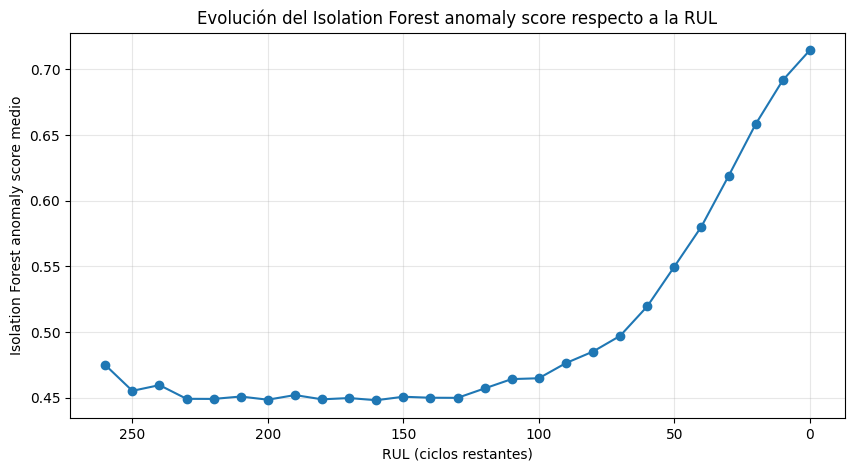

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    if_by_rul["RUL_bin"],
    if_by_rul["mean"],
    marker="o"
)

plt.xlabel("RUL (ciclos restantes)")
plt.ylabel("Isolation Forest anomaly score medio")
plt.title("Evolución del Isolation Forest anomaly score respecto a la RUL")

plt.grid(alpha=0.3)
plt.gca().invert_xaxis()

plt.show()

La puntuación de anomalía generada por Isolation Forest presenta una evolución claramente relacionada con la vida útil restante de los motores.

Para valores elevados de RUL, la puntuación media permanece relativamente estable, situándose aproximadamente en torno a 0,45. Entre valores de RUL cercanos a 230 y 130 ciclos apenas se observan variaciones importantes, lo que indica que las observaciones correspondientes a estas etapas presentan un comportamiento relativamente próximo al patrón inicial aprendido por el modelo.

A partir de aproximadamente 120 ciclos de RUL comienza a apreciarse un incremento progresivo de la puntuación. Este crecimiento es inicialmente moderado, pero se intensifica conforme los motores se aproximan al final de vida. La puntuación media pasa de aproximadamente 0,457 para una RUL de 120 ciclos a 0,465 en 100 ciclos, 0,485 en 80 ciclos, 0,519 en 60 ciclos y 0,580 en 40 ciclos y 0,658 en 20 ciclos, alcanzando aproximadamente 0,715 en el intervalo inferior a 10 ciclos de RUL.

La evolución obtenida presenta, por tanto, dos regiones diferenciadas: una primera etapa caracterizada por puntuaciones relativamente bajas y estables, seguida de una desviación progresiva y cada vez más pronunciada respecto al comportamiento inicial de referencia.

En las regiones de RUL más elevada aparecen algunas pequeñas oscilaciones, especialmente en los intervalos de 240 a 260 ciclos. Sin embargo, estos intervalos contienen un número reducido de observaciones. Por ejemplo, el intervalo de RUL 260 contiene únicamente 16 observaciones, frente a las 200 observaciones presentes en cada intervalo comprendido entre 0 y 120 ciclos. Por tanto, estas variaciones deben interpretarse con cautela.

En conjunto, los resultados indican que Isolation Forest está capturando una desviación multivariante progresiva de los sensores, con una evolución coherente con la aproximación de los motores al final de vida.

### 6.5. Relación entre Isolation Forest anomaly score y RUL

Además del análisis visual, se calculará la correlación de Spearman entre la puntuación de Isolation Forest y la RUL.

Una correlación negativa indicará que las puntuaciones de anomalía tienden a aumentar conforme disminuye la vida útil restante.

Este resultado permitirá realizar posteriormente una primera comparación cuantitativa con el baseline estadístico, para el que se obtuvo una correlación de Spearman de aproximadamente -0,714.

In [ ]:
if_spearman_corr, if_p_value = spearmanr(
    evaluation_data["RUL"],
    evaluation_data["if_score"]
)

print("Correlación de Spearman:", if_spearman_corr)
print("p-value:", if_p_value)

Correlación de Spearman: -0.7400054004932748
p-value: 0.0


La correlación de Spearman entre la puntuación de anomalía generada por Isolation Forest y la RUL es de aproximadamente -0,740, lo que indica una relación negativa fuerte entre ambas variables.

Este resultado muestra que, en términos generales, las puntuaciones asignadas por el modelo aumentan conforme disminuye la vida útil restante de los motores. Por tanto, Isolation Forest está identificando cambios en el comportamiento conjunto de los sensores que presentan una evolución coherente con la progresión hacia el final de vida.

El valor p obtenido es extremadamente pequeño y aparece representado como 0.0 debido a la precisión numérica utilizada por el software. Sin embargo, dado que las observaciones de un mismo motor presentan dependencia temporal, este valor no constituye por sí solo una prueba formal de significación basada en observaciones independientes. Por tanto, la interpretación se centrará principalmente en la dirección y magnitud de la asociación y en su comportamiento a lo largo de las trayectorias.

La magnitud de la correlación es ligeramente superior a la obtenida mediante el baseline estadístico, cuya correlación de Spearman fue aproximadamente -0,714. Esto indica que, según este criterio concreto, la puntuación de Isolation Forest presenta una asociación algo más intensa con la RUL.

Sin embargo, esta diferencia no es suficiente para determinar qué método presenta un comportamiento más adecuado como detector de anomalías. La correlación constituye únicamente uno de los criterios de evaluación y deberá complementarse con el análisis de la estabilidad durante las regiones iniciales, las trayectorias individuales y el comportamiento de las alertas.

Además, la correlación no implica que Isolation Forest esté estimando directamente la RUL ni permite identificar el instante físico exacto de inicio de la degradación, ya que esta variable no ha sido utilizada durante el entrenamiento ni durante el cálculo de las puntuaciones.

### 6.6. Análisis de trayectorias individuales

Tras analizar el comportamiento global de Isolation Forest respecto a la RUL, se estudiará la evolución de su puntuación en motores individuales.

Se utilizarán los mismos tres motores seleccionados previamente para el baseline estadístico: el motor 91, correspondiente a una trayectoria corta; el motor 1, próximo a la longitud mediana; y el motor 5, correspondiente a una trayectoria larga.

Mantener las mismas unidades permite comparar posteriormente ambos métodos bajo condiciones equivalentes y comprobar si el patrón global observado mediante Isolation Forest también aparece a nivel individual.

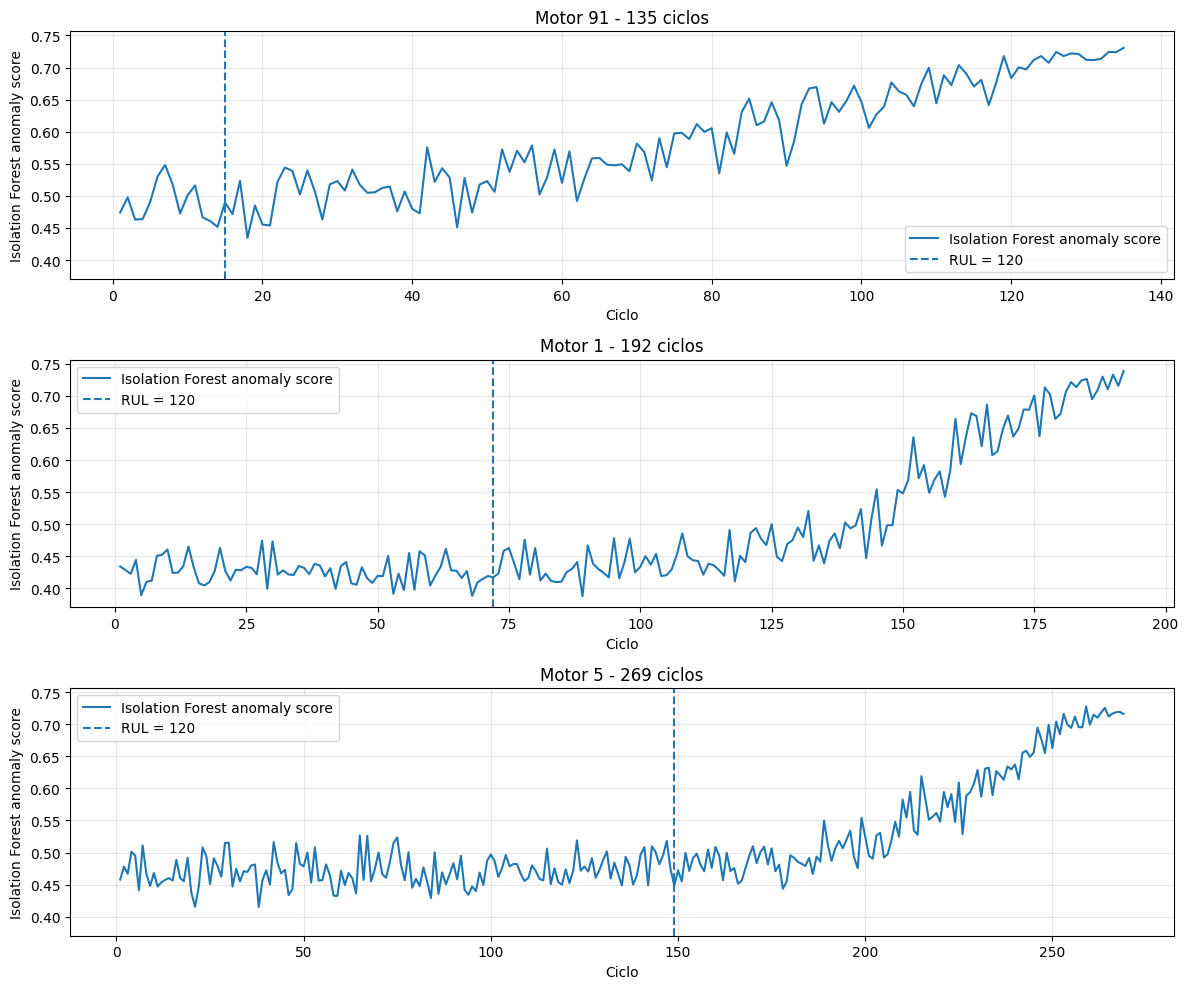

In [ ]:
fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 10),
    sharey=True
)

for ax, unit in zip(axes, representative_units):

    motor_data = (
        evaluation_data[
            evaluation_data["unit"] == unit
        ]
        .sort_values("cycle")
    )

    max_cycle = motor_data["cycle"].max()
    transition_cycle = max_cycle - 120

    ax.plot(
        motor_data["cycle"],
        motor_data["if_score"],
        label="Isolation Forest anomaly score"
    )

    if transition_cycle > 0:
        ax.axvline(
            transition_cycle,
            linestyle="--",
            label="RUL = 120"
        )

    ax.set_title(
        f"Motor {unit} - {max_cycle} ciclos"
    )

    ax.set_xlabel("Ciclo")
    ax.set_ylabel("Isolation Forest anomaly score")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

El análisis de las trayectorias individuales confirma que el patrón observado de forma global mediante Isolation Forest también aparece en motores con diferentes duraciones de vida.

En los tres motores seleccionados se observa una primera región caracterizada por puntuaciones relativamente reducidas, seguida de un incremento progresivo conforme avanza la trayectoria. Aunque las puntuaciones presentan oscilaciones entre ciclos consecutivos, la tendencia general hacia valores más elevados resulta claramente visible durante las etapas próximas al final de vida.

El motor 91, correspondiente a la trayectoria más corta, presenta una mayor variabilidad desde las primeras etapas que los otros dos motores. Aun así, la puntuación evoluciona progresivamente desde valores situados aproximadamente entre 0,45 y 0,55 hasta valores superiores a 0,70 durante los últimos ciclos. En este caso, el crecimiento de la puntuación comienza de forma gradual relativamente pronto y se mantiene durante gran parte de la trayectoria.

El motor 1 muestra una región inicial más estable, con puntuaciones situadas generalmente alrededor de 0,40–0,45 durante una parte considerable de su funcionamiento. Posteriormente comienza un crecimiento progresivo que se intensifica aproximadamente durante el último tercio de la trayectoria, alcanzando valores superiores a 0,70 al aproximarse al final de vida.

El motor 5, correspondiente a la trayectoria más larga, mantiene durante un periodo especialmente prolongado puntuaciones próximas a 0,45–0,50. Tras esta etapa relativamente estable comienza una tendencia ascendente que se hace más pronunciada durante los últimos ciclos, alcanzando igualmente valores próximos a 0,70.

La línea correspondiente a `RUL = 120` no coincide con un cambio brusco de comportamiento en ninguno de los motores. Las puntuaciones muestran una evolución generalmente gradual, lo que resulta coherente con la existencia de un proceso progresivo de desviación respecto al comportamiento inicial. Por tanto, dicho valor debe entenderse como una referencia utilizada para el modelado de la RUL *piecewise*, y no como un instante físico exacto de inicio del daño.

En conjunto, las trayectorias individuales analizadas muestran una evolución de la puntuación de Isolation Forest compatible con una desviación progresiva respecto al comportamiento inicial aprendido. También se aprecia variabilidad entre motores tanto en la magnitud de las puntuaciones como en el momento en el que comienza a observarse su crecimiento.

### 6.7. Definición de los umbrales de anomalía

Para transformar la puntuación continua de Isolation Forest en un criterio de alerta se seguirá la misma metodología utilizada con el baseline estadístico.

Los umbrales se obtendrán exclusivamente a partir de la distribución de las puntuaciones generadas sobre las 1.691 observaciones de referencia de los motores de desarrollo.

Se analizarán los percentiles 90, 95, 97,5 y 99. Este procedimiento permite comparar ambos métodos utilizando un criterio equivalente y evita depender directamente de la clasificación binaria interna proporcionada por Isolation Forest.

Posteriormente se estudiará el comportamiento de estos umbrales sobre las regiones iniciales de los 20 motores independientes de evaluación.

In [ ]:
if_thresholds = {
    "P90": development_reference["if_score"].quantile(0.90),
    "P95": development_reference["if_score"].quantile(0.95),
    "P97.5": development_reference["if_score"].quantile(0.975),
    "P99": development_reference["if_score"].quantile(0.99)
}

for name, value in if_thresholds.items():
    print(f"{name}: {value:.4f}")

P90: 0.4885
P95: 0.5044
P97.5: 0.5199
P99: 0.5382


A partir de la distribución de las puntuaciones de Isolation Forest en la región de referencia se han obtenido cuatro posibles umbrales de anomalía.

El percentil 90 establece un umbral de aproximadamente 0,489, el percentil 95 de 0,504, el percentil 97,5 de 0,520 y el percentil 99 de 0,538.

Al igual que en el baseline estadístico, el aumento del percentil genera un criterio progresivamente más conservador. Los umbrales más bajos permiten identificar desviaciones menores respecto al comportamiento aprendido, mientras que los más elevados requieren puntuaciones más alejadas de las observadas habitualmente en la región inicial.

Los valores absolutos de estos umbrales no son directamente comparables con los obtenidos mediante el baseline estadístico, ya que ambos métodos generan puntuaciones en escalas diferentes. La comparación deberá realizarse atendiendo a su comportamiento sobre los motores de evaluación, especialmente a la frecuencia de superaciones iniciales y al momento de generación de las alertas.

Por este motivo, todavía no se seleccionará un umbral definitivo para Isolation Forest.

#### 6.7.1. Evaluación de los umbrales sobre motores no vistos

Los umbrales obtenidos se aplicarán sobre la región inicial de los 20 motores reservados para evaluación interna, que no participaron en el ajuste de Isolation Forest.

Se calculará el porcentaje de observaciones iniciales cuya puntuación supera cada umbral. Este análisis permitirá estudiar la estabilidad de Isolation Forest frente a la variabilidad existente entre motores no utilizados durante su entrenamiento.

Al igual que en el baseline, estas superaciones no se interpretarán como falsos positivos reales, ya que la región inicial constituye una aproximación al comportamiento de referencia y no una etiqueta explícita de funcionamiento normal.

In [ ]:
# Actualización de la región inicial de evaluación para incluir las puntuaciones de Isolation Forest
evaluation_reference = evaluation_data[
    evaluation_data["relative_life"] <= 0.10
].copy()

print("Observaciones iniciales de evaluación:",
      len(evaluation_reference))

print("Motores representados:",
      evaluation_reference["unit"].nunique())

print("¿Existe if_score?:",
      "if_score" in evaluation_reference.columns)

Observaciones iniciales de evaluación: 415
Motores representados: 20
¿Existe if_score?: True


In [ ]:
if_initial_results = []

for name, threshold in if_thresholds.items():

    percentage = (
        evaluation_reference["if_score"] > threshold
    ).mean() * 100

    if_initial_results.append({
        "threshold": name,
        "value": threshold,
        "initial_exceedance_pct": percentage
    })

if_initial_table = pd.DataFrame(if_initial_results)

if_initial_table

,threshold,value,initial_exceedance_pct
0,P90,0.488508,15.421687
1,P95,0.504417,5.783133
2,P97.5,0.519910,1.445783
3,P99,0.538248,0.722892


Los umbrales de Isolation Forest presentan, en general, una frecuencia reducida de superaciones durante la región inicial de los 20 motores reservados, especialmente al utilizar los percentiles más elevados.

El umbral P90 es superado por aproximadamente el 15,42 % de las observaciones iniciales. Este porcentaje disminuye hasta el 5,78 % para P95, el 1,45 % para P97,5 y el 0,72 % para P99.

El comportamiento confirma el compromiso esperado entre sensibilidad y estabilidad. Los umbrales menos restrictivos permiten detectar desviaciones más pequeñas respecto al patrón aprendido, pero también producen un mayor número de superaciones durante las etapas iniciales. Por el contrario, los percentiles más elevados proporcionan un criterio más conservador.

Al comparar estos resultados con el baseline estadístico, ambos métodos presentan un comportamiento muy similar. P90 produce exactamente el mismo porcentaje de superaciones iniciales, mientras que Isolation Forest presenta porcentajes ligeramente inferiores para P95 y P97,5. En P99 ambos métodos vuelven a obtener el mismo porcentaje.

En particular, P97,5 genera un 1,45 % de superaciones iniciales con Isolation Forest frente al 1,93 % obtenido mediante el baseline. Esta diferencia corresponde a 6 y 8 observaciones, respectivamente, sobre un total de 415. Por tanto, aunque Isolation Forest presenta una frecuencia de superaciones ligeramente inferior para este criterio concreto, la diferencia es reducida y no permite establecer todavía una ventaja clara entre ambos métodos.

No obstante, estos porcentajes no son suficientes para seleccionar un umbral definitivo. Un criterio muy conservador puede reducir las superaciones iniciales a costa de retrasar excesivamente la detección. Por ello, será necesario analizar también el momento en el que se producen las alertas y el efecto de incorporar persistencia temporal.

### 6.8. Análisis de persistencia temporal

Al igual que en el baseline estadístico, una única superación del umbral de Isolation Forest podría estar provocada por una fluctuación puntual de los sensores. Por este motivo, se analizará nuevamente el efecto de exigir una, tres o cinco observaciones consecutivas por encima de cada umbral.

Mantener los mismos niveles de persistencia utilizados anteriormente permitirá realizar una comparación homogénea entre ambos métodos.

Para cada combinación de umbral y persistencia se estudiará el número de motores en los que se genera una alerta y la RUL existente en el momento de su confirmación.

In [ ]:
def first_persistent_alert_by_score(motor_data, score_column, threshold, consecutive_cycles):
    motor_data = motor_data.sort_values("cycle").copy()

    above_threshold = (
        motor_data[score_column] > threshold
    ).astype(int)

    persistent = (
        above_threshold
        .rolling(
            window=consecutive_cycles,
            min_periods=consecutive_cycles
        )
        .sum()
        == consecutive_cycles
    )

    if persistent.any():

        alert_position = np.flatnonzero(
            persistent.to_numpy()
        )[0]

        return motor_data.iloc[alert_position]

    return None

In [ ]:
if_persistent_results = []

for name, threshold in if_thresholds.items():

    for persistence in [1, 3, 5]:

        for unit in evaluation_units:

            motor_data = evaluation_data[
                evaluation_data["unit"] == unit
            ]

            alert = first_persistent_alert_by_score(
                motor_data,
                "if_score",
                threshold,
                persistence
            )

            if_persistent_results.append({
                "threshold": name,
                "persistence": persistence,
                "unit": unit,
                "RUL_at_alert":
                    alert["RUL"] if alert is not None else np.nan
            })

if_persistent_alerts = pd.DataFrame(
    if_persistent_results
)

if_persistent_summary = (
    if_persistent_alerts
    .groupby(["threshold", "persistence"])
    .agg(
        motors_detected=("RUL_at_alert", "count"),
        mean_RUL=("RUL_at_alert", "mean"),
        median_RUL=("RUL_at_alert", "median"),
        min_RUL=("RUL_at_alert", "min"),
        max_RUL=("RUL_at_alert", "max")
    )
)

if_persistent_summary

motors_detected  mean_RUL  median_RUL  min_RUL  max_RUL
threshold persistence                                                         
P90       1                         20    184.10       185.5     75.0    266.0
          3                         20     96.70        79.5     36.0    243.0
          5                         20     74.20        68.5     34.0    141.0
P95       1                         20    151.15       138.0     55.0    266.0
          3                         20     82.40        75.0     34.0    154.0
          5                         20     67.50        62.5     32.0    137.0
P97.5     1                         20    118.10       116.0     38.0    266.0
          3                         20     68.25        59.5     34.0    138.0
          5                         20     57.35        54.5     28.0    112.0
P99       1                         20     97.60        80.0     38.0    266.0
          3                         20     60.30        56.0     32.0    137.0
          5                         20     52.40        50.5     26.0    112.0

Los resultados muestran que la incorporación de persistencia temporal reduce de forma considerable las alertas extremadamente tempranas generadas por superaciones aisladas del umbral de Isolation Forest.

Con una única superación, todos los umbrales presentan una RUL máxima de 266 ciclos, lo que indica que incluso los criterios más conservadores pueden producir alguna desviación puntual durante etapas muy tempranas. Al exigir tres o cinco ciclos consecutivos, estas superaciones aisladas se reducen considerablemente.

Para P90, la RUL media de la alerta disminuye de 184,10 ciclos con una única superación a 96,70 con tres ciclos consecutivos y 74,20 con cinco. Sin embargo, utilizando tres ciclos todavía aparece una alerta especialmente temprana con una RUL de 243 ciclos.

P95 presenta un comportamiento más estable. Con tres ciclos consecutivos, la alerta se confirma con una RUL media de 82,40 ciclos y una mediana de 75, mientras que el rango se sitúa entre 34 y 154 ciclos. Al aumentar la persistencia a cinco ciclos, la RUL media disminuye hasta 67,50 ciclos.

Para P97,5, una única superación genera una RUL media de 118,10 ciclos y mantiene una alerta extrema con RUL 266. Al exigir tres ciclos consecutivos, la RUL media disminuye hasta 68,25 ciclos y la mediana hasta 59,5, con todas las alertas comprendidas entre 34 y 138 ciclos. Con cinco ciclos consecutivos, la detección se retrasa hasta una RUL media de 57,35 ciclos y una mediana de 54,5.

P99 constituye nuevamente el criterio más conservador. Utilizando tres ciclos consecutivos, la alerta aparece con una RUL media de 60,30 ciclos y una mediana de 56. Al exigir cinco ciclos, estos valores disminuyen hasta 52,40 y 50,5 ciclos, respectivamente.

En todas las combinaciones analizadas se genera una alerta antes del final de vida en los 20 motores de evaluación. Sin embargo, los resultados confirman que una única superación resulta excesivamente sensible a desviaciones puntuales, mientras que la utilización de persistencia temporal produce alertas considerablemente más estables.

En conjunto, P97,5 combinado con tres ciclos consecutivos vuelve a presentar un compromiso razonable entre estabilidad y anticipación: mantiene la detección en los 20 motores, reduce las alertas extremadamente tempranas observadas con una única superación y conserva una RUL media de 68,25 ciclos en el momento de confirmación de la alerta.

#### 6.8.1. Comparación preliminar con el baseline estadístico

La utilización de P97,5 y tres ciclos consecutivos permite realizar una comparación directa entre Isolation Forest y el baseline estadístico bajo el mismo criterio relativo de alerta.

Isolation Forest presenta un 1,45 % de superaciones en la región inicial independiente, frente al 1,93 % del baseline. Ambos métodos generan una alerta persistente en los 20 motores de evaluación y presentan prácticamente la misma anticipación: la RUL media es de 68,25 ciclos para Isolation Forest y 67,05 para el baseline, mientras que la mediana es de 59,5 ciclos en ambos casos.

La principal diferencia en la distribución de las alertas aparece en los valores máximos. Con Isolation Forest, la RUL máxima en el momento de la alerta es de 138 ciclos, frente a los 154 ciclos del baseline estadístico. Esto indica que, para esta configuración y en los motores analizados, la alerta persistente más temprana se produce más cerca del final de vida con Isolation Forest.

Además, la correlación de Spearman entre la puntuación y la RUL es ligeramente más intensa para Isolation Forest (-0,740) que para el baseline (-0,714).

Las diferencias observadas son reducidas y no permiten establecer una ventaja general de uno de los métodos. Para los criterios analizados, Isolation Forest presenta una asociación ligeramente mayor con la RUL y un porcentaje algo inferior de superaciones iniciales, mientras que ambos métodos muestran una anticipación de alerta muy similar.

#### 6.8.2. Selección del criterio de alerta de Isolation Forest

A partir de los resultados obtenidos se seleccionará también para Isolation Forest el percentil 97,5 combinado con una persistencia de tres ciclos consecutivos.

La elección se basa en el compromiso observado entre estabilidad durante las regiones iniciales y anticipación de la alerta. Con esta configuración, únicamente el 1,45 % de las observaciones pertenecientes a la región inicial independiente supera individualmente el umbral.

Al incorporar una persistencia de tres ciclos consecutivos, los 20 motores de evaluación generan una alerta, con una RUL media de 68,25 ciclos y una mediana de 59,5. Las alertas se producen entre 34 y 138 ciclos de RUL.

Los criterios menos restrictivos proporcionan una mayor anticipación, pero presentan una frecuencia superior de superaciones iniciales y una mayor sensibilidad a desviaciones tempranas. Por el contrario, P99 reduce todavía más las superaciones iniciales, pero retrasa la generación de las alertas.

Por tanto, P97,5 con tres ciclos consecutivos se utilizará como criterio operativo de Isolation Forest para los análisis posteriores. Al igual que en el baseline, esta configuración representa una decisión metodológica basada en el comportamiento de los datos y no una estimación del instante físico real de inicio de la degradación.

Al igual que en el baseline estadístico, los motores reservados se han utilizado para comparar las configuraciones candidatas y seleccionar el criterio operativo. Por tanto, estos resultados corresponden a una fase de validación metodológica y no a una evaluación completamente independiente de la selección realizada.

### 6.9. Visualización de las alertas en motores representativos

Una vez seleccionado el criterio de alerta basado en el percentil 97,5 y una persistencia de tres ciclos consecutivos, se analizará su comportamiento sobre los mismos tres motores representativos utilizados en el baseline estadístico.

Se mantienen los motores 91, 1 y 5, correspondientes respectivamente a una trayectoria corta, una trayectoria próxima a la mediana y una trayectoria larga dentro del conjunto de evaluación.

Para cada motor se representará la evolución de la puntuación de anomalía generada por Isolation Forest, el umbral seleccionado y el instante en el que se confirma por primera vez una alerta persistente.

Este análisis permite comprobar visualmente si el mecanismo de persistencia evita reaccionar ante superaciones aisladas del umbral y cómo varía el momento de detección entre motores con diferentes trayectorias de degradación.

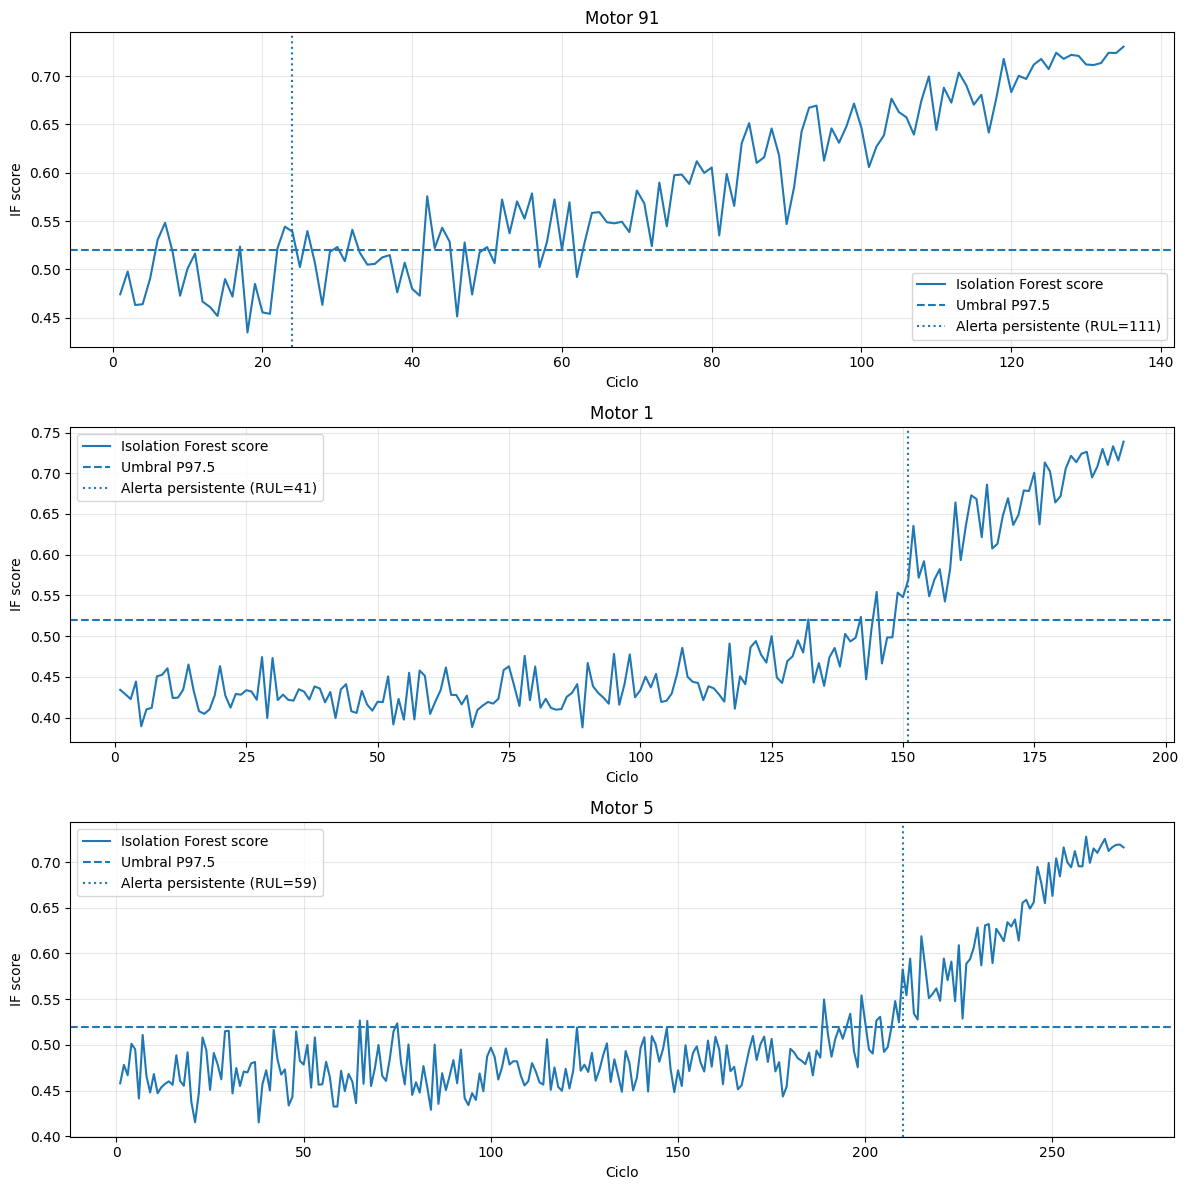

In [ ]:
selected_if_threshold = if_thresholds["P97.5"]
selected_persistence = 3

representative_units = [91, 1, 5]

fig, axes = plt.subplots(
    len(representative_units),
    1,
    figsize=(12, 12)
)

for ax, unit in zip(axes, representative_units):

    motor_data = (
        evaluation_data[
            evaluation_data["unit"] == unit
        ]
        .sort_values("cycle")
        .copy()
    )

    alert = first_persistent_alert_by_score(
        motor_data,
        "if_score",
        selected_if_threshold,
        selected_persistence
    )

    ax.plot(
        motor_data["cycle"],
        motor_data["if_score"],
        label="Isolation Forest score"
    )

    ax.axhline(
        selected_if_threshold,
        linestyle="--",
        label="Umbral P97.5"
    )

    if alert is not None:

        ax.axvline(
            alert["cycle"],
            linestyle=":",
            label=f"Alerta persistente (RUL={int(alert['RUL'])})"
        )

    ax.set_title(f"Motor {unit}")
    ax.set_xlabel("Ciclo")
    ax.set_ylabel("IF score")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

En los tres motores se observa que la puntuación de Isolation Forest permanece relativamente estable durante una parte importante de la trayectoria y aumenta conforme el motor se aproxima al final de su vida útil. Sin embargo, el momento y la forma en que comienza este incremento varían entre motores.

En el motor 91, la puntuación presenta una mayor variabilidad desde etapas tempranas y se producen varias superaciones del umbral P97,5. La condición de tres ciclos consecutivos permite evitar algunas superaciones aisladas, aunque la alerta persistente se confirma relativamente pronto, con una RUL de 111 ciclos. Posteriormente, la puntuación vuelve a situarse por debajo del umbral en algunas ocasiones, aunque mantiene una tendencia general creciente hasta el final de la trayectoria.

El motor 1 presenta un comportamiento más estable durante gran parte de su vida útil, con puntuaciones generalmente alejadas del umbral. El incremento se hace más evidente en la parte final de la trayectoria y la alerta persistente se confirma con una RUL de 41 ciclos. A partir de ese momento, la puntuación continúa aumentando de forma general hasta alcanzar sus valores máximos cerca del final de vida.

En el motor 5, correspondiente a una trayectoria más larga, la puntuación permanece estable durante numerosos ciclos y comienza a aumentar progresivamente en la etapa final. La alerta persistente se genera con una RUL de 59 ciclos, tras lo cual se observa un incremento sostenido de la puntuación de anomalía.

Las diferencias entre los tres motores muestran que las desviaciones detectadas no evolucionan exactamente de la misma forma ni aparecen en el mismo momento en todas las unidades. Aun así, Isolation Forest identifica en los tres casos una tendencia general de incremento de la puntuación conforme se aproxima el final de vida.

La aplicación de una persistencia de tres ciclos resulta especialmente relevante, ya que permite reducir la influencia de superaciones puntuales del umbral y asociar la alerta a desviaciones más sostenidas en el tiempo.

### 6.10. Conclusiones de Isolation Forest

Isolation Forest ha permitido construir un detector no supervisado de desviaciones respecto al comportamiento inicial de referencia de los motores. El modelo se ha ajustado exclusivamente utilizando las observaciones iniciales de los motores pertenecientes al conjunto de desarrollo y posteriormente se ha aplicado sobre motores no utilizados durante su entrenamiento.

La puntuación de anomalía obtenida presenta una relación clara con la evolución hacia el final de vida. En el conjunto de validación se obtuvo una correlación de Spearman de -0,740 entre la puntuación de anomalía y la RUL, indicando que las puntuaciones tienden a aumentar conforme disminuye la vida útil restante.

Para convertir esta puntuación continua en un criterio operativo de alerta se analizaron diferentes percentiles de la distribución de referencia y distintos niveles de persistencia temporal. Finalmente, se seleccionó el percentil 97,5 combinado con tres ciclos consecutivos por ofrecer un compromiso adecuado entre estabilidad y anticipación.

Con esta configuración, el 1,45 % de las observaciones pertenecientes a la región inicial de los motores de evaluación supera individualmente el umbral. Al incorporar la persistencia temporal, los 20 motores generan una alerta antes del final de su trayectoria, con una RUL media de 68,25 ciclos y una mediana de 59,5 ciclos.

En comparación con el baseline estadístico, Isolation Forest presenta resultados similares. Su puntuación muestra una correlación de Spearman de magnitud ligeramente mayor con la RUL y un porcentaje algo inferior de superaciones iniciales para P97,5, mientras que ambos métodos presentan una anticipación media de alerta prácticamente equivalente. Estas diferencias son reducidas y no permiten establecer todavía una ventaja general de un método sobre el otro.

Estos resultados muestran que Isolation Forest es capaz de representar mediante una única puntuación multivariante la desviación progresiva de los sensores respecto al comportamiento inicial aprendido. No obstante, los resultados obtenidos corresponden a una evaluación interna sobre FD001 y deberán contrastarse posteriormente con otros métodos y con datos no utilizados en esta fase de desarrollo.

## 7. One-Class SVM

Una vez evaluado Isolation Forest, se analizará un segundo algoritmo de aprendizaje no supervisado: One-Class Support Vector Machine (One-Class SVM).

One-Class SVM está diseñado para aprender la región del espacio de características correspondiente al comportamiento considerado normal a partir de un único tipo de observaciones. En este trabajo, el modelo se ajustará utilizando exclusivamente la región inicial de referencia de los motores del conjunto de desarrollo, siguiendo la misma estrategia empleada con Isolation Forest.

A diferencia de Isolation Forest, basado en el aislamiento mediante árboles aleatorios, One-Class SVM trata de construir una frontera que delimite en el espacio multivariante la región ocupada por las observaciones de referencia. Las observaciones que se alejan de dicha región pueden presentar posteriormente una mayor puntuación de anomalía.

Se utilizarán los mismos 14 sensores seleccionados durante el preprocesamiento y las mismas particiones de desarrollo y evaluación. De esta forma, los resultados podrán compararse bajo una metodología común.

La RUL no será utilizada como variable de entrada durante el entrenamiento. Se empleará únicamente de forma posterior para analizar si la puntuación generada por el modelo guarda relación con la progresión hacia el final de vida.

### 7.1. Preparación de los datos

One-Class SVM es un algoritmo sensible a la escala de las variables, ya que su funcionamiento depende de las distancias entre observaciones dentro del espacio de características.

Los sensores utilizados en este notebook se encuentran estandarizados mediante el procedimiento definido en el apartado 3.3. Aunque los datos proceden del preprocesamiento realizado en el Notebook 03, se ha ajustado un nuevo `StandardScaler` utilizando exclusivamente las observaciones de los 80 motores de desarrollo.

Este escalador se ha aplicado posteriormente a los 20 motores reservados para evaluación interna, sin utilizar sus observaciones para calcular los parámetros de normalización.

Esta separación resulta especialmente importante para One-Class SVM, ya que el algoritmo utiliza distancias entre observaciones y puede ser sensible a la escala de las variables.

Por tanto, se utilizarán directamente las matrices de entrada preparadas en el apartado 4, sin realizar nuevas transformaciones de escala.

Se mantendrán las mismas matrices utilizadas anteriormente: la región inicial de referencia de los motores de desarrollo se utilizará para ajustar el modelo, mientras que los conjuntos de desarrollo y evaluación se emplearán posteriormente para obtener las puntuaciones de anomalía.

### 7.2. Entrenamiento de One-Class SVM

El modelo se entrenará utilizando únicamente las 1.691 observaciones pertenecientes a la región inicial de referencia de los 80 motores del conjunto de desarrollo.

Se utilizará un kernel RBF para permitir la construcción de una frontera no lineal en el espacio definido por los sensores.

Como configuración inicial se utilizará `nu=0.05`. Este parámetro interviene en la regularización de la frontera y establece, entre otras propiedades, un límite superior sobre la fracción de errores de entrenamiento y un límite inferior sobre la fracción de vectores soporte. Su valor no debe interpretarse como una estimación de la proporción real de anomalías del conjunto de datos. Dado que no existen etiquetas que permitan determinar un valor óptimo directamente, se utilizará inicialmente como parámetro de configuración y su comportamiento se analizará posteriormente.

El parámetro `gamma` se establecerá como `scale`, permitiendo que su valor se determine automáticamente a partir del número de características y de la variabilidad de los datos.

In [ ]:
ocsvm = OneClassSVM(
    kernel="rbf",
    nu=0.05,
    gamma="scale"
)

ocsvm.fit(X_reference)

print("One-Class SVM entrenado correctamente.")
print("Observaciones utilizadas:", X_reference.shape[0])
print("Número de sensores:", X_reference.shape[1])

One-Class SVM entrenado correctamente.
Observaciones utilizadas: 1691
Número de sensores: 14


### 7.3. Cálculo de la puntuación de anomalía

Una vez entrenado One-Class SVM, se calculará una puntuación continua para cada observación de los conjuntos de referencia, desarrollo y evaluación.

El método `decision_function()` proporciona valores más elevados para las observaciones que se encuentran dentro de la región aprendida como normal y valores menores para aquellas que se alejan de ella. Para mantener el mismo criterio utilizado en los métodos anteriores, se invertirá el signo de esta puntuación.

De esta forma, en los tres métodos analizados se mantiene la misma interpretación: una puntuación más elevada representa una mayor desviación respecto al comportamiento inicial de referencia.

En esta fase se utilizará la puntuación continua del modelo en lugar de su clasificación binaria, ya que permite estudiar cómo evoluciona progresivamente la desviación a lo largo de la vida de cada motor.

In [ ]:
development_data["ocsvm_score"] = -ocsvm.decision_function(
    X_development
)

evaluation_data["ocsvm_score"] = -ocsvm.decision_function(
    X_evaluation
)

development_reference["ocsvm_score"] = -ocsvm.decision_function(
    X_reference
)

print("REFERENCE")
print(development_reference["ocsvm_score"].describe())

print("\nDEVELOPMENT")
print(development_data["ocsvm_score"].describe())

print("\nEVALUATION")
print(evaluation_data["ocsvm_score"].describe())

print(
    "\nValores nulos:",
    development_data["ocsvm_score"].isna().sum(),
    evaluation_data["ocsvm_score"].isna().sum()
)

REFERENCE
count    1691.000000
mean       -4.041038
std         2.351045
min        -9.483009
25%        -5.655472
50%        -4.190410
75%        -2.637845
max         5.235919
Name: ocsvm_score, dtype: float64

DEVELOPMENT
count    16561.000000
mean         0.580237
std          7.448099
min         -9.982396
25%         -4.805646
50%         -2.323768
75%          4.193090
max         17.031375
Name: ocsvm_score, dtype: float64

EVALUATION
count    4070.000000
mean        0.818024
std         7.332740
min       -10.185753
25%        -4.565402
50%        -1.952806
75%         4.429048
max        17.027361
Name: ocsvm_score, dtype: float64

Valores nulos: 0 0


La distribución de las puntuaciones muestra diferencias entre la región inicial utilizada como referencia y las trayectorias completas de los motores.

En la región de referencia, la puntuación media es de -4,04 y la mediana de -4,19. La mayor parte de estas observaciones presenta valores negativos, coherentes con una mayor proximidad a la región aprendida por One-Class SVM.

Al considerar todas las observaciones del conjunto de desarrollo, la distribución se amplía considerablemente y la puntuación media aumenta hasta 0,58. En el conjunto de evaluación se observa un comportamiento similar, con una media de 0,82. En ambos casos aparecen puntuaciones considerablemente superiores a las observadas habitualmente en la región de referencia, alcanzándose valores máximos próximos a 17.

Los conjuntos de desarrollo y evaluación presentan estadísticas descriptivas del mismo orden, aunque existen diferencias entre sus distribuciones.

Debe tenerse en cuenta que la presencia de valores negativos no representa un problema. Debido a la transformación aplicada sobre `decision_function()`, las puntuaciones más elevadas indican una mayor desviación respecto a la región aprendida como normal, independientemente de que la puntuación sea positiva o negativa.

No se han obtenido valores nulos en ninguno de los conjuntos analizados.

Estos resultados indican que One-Class SVM asigna, en general, puntuaciones mayores a las trayectorias completas que a la región inicial de referencia. Sin embargo, todavía es necesario comprobar si este incremento está relacionado de forma consistente con la progresión hacia el final de vida de los motores.

### 7.4. Relación entre la puntuación de One-Class SVM y la RUL

Para analizar si la puntuación generada por One-Class SVM refleja la progresión de la degradación, se estudiará su comportamiento en función de la vida útil restante.

Las observaciones del conjunto de evaluación se agruparán en intervalos de 10 ciclos de RUL y se calcularán la media, la desviación estándar y el número de observaciones de la puntuación de anomalía en cada intervalo.

Si el modelo captura adecuadamente la desviación progresiva respecto al comportamiento inicial, se espera observar, en términos generales, puntuaciones mayores conforme disminuye la RUL.

Este análisis no implica utilizar la RUL durante el entrenamiento del modelo. La RUL se emplea únicamente como referencia externa para evaluar posteriormente el comportamiento de la puntuación obtenida.

In [ ]:
evaluation_data["RUL_bin"] = (
    evaluation_data["RUL"] // 10
) * 10

ocsvm_by_rul = (
    evaluation_data
    .groupby("RUL_bin")["ocsvm_score"]
    .agg(["mean", "std", "count"])
    .sort_index()
)

ocsvm_by_rul

,mean,std,count
RUL_bin,,,
0,16.611308,0.456726,200
10,15.045238,1.666205,200
20,12.218920,3.220465,200
30,8.535572,4.380380,200
40,5.128661,4.694200,200
50,2.810993,4.595834,200
60,0.585117,4.066726,200
70,-1.330460,3.815385,200
80,-1.868035,3.376683,200


La puntuación generada por One-Class SVM presenta una evolución relacionada con la proximidad al final de vida de los motores.

Para valores elevados de RUL, correspondientes a etapas relativamente tempranas de las trayectorias, la puntuación media se mantiene generalmente próxima a -4, con pequeñas fluctuaciones entre intervalos. Este comportamiento es similar al observado en la región inicial utilizada para entrenar el modelo, cuya puntuación media es de -4,04.

A medida que disminuye la RUL, la puntuación comienza a aumentar progresivamente. En el intervalo de 120 ciclos se obtiene una puntuación media de -3,69, mientras que en el de 100 ciclos aumenta hasta -3,22. Posteriormente, el incremento se hace más evidente, alcanzando -1,33 en el intervalo de 70 ciclos y pasando a valores positivos en el de 60 ciclos.

Cerca del final de vida, este comportamiento resulta especialmente pronunciado. La puntuación media aumenta desde 5,13 en el intervalo de 40 ciclos hasta 8,54 en el de 30 ciclos, 12,22 en el de 20 ciclos, 15,05 en el de 10 ciclos y 16,61 en el último intervalo.

Por tanto, One-Class SVM muestra una separación progresiva entre el comportamiento inicial aprendido como referencia y las observaciones próximas al final de vida. La evolución no presenta un punto de cambio abrupto, sino una desviación gradual que se intensifica durante las últimas etapas.

Al igual que en los métodos anteriores, las pequeñas irregularidades observadas para valores muy elevados de RUL deben interpretarse con cautela, ya que estos intervalos contienen un número menor de observaciones. Los resultados tampoco permiten identificar directamente el instante físico de inicio de la degradación, sino únicamente cuantificar el alejamiento respecto al comportamiento inicial de referencia.

### 7.5. Correlación entre la puntuación de anomalía y la RUL

Para cuantificar la relación entre la puntuación generada por One-Class SVM y la vida útil restante, se calculará el coeficiente de correlación de Spearman sobre el conjunto de evaluación.

Esta medida permite analizar la existencia de una relación monótona sin asumir una relación lineal entre ambas variables.

Dado que una puntuación de anomalía elevada representa una mayor desviación respecto al comportamiento inicial y una RUL reducida indica una mayor proximidad al final de vida, se espera obtener una correlación negativa.

Este análisis se utiliza únicamente como criterio de evaluación del comportamiento del detector y no implica que One-Class SVM esté realizando directamente una estimación de la RUL.

In [ ]:
ocsvm_spearman, ocsvm_pvalue = spearmanr(
    evaluation_data["ocsvm_score"],
    evaluation_data["RUL"]
)

print("Correlación de Spearman:", ocsvm_spearman)
print("p-value:", ocsvm_pvalue)

Correlación de Spearman: -0.7079328246455546
p-value: 0.0


La puntuación generada por One-Class SVM presenta una correlación de Spearman de -0,708 con la RUL en el conjunto de evaluación.

El signo negativo indica el comportamiento esperado: las puntuaciones de anomalía tienden a aumentar conforme disminuye la vida útil restante del motor. La magnitud de la correlación refleja una asociación monótona negativa relativamente fuerte entre ambas variables.

El `p-value` obtenido se muestra numéricamente como 0 debido a su valor extremadamente pequeño. No obstante, debe interpretarse con cautela, ya que las observaciones correspondientes a un mismo motor presentan dependencia temporal.

Al comparar este resultado con los métodos anteriores, One-Class SVM presenta una correlación de menor magnitud que Isolation Forest (-0,740) y ligeramente menor que el baseline estadístico (-0,714). Estas diferencias, sin embargo, no son suficientes para determinar por sí solas el comportamiento global de los detectores.

Para completar la evaluación será necesario analizar la estabilidad de las puntuaciones durante la región inicial y el momento en el que se generan alertas persistentes.

### 7.6. Definición de los umbrales de anomalía

Para transformar la puntuación continua de One-Class SVM en un criterio de alerta, se calcularán diferentes umbrales a partir de la distribución de las puntuaciones obtenidas sobre la región inicial de referencia.

Se utilizarán los mismos percentiles empleados en los métodos anteriores: P90, P95, P97,5 y P99. De esta forma, los tres detectores podrán evaluarse siguiendo una metodología equivalente, aunque los valores numéricos de sus umbrales no sean directamente comparables debido a las diferentes escalas de sus puntuaciones.

Los umbrales se calcularán exclusivamente utilizando los motores del conjunto de desarrollo.

In [ ]:
evaluation_reference = evaluation_data[
    evaluation_data["relative_life"] <= 0.10
].copy()

print("Observaciones iniciales de evaluación:",
      len(evaluation_reference))

print("Motores representados:",
      evaluation_reference["unit"].nunique())

print("¿Existe ocsvm_score?:",
      "ocsvm_score" in evaluation_reference.columns)

Observaciones iniciales de evaluación: 415
Motores representados: 20
¿Existe ocsvm_score?: True


In [ ]:
ocsvm_initial_results = []

ocsvm_thresholds = {
    "P90": development_reference["ocsvm_score"].quantile(0.90),
    "P95": development_reference["ocsvm_score"].quantile(0.95),
    "P97.5": development_reference["ocsvm_score"].quantile(0.975),
    "P99": development_reference["ocsvm_score"].quantile(0.99)
}

for name, value in ocsvm_thresholds.items():
    print(f"{name}: {value:.4f}")

for name, threshold in ocsvm_thresholds.items():

    percentage = (
        evaluation_reference["ocsvm_score"] > threshold
    ).mean() * 100

    ocsvm_initial_results.append({
        "threshold": name,
        "value": threshold,
        "initial_exceedance_pct": percentage
    })

ocsvm_initial_table = pd.DataFrame(
    ocsvm_initial_results
)

ocsvm_initial_table

P90: -0.8724
P95: -0.0000
P97.5: 0.8233
P99: 2.0714


,threshold,value,initial_exceedance_pct
0,P90,-0.872439,13.253012
1,P95,-0.000021,6.987952
2,P97.5,0.823294,3.373494
3,P99,2.071365,1.204819


Los umbrales calculados para One-Class SVM muestran la reducción esperada de las superaciones iniciales a medida que aumenta el percentil utilizado. El porcentaje disminuye desde el 13,25 % para P90 hasta el 6,99 % para P95, el 3,37 % para P97,5 y el 1,20 % para P99.

Al comparar estos resultados con los métodos anteriores, One-Class SVM presenta el menor porcentaje de superaciones iniciales para P90. Sin embargo, para los percentiles más elevados presenta porcentajes de superación inicial superiores a los obtenidos mediante Isolation Forest.

En particular, para P97,5, One-Class SVM presenta un 3,37 % de superaciones iniciales, frente al 1,45 % obtenido con Isolation Forest y el 1,93 % del baseline estadístico. Para P99, el porcentaje disminuye hasta el 1,20 %, aunque continúa siendo ligeramente superior al 0,72 % obtenido con los otros dos métodos.

Estos resultados muestran que las diferencias entre los detectores en cuanto a la frecuencia de superaciones iniciales dependen del percentil considerado. Por tanto, no resulta adecuado seleccionar un método o un umbral únicamente a partir de este criterio. También será necesario analizar la anticipación de las alertas y el efecto de incorporar persistencia temporal.

### 7.7. Análisis de persistencia temporal

Para reducir la influencia de superaciones aisladas del umbral, se aplicará el mismo criterio de persistencia temporal utilizado con los métodos anteriores.

Se analizarán una, tres y cinco observaciones consecutivas por encima de cada uno de los cuatro umbrales considerados. Para cada combinación se estudiará el número de motores en los que se genera una alerta y la RUL existente en el momento de su confirmación.

La utilización de exactamente los mismos niveles de persistencia facilita posteriormente la comparación entre el baseline estadístico, Isolation Forest y One-Class SVM.

In [ ]:
ocsvm_persistent_results = []

for name, threshold in ocsvm_thresholds.items():

    for persistence in [1, 3, 5]:

        for unit in evaluation_units:

            motor_data = evaluation_data[
                evaluation_data["unit"] == unit
            ]

            alert = first_persistent_alert_by_score(
                motor_data,
                "ocsvm_score",
                threshold,
                persistence
            )

            ocsvm_persistent_results.append({
                "threshold": name,
                "persistence": persistence,
                "unit": unit,
                "RUL_at_alert":
                    alert["RUL"] if alert is not None else np.nan
            })

ocsvm_persistent_alerts = pd.DataFrame(
    ocsvm_persistent_results
)

ocsvm_persistent_summary = (
    ocsvm_persistent_alerts
    .groupby(["threshold", "persistence"])
    .agg(
        motors_detected=("RUL_at_alert", "count"),
        mean_RUL=("RUL_at_alert", "mean"),
        median_RUL=("RUL_at_alert", "median"),
        min_RUL=("RUL_at_alert", "min"),
        max_RUL=("RUL_at_alert", "max")
    )
)

ocsvm_persistent_summary

motors_detected  mean_RUL  median_RUL  min_RUL  max_RUL
threshold persistence                                                         
P90       1                         20    196.60       187.5    129.0    266.0
          3                         20     91.25        82.0     34.0    239.0
          5                         20     73.50        67.0     32.0    226.0
P95       1                         20    190.05       181.5    102.0    266.0
          3                         20     76.10        68.0     34.0    239.0
          5                         20     56.05        53.5     32.0    112.0
P97.5     1                         20    174.30       167.5     84.0    266.0
          3                         20     65.10        59.0     34.0    137.0
          5                         20     52.10        52.5     26.0    112.0
P99       1                         20    143.40       147.0     41.0    230.0
          3                         20     54.35        53.5     26.0    112.0
          5                         20     50.15        51.5     24.0    110.0

Los resultados muestran nuevamente la importancia de incorporar persistencia temporal al criterio de alerta. Cuando una única superación del umbral es suficiente para generar una alerta, One-Class SVM presenta detecciones muy tempranas, especialmente para los percentiles menos restrictivos.

Con P90 y una única superación, la alerta se produce con una RUL media de 196,60 ciclos y alcanza un máximo de 266 ciclos. Incluso utilizando P97,5, una única superación genera una RUL media de 174,30 ciclos. Estos resultados indican que existen desviaciones puntuales respecto a la frontera aprendida durante etapas relativamente tempranas de algunos motores.

La incorporación de tres ciclos consecutivos modifica considerablemente este comportamiento. Para P97,5, la RUL media en el momento de la alerta disminuye hasta 65,10 ciclos y la mediana hasta 59 ciclos, con un rango comprendido entre 34 y 137 ciclos. Además, los 20 motores de evaluación generan una alerta antes del final de su trayectoria.

Al aumentar la persistencia hasta cinco ciclos, las alertas se retrasan todavía más. Para P97,5, la RUL media disminuye hasta 52,10 ciclos y la mediana hasta 52,5 ciclos. Este comportamiento muestra que una persistencia mayor puede reducir la anticipación disponible para una posible actuación de mantenimiento.

P99 presenta un comportamiento más restrictivo. Con tres ciclos consecutivos, la RUL media de alerta es de 54,35 ciclos y la mediana de 53,5, mientras que con cinco ciclos estos valores disminuyen hasta 50,15 y 51,5 ciclos, respectivamente.

En conjunto, los resultados muestran que exigir tres observaciones consecutivas permite reducir considerablemente las alertas generadas por superaciones aisladas del umbral, aunque también retrasa su confirmación. La combinación P97,5 con tres ciclos consecutivos proporciona un compromiso razonable entre estabilidad inicial y anticipación dentro de las configuraciones analizadas.

### 7.8. Selección del criterio de alerta de One-Class SVM

A partir de los resultados obtenidos se selecciona el percentil 97,5 combinado con una persistencia de tres ciclos consecutivos como criterio operativo para One-Class SVM.

La elección responde al compromiso entre estabilidad durante las regiones iniciales y anticipación de la alerta. El umbral P95 permite generar alertas con mayor anticipación, pero presenta un 6,99 % de superaciones durante la región inicial y, con tres ciclos consecutivos, aparece una alerta extremadamente temprana con una RUL de 239 ciclos.

Por el contrario, P99 reduce las superaciones iniciales hasta el 1,20 %, pero retrasa la alerta hasta una RUL media de 54,35 ciclos utilizando tres observaciones consecutivas.

P97,5 se sitúa entre ambos comportamientos. Presenta un 3,37 % de superaciones iniciales y, al exigir tres ciclos consecutivos, genera una alerta en los 20 motores de evaluación. La RUL media en el momento de la alerta es de 65,10 ciclos y la mediana de 59, con un rango comprendido entre 34 y 137 ciclos.

Por tanto, P97,5 con tres ciclos consecutivos se utilizará como configuración operativa de One-Class SVM en las comparaciones posteriores. Esta selección constituye un criterio metodológico basado en el comportamiento observado y no una estimación del instante físico real de inicio de la degradación.

### 7.9. Comparación preliminar con los métodos anteriores

La aplicación de un criterio operativo equivalente, basado en el percentil 97,5 de la distribución de referencia de cada método y una persistencia de tres ciclos consecutivos, permite comparar los tres detectores bajo condiciones metodológicas homogéneas.

Los tres métodos generan una alerta en los 20 motores del conjunto de evaluación interna y presentan una anticipación muy similar. Las RUL medias en el momento de la alerta son de 67,05 ciclos para el baseline estadístico, 68,25 para Isolation Forest y 65,10 para One-Class SVM. Las medianas correspondientes son de 59,5, 59,5 y 59 ciclos, respectivamente.

Las principales diferencias aparecen en la estabilidad inicial y en la relación entre la puntuación continua y la RUL. Isolation Forest presenta el menor porcentaje de superaciones iniciales para P97,5, con un 1,45 %, frente al 1,93 % del baseline y el 3,37 % de One-Class SVM. Asimismo, presenta la correlación de Spearman de mayor magnitud (-0,740), frente a -0,714 y -0,708, respectivamente.

Por tanto, los tres métodos muestran capacidad para identificar una desviación progresiva respecto al comportamiento inicial de los motores, aunque presentan diferencias en la estabilidad y evolución de sus puntuaciones. Estas diferencias se tendrán en cuenta en la comparación final de los modelos.

### 7.10. Análisis de sensibilidad del parámetro `nu`

Hasta este punto, One-Class SVM se ha evaluado utilizando `nu=0.05` como configuración inicial. Sin embargo, dado que este parámetro influye en la frontera aprendida por el modelo, resulta conveniente comprobar si los resultados obtenidos dependen excesivamente del valor seleccionado.

Debido a la ausencia de etiquetas reales de anomalía, no es posible realizar una optimización supervisada convencional basada en métricas como accuracy, precision o recall. En su lugar, se realizará un análisis de sensibilidad utilizando varios valores de `nu`.

Se evaluarán los valores 0.01, 0.025, 0.05, 0.075 y 0.10, manteniendo el kernel RBF y `gamma="scale"`. Para cada configuración se analizará la relación entre la puntuación de anomalía y la RUL mediante la correlación de Spearman, así como la frecuencia de superaciones del umbral P97,5 durante la región inicial de los motores de evaluación.

El objetivo no es encontrar un valor matemáticamente óptimo, sino comprobar la estabilidad del comportamiento del modelo y determinar si la configuración inicial resulta razonable.

In [ ]:
nu_values = [0.01, 0.025, 0.05, 0.075, 0.10]
nu_results = []

for nu in nu_values:

    model = OneClassSVM(
        kernel="rbf",
        nu=nu,
        gamma="scale"
    )

    model.fit(X_reference)

    # Scores
    reference_score = -model.decision_function(X_reference)
    evaluation_score = -model.decision_function(X_evaluation)

    # Umbral P97.5 calculado únicamente sobre referencia
    threshold_p975 = np.quantile(reference_score, 0.975)

    # Correlación con RUL
    spearman, _ = spearmanr(
        evaluation_score,
        evaluation_data["RUL"]
    )

    # Scores correspondientes a la región inicial de los motores de evaluación
    initial_mask = (
        evaluation_data["relative_life"] <= 0.10
    )

    initial_scores = evaluation_score[initial_mask]

    initial_exceedance = (
        initial_scores > threshold_p975
    ).mean() * 100

    nu_results.append({
        "nu": nu,
        "threshold_P97.5": threshold_p975,
        "spearman": spearman,
        "initial_exceedance_pct": initial_exceedance
    })

nu_results_df = pd.DataFrame(nu_results)

nu_results_df

,nu,threshold_P97.5,spearman,initial_exceedance_pct
0,0.010,-0.060545,-0.716255,2.650602
1,0.025,0.000095,-0.709374,3.855422
2,0.050,0.823294,-0.707933,3.373494
3,0.075,2.393806,-0.716240,2.409639
4,0.100,4.683206,-0.716120,2.168675


Los resultados muestran que el comportamiento de One-Class SVM es relativamente estable frente a los diferentes valores de `nu` analizados.

La correlación de Spearman se mantiene en todos los casos aproximadamente entre -0,708 y -0,716. El valor de mayor magnitud se obtiene con `nu=0.01` (-0,716), aunque las diferencias respecto al resto de configuraciones son reducidas.

También se observan diferencias moderadas en el porcentaje de superaciones iniciales del umbral P97,5. Los valores obtenidos oscilan entre el 2,17 % y el 3,86 %, sin que exista una relación monótona clara entre el valor de `nu` y esta métrica.

Por ejemplo, `nu=0.01` presenta una correlación de Spearman de -0,716 y un 2,65 % de superaciones iniciales, mientras que `nu=0.10` obtiene una correlación de -0,716 y el menor porcentaje de superaciones iniciales, con un 2,17 %. La configuración utilizada inicialmente, `nu=0.05`, obtiene una correlación de -0,708 y un 3,37 % de superaciones iniciales.

Este análisis se plantea como un estudio de sensibilidad y no como una optimización exhaustiva de hiperparámetros. Por ello, la comparación se limita a la relación entre la puntuación y la RUL y a la frecuencia de superaciones iniciales, sin repetir para cada valor de `nu` todo el proceso de selección del criterio operativo de alerta.

En conjunto, las diferencias observadas son moderadas y no existe una configuración que presente simultáneamente el mejor comportamiento en todos los criterios analizados. Esto indica que las conclusiones obtenidas con One-Class SVM no dependen de forma crítica de haber seleccionado exactamente `nu=0.05`, dentro del rango estudiado.

Por este motivo, se mantiene `nu=0.05` como configuración de referencia para la comparación con los demás métodos. Esta decisión evita seleccionar retrospectivamente un hiperparámetro únicamente por pequeñas diferencias observadas sobre el conjunto de evaluación.

### 7.11. Conclusiones de One-Class SVM

One-Class SVM ha permitido construir un segundo detector no supervisado a partir de la región inicial de referencia de los motores del conjunto de desarrollo.

La puntuación generada por el modelo presenta una evolución progresiva conforme los motores se aproximan al final de vida. En el conjunto de evaluación se obtuvo una correlación de Spearman de -0,708 entre la puntuación de anomalía y la RUL.

Para transformar esta puntuación continua en un criterio operativo de alerta se analizaron los percentiles P90, P95, P97,5 y P99, junto con persistencias de una, tres y cinco observaciones consecutivas. Se seleccionó P97,5 con tres ciclos consecutivos como configuración de referencia.

Con este criterio, los 20 motores de evaluación generan una alerta antes del final de su trayectoria. La RUL media en el momento de la alerta es de 65,10 ciclos y la mediana de 59 ciclos, con valores comprendidos entre 34 y 137 ciclos. El porcentaje de superaciones individuales del umbral durante la región inicial de evaluación es del 3,37 %.

Finalmente, el análisis de sensibilidad realizado sobre el parámetro `nu` muestra que la asociación negativa entre la puntuación de anomalía y la RUL se mantiene para los valores analizados, comprendidos entre 0,01 y 0,10. Las correlaciones de Spearman presentan diferencias reducidas, mientras que los porcentajes de superaciones iniciales muestran variaciones moderadas. Por tanto, se mantiene `nu=0.05` como configuración de referencia, sin considerar que este análisis demuestre la estabilidad de los tiempos de alerta para todas las configuraciones.

En comparación con Isolation Forest y el baseline estadístico, One-Class SVM proporciona una anticipación similar, aunque presenta una correlación de Spearman ligeramente menor y una mayor frecuencia de superaciones iniciales para el criterio P97,5.

## 8. Autoencoder

Como tercer modelo de aprendizaje no supervisado se utilizará un Autoencoder, una arquitectura de red neuronal diseñada para aprender una representación comprimida de los datos y posteriormente reconstruir las variables originales.

En el contexto de la detección de anomalías, el modelo se entrenará utilizando exclusivamente las observaciones pertenecientes a la región inicial de referencia de los motores de desarrollo. El objetivo es que la red aprenda las relaciones multivariantes características de esta región.

Una vez entrenado, el Autoencoder se aplicará sobre las trayectorias completas de los motores. Para cada observación se calculará el error existente entre los valores originales de los sensores y los reconstruidos por la red. Este error de reconstrucción se utilizará como puntuación de anomalía.

La hipótesis de trabajo es que las observaciones similares al comportamiento utilizado durante el entrenamiento podrán reconstruirse con menor error, mientras que las observaciones que se alejen progresivamente de dicho comportamiento producirán errores de reconstrucción mayores.

Se utilizarán los mismos 14 sensores y la misma región inicial de referencia empleada con los modelos anteriores, manteniendo así una metodología común que facilite la comparación posterior.

### 8.1. Separación de entrenamiento y validación

Para entrenar el Autoencoder se utilizará nuevamente la región inicial de referencia de los motores pertenecientes al conjunto de desarrollo.

A diferencia de los modelos anteriores, el entrenamiento de una red neuronal requiere disponer de un subconjunto de validación que permita controlar la evolución del error de reconstrucción sobre datos no utilizados directamente para actualizar los pesos del modelo.

Para evitar que observaciones pertenecientes al mismo motor aparezcan simultáneamente en entrenamiento y validación, la separación se realizará a nivel de motor y no mediante una división aleatoria de observaciones.

Se reservará el 20 % de los 80 motores de desarrollo para validación interna del Autoencoder. Esta partición se utilizará únicamente durante el entrenamiento de la red neuronal. Los 20 motores del conjunto de validación definidos anteriormente continuarán sin utilizarse para el ajuste de sus pesos.

In [ ]:
reference_units = development_reference["unit"].unique()

ae_train_units, ae_val_units = train_test_split(
    reference_units,
    test_size=0.20,
    random_state=42
)

ae_train_reference = development_reference[
    development_reference["unit"].isin(ae_train_units)
].copy()

ae_val_reference = development_reference[
    development_reference["unit"].isin(ae_val_units)
].copy()

# Escalador específico para el entrenamiento del Autoencoder
scaler_ae = StandardScaler()

X_ae_train = scaler_ae.fit_transform(
    ae_train_reference[sensor_features]
)

X_ae_val = scaler_ae.transform(
    ae_val_reference[sensor_features]
)

print("Motores entrenamiento:", len(ae_train_units))
print("Motores validación:", len(ae_val_units))

print("\nObservaciones entrenamiento:", X_ae_train.shape)
print("Observaciones validación:", X_ae_val.shape)

print(
    "\nSolapamiento de motores:",
    len(set(ae_train_units) & set(ae_val_units))
)

Motores entrenamiento: 64
Motores validación: 16

Observaciones entrenamiento: (1343, 14)
Observaciones validación: (348, 14)

Solapamiento de motores: 0


La región inicial de referencia se ha dividido en 64 motores para entrenamiento y 16 motores para validación interna.

El conjunto de entrenamiento contiene 1.343 observaciones y el conjunto de validación 348 observaciones, todas ellas correspondientes a los 14 sensores seleccionados.

No existe solapamiento entre los motores utilizados en ambos conjuntos. De esta forma, la evolución de la pérdida de validación permitirá comprobar la capacidad del Autoencoder para reconstruir observaciones iniciales procedentes de motores que no participan directamente en la actualización de los pesos de la red.

Para evitar que los motores reservados para la validación interna intervengan en el cálculo de los parámetros de normalización, se ajusta un `StandardScaler` específico utilizando exclusivamente las 1.343 observaciones iniciales de los 64 motores de entrenamiento del Autoencoder. Posteriormente, este mismo escalador se aplica a las 348 observaciones de los 16 motores de validación, manteniendo así la separación entre ambos conjuntos durante el preprocesamiento.

### 8.2. Definición de la arquitectura

Se utilizará un Autoencoder completamente conectado formado por una parte codificadora y una parte decodificadora.

La entrada del modelo está formada por los 14 sensores seleccionados. El codificador reducirá progresivamente la dimensionalidad desde 14 hasta 8 y posteriormente hasta 4 neuronas, constituyendo esta última capa la representación latente o cuello de botella.

A continuación, el decodificador realizará el proceso inverso, aumentando la dimensionalidad desde 4 hasta 8 neuronas y finalmente reconstruyendo las 14 variables originales.

Las capas internas utilizarán la función de activación ReLU, mientras que la capa de salida será lineal. Esta última elección permite reconstruir libremente valores positivos y negativos, ya que los sensores utilizados como entrada se encuentran estandarizados.

El modelo se entrenará minimizando el error cuadrático medio (MSE) entre las observaciones originales y sus reconstrucciones.

In [ ]:
tf.random.set_seed(42)

autoencoder = Sequential([
    Input(shape=(len(sensor_features),)),

    Dense(8, activation="relu"),
    Dense(4, activation="relu"),

    Dense(8, activation="relu"),
    Dense(len(sensor_features), activation="linear")
])

autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

autoencoder.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │           120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 14)             │           126 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 322 (1.26 KB)

 Trainable params: 322 (1.26 KB)

 Non-trainable params: 0 (0.00 B)

El Autoencoder resultante contiene un total de 322 parámetros entrenables. La dimensionalidad se reduce desde las 14 variables de entrada hasta una representación latente de 4 dimensiones y posteriormente se reconstruye progresivamente hasta recuperar las 14 variables originales.

La arquitectura utilizada es deliberadamente compacta debido al reducido número de características de entrada y al tamaño de la región de referencia disponible para entrenamiento. Esta elección permite limitar la complejidad del modelo, aunque su comportamiento deberá comprobarse mediante la evolución de las pérdidas de entrenamiento y validación.

### 8.3. Entrenamiento del Autoencoder

El Autoencoder se entrenará utilizando las observaciones iniciales de los 64 motores asignados al conjunto de entrenamiento. Tanto las entradas como las salidas objetivo serán los mismos 14 sensores, ya que el objetivo de la red es reconstruir las observaciones originales.

Se establecerá un máximo de 200 épocas y un tamaño de lote de 32 observaciones. Para controlar el sobreajuste se utilizará `EarlyStopping`, monitorizando la pérdida sobre los 16 motores reservados para validación interna.

Si la pérdida de validación no mejora durante 15 épocas consecutivas, el entrenamiento se detendrá automáticamente. Además, se restaurarán los pesos correspondientes a la época con menor pérdida de validación.

De esta forma, el número efectivo de épocas será determinado por el comportamiento del modelo sobre datos de referencia no utilizados directamente para actualizar sus pesos.

In [ ]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

In [ ]:
history = autoencoder.fit(
    X_ae_train,
    X_ae_train,
    validation_data=(X_ae_val, X_ae_val),
    epochs=200,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=0
)

print("Épocas ejecutadas:", len(history.history["loss"]))

print(
    "Mejor pérdida de entrenamiento:",
    min(history.history["loss"])
)

print(
    "Mejor pérdida de validación:",
    min(history.history["val_loss"])
)

Épocas ejecutadas: 200
Mejor pérdida de entrenamiento: 0.3623104691505432
Mejor pérdida de validación: 0.35238659381866455


In [ ]:
best_epoch = np.argmin(history.history["val_loss"]) + 1

val_loss_actual = autoencoder.evaluate(
    X_ae_val,
    X_ae_val,
    verbose=0
)

print("Mejor época de validación:", best_epoch)
print("Mínima pérdida de validación:", min(history.history["val_loss"]))
print("Pérdida del modelo conservado:", val_loss_actual)

Mejor época de validación: 200
Mínima pérdida de validación: 0.35238659381866455
Pérdida del modelo conservado: 0.35238659381866455


El Autoencoder completó las 200 épocas establecidas como máximo, sin que se produjera una parada anticipada mediante `EarlyStopping`. La menor pérdida registrada sobre el conjunto de entrenamiento fue aproximadamente 0,362, mientras que la menor pérdida de validación fue aproximadamente 0,352.

Las pérdidas mínimas de entrenamiento y validación presentan valores próximos. No obstante, esta proximidad no permite descartar por sí sola la existencia de sobreajuste, por lo que será necesario examinar la evolución de ambas curvas durante el entrenamiento.

El mecanismo de `EarlyStopping` se configuró para supervisar la pérdida de validación, con una paciencia de 15 épocas y la opción `restore_best_weights=True`. En esta ejecución no se alcanzó el criterio de parada anticipada antes de completar las 200 épocas.

La comprobación adicional confirma que la menor pérdida de validación se alcanzó en la época 200 y que el modelo conserva los pesos correspondientes a dicha época, con una pérdida de validación de aproximadamente 0,352.

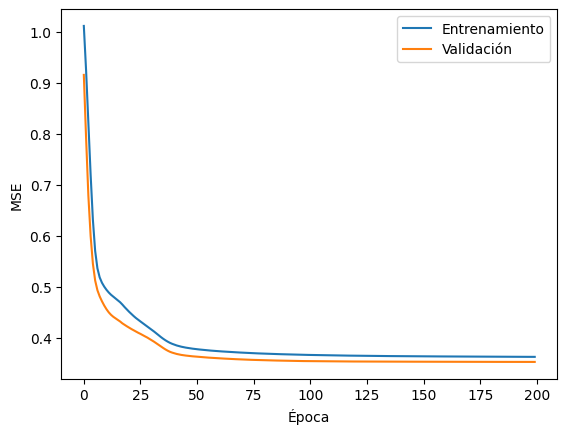

In [ ]:
plt.plot(history.history["loss"], label="Entrenamiento")
plt.plot(history.history["val_loss"], label="Validación")
plt.xlabel("Época")
plt.ylabel("MSE")
plt.legend()
plt.show()

La representación de las curvas de aprendizaje muestra una disminución pronunciada de las pérdidas de entrenamiento y validación durante las primeras épocas, seguida de una reducción progresivamente más gradual. A partir de aproximadamente la época 50, ambas curvas comienzan a estabilizarse, alcanzando valores próximos a 0,362 en entrenamiento y 0,352 en validación al finalizar el proceso.

Las pérdidas mantienen una evolución similar durante todo el entrenamiento y no presentan una divergencia progresiva que sugiera un sobreajuste evidente. La pérdida de validación se sitúa ligeramente por debajo de la de entrenamiento durante buena parte del proceso, aunque las diferencias entre ambas son reducidas.

El entrenamiento alcanza las 200 épocas establecidas como máximo sin activar la parada anticipada. La menor pérdida de validación se obtiene precisamente en la última época, por lo que el modelo conserva los pesos correspondientes a dicha época. Aunque las mejoras durante las últimas etapas son pequeñas, la pérdida continúa disminuyendo ligeramente.

Estos resultados muestran que el Autoencoder consigue reducir el error de reconstrucción sobre las observaciones iniciales utilizadas durante el entrenamiento y la validación interna. Sin embargo, será necesario comprobar posteriormente si dicho error aumenta conforme los motores se aproximan al final de vida.

### 8.4. Cálculo del error de reconstrucción

Una vez entrenado el Autoencoder, se utilizará el error de reconstrucción como puntuación continua de anomalía.

Para cada observación, el modelo genera una reconstrucción de los 14 sensores de entrada. Posteriormente, se calcula el error cuadrático medio entre los valores originales y los valores reconstruidos.

De esta forma, cada ciclo queda asociado a una única puntuación de anomalía. Las observaciones similares a los patrones aprendidos durante el entrenamiento deberían presentar errores reducidos, mientras que aquellas que se alejen de dichos patrones deberían producir errores de reconstrucción mayores.

Esta puntuación mantiene la misma interpretación utilizada en los modelos anteriores: valores más elevados representan una mayor desviación respecto al comportamiento inicial de referencia.

In [ ]:
X_reference_ae = scaler_ae.transform(
    development_reference[sensor_features]
)

X_development_ae = scaler_ae.transform(
    development_data[sensor_features]
)

X_evaluation_ae = scaler_ae.transform(
    evaluation_data[sensor_features]
)


reference_reconstructed = autoencoder.predict(
    X_reference_ae,
    verbose=0
)

development_reconstructed = autoencoder.predict(
    X_development_ae,
    verbose=0
)

evaluation_reconstructed = autoencoder.predict(
    X_evaluation_ae,
    verbose=0
)

In [ ]:
development_reference["ae_score"] = np.mean(
    np.square(
        X_reference_ae - reference_reconstructed
    ),
    axis=1
)

development_data["ae_score"] = np.mean(
    np.square(
        X_development_ae - development_reconstructed
    ),
    axis=1
)

evaluation_data["ae_score"] = np.mean(
    np.square(
        X_evaluation_ae - evaluation_reconstructed
    ),
    axis=1
)

In [ ]:
print("REFERENCE")
print(
    development_reference["ae_score"].describe()
)

print("\nDEVELOPMENT")
print(
    development_data["ae_score"].describe()
)

print("\nEVALUATION")
print(
    evaluation_data["ae_score"].describe()
)

print(
    "\nValores nulos:",
    development_reference["ae_score"].isna().sum(),
    development_data["ae_score"].isna().sum(),
    evaluation_data["ae_score"].isna().sum()
)

REFERENCE
count    1691.000000
mean        0.359611
std         0.163479
min         0.050156
25%         0.240410
50%         0.336212
75%         0.447482
max         1.117640
Name: ae_score, dtype: float64

DEVELOPMENT
count    16561.000000
mean         0.533682
std          0.711119
min          0.034206
25%          0.272441
50%          0.389623
75%          0.555841
max         24.895677
Name: ae_score, dtype: float64

EVALUATION
count    4070.000000
mean        0.504549
std         0.481135
min         0.028689
25%         0.274924
50%         0.390241
75%         0.559775
max         6.787716
Name: ae_score, dtype: float64

Valores nulos: 0 0 0


La distribución del error de reconstrucción muestra diferencias entre la región inicial de referencia y las trayectorias completas de los motores.

En la región inicial de referencia, el error medio es de aproximadamente 0,360 y la mediana de 0,336. Además, el 75 % de las observaciones presenta un error inferior o igual a aproximadamente 0,447.

Al considerar las trayectorias completas, los errores presentan una mayor dispersión. En el conjunto de desarrollo, el error medio aumenta hasta 0,534 y la mediana hasta 0,390, mientras que en el conjunto de evaluación se obtienen valores de 0,505 y 0,390, respectivamente.

Los valores centrales de las distribuciones de desarrollo y evaluación son similares. Sus medianas se sitúan aproximadamente en 0,390 en ambos conjuntos, mientras que el percentil 75 alcanza valores de 0,556 y 0,560, respectivamente. Sin embargo, aparecen diferencias en las colas de las distribuciones, alcanzándose valores máximos de 24,896 en desarrollo y 6,788 en evaluación.

La presencia de errores superiores a los observados en la región inicial indica que determinadas observaciones de las trayectorias completas presentan una mayor dificultad de reconstrucción respecto a los patrones aprendidos por el Autoencoder. No obstante, estos resultados no permiten atribuir todavía dicho incremento a la proximidad al final de vida.

Para comprobarlo, será necesario analizar cómo evoluciona el error de reconstrucción en función de la RUL de los motores.

### 8.5. Relación entre el error de reconstrucción y la RUL

Para comprobar si el error de reconstrucción refleja la evolución de la degradación, se analizará su comportamiento en función de la vida útil restante de los motores.

Las observaciones del conjunto de evaluación se agruparán nuevamente en intervalos de 10 ciclos de RUL. Para cada intervalo se calcularán la media, la desviación estándar y el número de observaciones del error de reconstrucción.

Si el Autoencoder ha aprendido adecuadamente los patrones característicos de la región inicial, se espera que las observaciones correspondientes a etapas tempranas presenten errores relativamente reducidos y que estos aumenten progresivamente conforme los motores se aproximan al final de vida.

La RUL continúa utilizándose únicamente como variable externa de evaluación y no forma parte de las entradas utilizadas para entrenar el Autoencoder.

In [ ]:
ae_by_rul = (
    evaluation_data
    .groupby("RUL_bin")["ae_score"]
    .agg(["mean", "std", "count"])
    .sort_index()
)

ae_by_rul

,mean,std,count
RUL_bin,,,
0,1.541489,1.266709,200
10,1.012817,0.756640,200
20,0.760894,0.489580,200
30,0.611741,0.340011,200
40,0.498341,0.250690,200
50,0.481048,0.243950,200
60,0.435148,0.192939,200
70,0.362134,0.178463,200
80,0.406943,0.175389,200


El error de reconstrucción del Autoencoder presenta una evolución relacionada con la proximidad al final de vida de los motores, aunque el incremento no es uniforme a lo largo de las trayectorias.

Para valores elevados de RUL, el error medio permanece relativamente estable y próximo al observado en la región inicial de referencia. Entre aproximadamente 130 y 230 ciclos de RUL, los valores medios se sitúan generalmente entre 0,35 y 0,39, sin mostrar una tendencia clara de crecimiento.

A medida que disminuye la RUL, comienzan a observarse incrementos del error de reconstrucción. En el intervalo de 100 ciclos, el error medio es de aproximadamente 0,368, aumentando hasta 0,407 en 80 ciclos, 0,435 en 60 ciclos y 0,498 en 40 ciclos. No obstante, existen fluctuaciones entre intervalos consecutivos, por lo que esta evolución no es estrictamente monótona.

El incremento se hace más evidente durante las últimas etapas de las trayectorias. El error medio alcanza aproximadamente 0,612 para el intervalo de 30 ciclos de RUL, 0,761 para 20 ciclos, 1,013 para 10 ciclos y 1,541 en el último intervalo antes del final de vida.

En conjunto, las observaciones alejadas del final de vida presentan errores de reconstrucción relativamente estables, mientras que el error tiende a aumentar conforme disminuye la RUL, especialmente durante las últimas etapas de las trayectorias. Este comportamiento es compatible con un alejamiento progresivo respecto a los patrones multivariantes aprendidos por el Autoencoder.

Las fluctuaciones observadas deben interpretarse con cautela. Además, los intervalos correspondientes a valores elevados de RUL contienen un menor número de observaciones, lo que limita la estabilidad de sus estimaciones. Los resultados tampoco permiten identificar directamente el instante físico de inicio de la degradación, sino caracterizar las desviaciones respecto al comportamiento inicial de referencia.

### 8.6. Correlación entre el error de reconstrucción y la RUL

Para cuantificar la relación entre el error de reconstrucción generado por el Autoencoder y la vida útil restante, se calculará nuevamente el coeficiente de correlación de Spearman sobre los motores del conjunto de evaluación.

Dado que errores de reconstrucción elevados representan una mayor desviación respecto al comportamiento inicial y valores reducidos de RUL indican una mayor proximidad al final de vida, se espera obtener una correlación negativa.

Esta métrica permitirá además comparar el comportamiento monotónico de la puntuación del Autoencoder con las puntuaciones obtenidas mediante el baseline estadístico, Isolation Forest y One-Class SVM.

In [ ]:
ae_spearman, ae_pvalue = spearmanr(
    evaluation_data["ae_score"],
    evaluation_data["RUL"]
)

print("Correlación de Spearman:", ae_spearman)
print("p-value:", ae_pvalue)

Correlación de Spearman: -0.38665158670904604
p-value: 2.933814335148549e-145


El error de reconstrucción del Autoencoder presenta una correlación de Spearman de aproximadamente -0,387 con la RUL en el conjunto de evaluación.

El signo negativo indica que existe una asociación inversa entre ambas variables: los errores de reconstrucción tienden a aumentar conforme disminuye la vida útil restante. Sin embargo, la magnitud de esta asociación es moderada y refleja que la relación no es marcadamente monótona al considerar todas las observaciones.

El `p-value` obtenido es aproximadamente 2,93 × 10⁻¹⁴⁵. No obstante, debido al carácter temporal de los datos y a la dependencia entre las observaciones pertenecientes a un mismo motor, este valor no constituye por sí solo una prueba formal de significación basada en observaciones independientes. Por ello, el análisis se centrará principalmente en la dirección y magnitud de la correlación y en la evolución del error a lo largo de las trayectorias.

La magnitud de la correlación es inferior a la obtenida mediante el baseline estadístico (-0,714), Isolation Forest (-0,740) y One-Class SVM (-0,708).

Este resultado es coherente con la evolución observada por intervalos de RUL. El Autoencoder mantiene errores relativamente estables durante buena parte de las etapas alejadas del final de vida y presenta un incremento más marcado durante los últimos ciclos. Dado que la correlación de Spearman evalúa la asociación monótona considerando todas las observaciones, un incremento pronunciado cerca del final de vida no implica necesariamente una correlación elevada.

En consecuencia, la correlación constituye únicamente uno de los criterios de comparación. Será necesario analizar también la frecuencia de superaciones durante la región inicial y el comportamiento de las alertas al incorporar persistencia temporal.

### 8.7. Definición de los umbrales de anomalía

Para transformar el error de reconstrucción en un criterio operativo de alerta, se calcularán diferentes umbrales a partir de la distribución de errores obtenida sobre la región inicial de referencia de los motores de desarrollo.

Se utilizarán nuevamente los percentiles P90, P95, P97,5 y P99, manteniendo la misma metodología aplicada al baseline estadístico, Isolation Forest y One-Class SVM.

Los valores absolutos de estos umbrales no son directamente comparables con los de los modelos anteriores, ya que cada detector genera su puntuación de anomalía en una escala diferente.

In [ ]:
evaluation_reference = evaluation_data[
    evaluation_data["relative_life"] <= 0.10
].copy()

print("Observaciones iniciales de evaluación:",
      len(evaluation_reference))

print("Motores representados:",
      evaluation_reference["unit"].nunique())

print("¿Existe ae_score?:",
      "ae_score" in evaluation_reference.columns)

Observaciones iniciales de evaluación: 415
Motores representados: 20
¿Existe ae_score?: True


In [ ]:
ae_initial_results = []

ae_thresholds = {
    "P90": development_reference["ae_score"].quantile(0.90),
    "P95": development_reference["ae_score"].quantile(0.95),
    "P97.5": development_reference["ae_score"].quantile(0.975),
    "P99": development_reference["ae_score"].quantile(0.99)
}

for name, value in ae_thresholds.items():
    print(name, ":", value)

for name, threshold in ae_thresholds.items():

    percentage = (
        evaluation_reference["ae_score"] > threshold
    ).mean() * 100

    ae_initial_results.append({
        "threshold": name,
        "value": threshold,
        "initial_exceedance_pct": percentage
    })

ae_initial_table = pd.DataFrame(ae_initial_results)

ae_initial_table

P90 : 0.5731770845188418
P95 : 0.6629479975999293
P97.5 : 0.7463325579869057
P99 : 0.861681212451769


,threshold,value,initial_exceedance_pct
0,P90,0.573177,12.048193
1,P95,0.662948,4.819277
2,P97.5,0.746333,2.409639
3,P99,0.861681,0.722892


Los umbrales obtenidos a partir de la región inicial de referencia son aproximadamente 0,573 para P90, 0,663 para P95, 0,746 para P97,5 y 0,862 para P99.

Al aplicar estos umbrales sobre las 415 observaciones pertenecientes a la región inicial de los 20 motores de evaluación, el porcentaje de superaciones disminuye conforme aumenta el percentil utilizado. Se obtiene un 12,05 % para P90, un 4,82 % para P95, un 2,41 % para P97,5 y un 0,72 % para P99.

Para P97,5, el Autoencoder presenta un porcentaje de superaciones iniciales del 2,41 %, frente al 1,93 % obtenido mediante el baseline estadístico, el 1,45 % de Isolation Forest y el 3,37 % de One-Class SVM. Para P99, el porcentaje disminuye hasta el 0,72 %, coincidiendo con los resultados del baseline e Isolation Forest para este percentil.

Estos resultados permiten caracterizar la frecuencia con la que las observaciones de la región inicial de evaluación superan los distintos umbrales definidos a partir de la referencia de desarrollo. Sin embargo, este criterio por sí solo no permite seleccionar una configuración de alerta, ya que un umbral con pocas superaciones iniciales podría generar alertas más tardías.

Por tanto, será necesario analizar conjuntamente el momento en el que se producen las primeras alertas y el efecto de exigir varias superaciones consecutivas mediante un criterio de persistencia temporal.

### 8.8. Análisis de persistencia temporal

Al igual que en los detectores anteriores, una única observación con un error de reconstrucción superior al umbral podría corresponder a una desviación puntual y no necesariamente a un cambio persistente en el comportamiento del motor.

Por este motivo, se evaluará nuevamente el efecto de exigir una, tres o cinco observaciones consecutivas por encima de cada umbral.

Para cada combinación se analizará el número de motores en los que se genera una alerta y la RUL disponible en el momento de su confirmación. El uso de los mismos criterios permite mantener una metodología homogénea para la posterior comparación entre los diferentes detectores.

In [ ]:
ae_persistent_results = []

for name, threshold in ae_thresholds.items():

    for persistence in [1, 3, 5]:

        for unit in evaluation_units:

            motor_data = evaluation_data[
                evaluation_data["unit"] == unit
            ]

            alert = first_persistent_alert_by_score(
                motor_data,
                "ae_score",
                threshold,
                persistence
            )

            ae_persistent_results.append({
                "threshold": name,
                "persistence": persistence,
                "unit": unit,
                "RUL_at_alert":
                    alert["RUL"] if alert is not None else np.nan
            })

ae_persistent_alerts = pd.DataFrame(
    ae_persistent_results
)

ae_persistent_summary = (
    ae_persistent_alerts
    .groupby(["threshold", "persistence"])
    .agg(
        motors_detected=("RUL_at_alert", "count"),
        mean_RUL=("RUL_at_alert", "mean"),
        median_RUL=("RUL_at_alert", "median"),
        min_RUL=("RUL_at_alert", "min"),
        max_RUL=("RUL_at_alert", "max")
    )
)

ae_persistent_summary

motors_detected    mean_RUL  median_RUL  min_RUL  \
threshold persistence                                                     
P90       1                         20  194.450000       188.5    105.0   
          3                         19   44.315789        45.0      5.0   
          5                         14   22.285714        26.0      1.0   
P95       1                         20  178.950000       182.0     77.0   
          3                         15   36.000000        43.0      5.0   
          5                         12   21.666667        29.0      1.0   
P97.5     1                         20  167.800000       170.0     61.0   
          3                         14   26.785714        29.5      0.0   
          5                          9   26.666667        29.0      1.0   
P99       1                         20  131.800000       117.0     42.0   
          3                         11   21.636364        23.0      1.0   
          5                          8   24.750000        25.5      1.0   

                       max_RUL  
threshold persistence           
P90       1              262.0  
          3              150.0  
          5               51.0  
P95       1              262.0  
          3               67.0  
          5               51.0  
P97.5     1              241.0  
          3               56.0  
          5               49.0  
P99       1              235.0  
          3               51.0  
          5               38.0

Los resultados muestran que una única superación del umbral genera alertas en etapas relativamente alejadas del final de vida. Para P97,5, una única superación produce alertas en los 20 motores de evaluación, con una RUL media de 167,80 ciclos y una mediana de 170 ciclos.

La incorporación de persistencia temporal modifica considerablemente este comportamiento. Para P97,5, al exigir tres ciclos consecutivos por encima del umbral, 14 de los 20 motores de evaluación generan una alerta, lo que representa el 70 % del conjunto.

Entre estos 14 motores, la RUL media en el momento de confirmación de la alerta es de 26,79 ciclos y la mediana de 29,5 ciclos, con valores comprendidos entre 0 y 56 ciclos. El valor mínimo indica que, al menos en un motor, la alerta se confirma en la última observación de su trayectoria, sin proporcionar anticipación respecto al final de vida.

Al aumentar la persistencia hasta cinco ciclos consecutivos, el número de motores con alerta disminuye a 9 de los 20 motores de evaluación, equivalentes al 45 % del conjunto. Entre estos motores, la RUL media en el momento de la alerta es de 26,67 ciclos y la mediana de 29 ciclos, con valores comprendidos entre 1 y 49 ciclos.

El efecto de la persistencia también se observa para los demás percentiles. Con tres ciclos consecutivos, P90 genera alertas en 19 motores, P95 en 15, P97,5 en 14 y P99 en 11. Por tanto, el aumento del umbral reduce progresivamente el número de motores que cumplen el criterio de alerta persistente.

En conjunto, los resultados indican que una parte importante de las superaciones individuales del error de reconstrucción no se mantiene durante varios ciclos consecutivos. Bajo el criterio común P97,5 con tres ciclos consecutivos, el Autoencoder presenta una cobertura de alertas del 70 % y una RUL media de 26,79 ciclos entre los motores alertados.

Estos resultados contrastan con los obtenidos mediante el baseline estadístico, Isolation Forest y One-Class SVM, que generan alertas en los 20 motores de evaluación bajo el mismo criterio relativo. Por tanto, el Autoencoder presenta una menor cobertura de alertas persistentes y, entre los motores alertados, una RUL media inferior en este experimento.

### 8.9. Selección del criterio de alerta del Autoencoder

Para mantener una metodología homogénea con los detectores anteriores, se establece el percentil 97,5 combinado con una persistencia de tres ciclos consecutivos como criterio de referencia para la evaluación del Autoencoder.

Con esta configuración, el 2,41 % de las observaciones pertenecientes a la región inicial de los motores de evaluación supera individualmente el umbral. Al incorporar la persistencia temporal, 14 de los 20 motores generan una alerta, lo que representa el 70 % del conjunto. Entre los motores que generan una alerta, la RUL media en el momento de su confirmación es de 26,79 ciclos y la mediana de 29,5 ciclos, con valores comprendidos entre 0 y 56 ciclos de RUL. El valor mínimo indica que al menos una alerta se confirma en la última observación de la trayectoria, sin proporcionar anticipación respecto al final de vida.

Al utilizar P90 con tres ciclos consecutivos, el número de motores con alerta aumenta hasta 19 de 20, con una RUL media de 44,32 ciclos entre los motores alertados. Sin embargo, el porcentaje de superaciones individuales durante la región inicial aumenta hasta el 12,05 %. Por otro lado, P99 con tres ciclos consecutivos reduce este porcentaje hasta el 0,72 %, pero únicamente genera alertas en 11 motores, con una RUL media de 21,64 ciclos.

Estos resultados muestran el compromiso existente entre el umbral seleccionado, la frecuencia de superaciones iniciales, la cobertura de alertas y su anticipación. En particular, la incorporación de persistencia temporal reduce considerablemente el número de motores que generan una alerta respecto al criterio basado en una única superación, lo que evidencia las limitaciones de la configuración actual del Autoencoder.

Por tanto, se mantiene P97,5 con tres ciclos consecutivos como criterio común de comparación, y no como una configuración operativa óptima demostrada. Esta decisión permite evaluar los cuatro detectores utilizando los mismos criterios relativos de percentil y persistencia, facilitando la interpretación de sus diferencias sin reajustar la configuración del Autoencoder para maximizar sus resultados sobre el conjunto de evaluación.

### 8.10. Conclusiones del Autoencoder

El Autoencoder ha permitido abordar la detección de anomalías mediante un enfoque de Deep Learning basado en el error de reconstrucción. La red se entrenó utilizando las observaciones pertenecientes a la región inicial de los motores asignados al entrenamiento del Autoencoder, mientras que un subconjunto separado de motores de desarrollo se utilizó para controlar la pérdida de validación durante el entrenamiento. Se empleó un escalador específico ajustado exclusivamente sobre las observaciones utilizadas para entrenar la red neuronal.

El entrenamiento completó las 200 épocas establecidas como máximo, sin que se activara la parada anticipada mediante `EarlyStopping`. La menor pérdida de validación se alcanzó en la época 200, con una pérdida de entrenamiento de aproximadamente 0,362 y una pérdida de validación de 0,352. Las curvas de aprendizaje mostraron una disminución progresiva de ambas pérdidas, sin observarse una divergencia creciente que sugiriera un sobreajuste evidente.

El error de reconstrucción permanece relativamente estable durante buena parte de las etapas alejadas del final de vida y tiende a aumentar conforme disminuye la RUL, intensificándose este incremento durante las últimas etapas de las trayectorias. La correlación de Spearman entre el error de reconstrucción y la RUL fue de aproximadamente -0,387 en el conjunto de evaluación, lo que indica una asociación monótona negativa de magnitud moderada.

Para transformar esta puntuación continua en un criterio de alerta se analizaron los percentiles P90, P95, P97,5 y P99, junto con persistencias de una, tres y cinco observaciones consecutivas. Finalmente, se mantuvo P97,5 con tres ciclos consecutivos como criterio común de comparación con los detectores anteriores, sin considerarlo una configuración operativa óptima demostrada.

Con esta configuración, 14 de los 20 motores de evaluación generan una alerta persistente, lo que representa una cobertura del 70 %. Entre los motores que generan una alerta, la RUL media en el momento de confirmación es de 26,79 ciclos y la mediana de 29,5 ciclos, con valores comprendidos entre 0 y 56 ciclos. Al menos una de estas alertas se confirma en el último ciclo de funcionamiento, por lo que no proporciona anticipación respecto al final de vida. El porcentaje de superaciones individuales del umbral durante la región inicial de evaluación es del 2,41 %.

En comparación con el baseline estadístico, Isolation Forest y One-Class SVM, el Autoencoder presenta una correlación de menor magnitud con la RUL y una menor cobertura de alertas persistentes bajo el criterio común P97,5 con tres ciclos consecutivos. Además, la RUL media en el momento de confirmación de las alertas es inferior a la obtenida por los otros métodos. Esta comparación debe interpretarse con cautela, ya que la RUL media del Autoencoder se calcula únicamente sobre los 14 motores alertados, mientras que los otros detectores generan alertas en los 20 motores de evaluación.

En conjunto, los resultados muestran que el Autoencoder permite identificar desviaciones multivariantes respecto al comportamiento inicial, especialmente durante las etapas próximas al final de vida. No obstante, su configuración actual presenta limitaciones para generar alertas persistentes de forma generalizada en los motores evaluados.

## 9. Comparación de los métodos de detección de anomalías

Una vez analizados individualmente los cuatro enfoques de detección de anomalías, se realiza una comparación conjunta de sus resultados sobre los motores reservados para evaluación.

Los métodos considerados son:

- Un baseline estadístico basado en la desviación respecto a la región inicial de referencia.
- Isolation Forest.
- One-Class SVM.
- Un Autoencoder basado en el error de reconstrucción.

La comparación se realizará utilizando varios criterios complementarios. En primer lugar, se considerará la correlación de Spearman entre la puntuación de anomalía y la RUL, que permite analizar hasta qué punto el indicador aumenta de forma consistente conforme el motor se aproxima al final de vida.

También se analizará el porcentaje de superaciones del umbral durante la región inicial de los motores de evaluación. Esta medida permite estudiar la estabilidad del detector en una zona utilizada como aproximación al comportamiento inicial, aunque no debe interpretarse como una tasa real de falsos positivos debido a la ausencia de etiquetas explícitas de anomalía.

Finalmente, se comparará el comportamiento de las alertas utilizando un criterio homogéneo de P97,5 y tres ciclos consecutivos por encima del umbral. Para cada método se considerarán el número de motores detectados y la distribución de la RUL disponible en el momento de confirmación de la alerta.

La utilización conjunta de estos criterios permite comparar los detectores desde diferentes perspectivas, evitando seleccionar un método únicamente a partir de una única métrica.

In [ ]:
comparison_results = pd.DataFrame({
    "Método": [
        "Baseline estadístico",
        "Isolation Forest",
        "One-Class SVM",
        "Autoencoder"
    ],
    "Spearman": [
        -0.713620790228582,
        -0.7400054004932748,
        -0.7079328246455546,
        -0.38665158670904604
    ],
    "Superaciones iniciales (%)": [
        1.927711,
        1.445783,
        3.373494,
        2.409639
    ],
    "Motores detectados": [
        20,
        20,
        20,
        14
    ],
    "RUL media alerta": [
        67.05,
        68.25,
        65.10,
        26.785714
    ],
    "RUL mediana alerta": [
        59.5,
        59.5,
        59.0,
        29.5
    ],
    "RUL mínima alerta": [
        32,
        34,
        34,
        0
    ],
    "RUL máxima alerta": [
        154,
        138,
        137,
        56
    ]
})

comparison_results

,Método,Spearman,Superaciones iniciales (%),Motores detectados,RUL media alerta,RUL mediana alerta,RUL mínima alerta,RUL máxima alerta
0,Baseline estadístico,-0.713621,1.927711,20,67.050000,59.5,32,154
1,Isolation Forest,-0.740005,1.445783,20,68.250000,59.5,34,138
2,One-Class SVM,-0.707933,3.373494,20,65.100000,59.0,34,137
3,Autoencoder,-0.386652,2.409639,14,26.785714,29.5,0,56


Los cuatro métodos presentan una asociación negativa entre su puntuación de anomalía y la RUL, aunque existen diferencias importantes en la magnitud de dicha relación. Las correlaciones de Spearman se encuentran entre -0,387 y -0,740.

Isolation Forest presenta una correlación de -0,740, mientras que el baseline estadístico, One-Class SVM y el Autoencoder obtienen valores de -0,714, -0,708 y -0,387, respectivamente. Los tres primeros métodos presentan asociaciones negativas de magnitud similar, mientras que el Autoencoder muestra una asociación de menor magnitud. No obstante, esta métrica constituye únicamente uno de los criterios considerados en la comparación.

Al analizar la región inicial de los motores de evaluación con el umbral P97,5, los porcentajes de superación son del 1,93 % para el baseline estadístico, 1,45 % para Isolation Forest, 3,37 % para One-Class SVM y 2,41 % para el Autoencoder. Estos porcentajes representan superaciones individuales del umbral y no deben interpretarse directamente como tasas de falsas alarmas.

Al incorporar una persistencia de tres ciclos consecutivos, el baseline estadístico, Isolation Forest y One-Class SVM generan una alerta en los 20 motores evaluados. Sus valores medios de RUL en el momento de confirmación de la alerta son de 67,05, 68,25 y 65,10 ciclos, respectivamente, con medianas próximas a 59 ciclos.

El Autoencoder presenta un comportamiento diferente, ya que genera alertas persistentes en 14 de los 20 motores de evaluación, lo que representa una cobertura del 70 %. Entre estos 14 motores, la RUL media en el momento de confirmación de la alerta es de 26,79 ciclos y la mediana de 29,5 ciclos.

También existen diferencias en la dispersión del momento de alerta. El baseline estadístico presenta alertas comprendidas entre 32 y 154 ciclos de RUL, Isolation Forest entre 34 y 138, One-Class SVM entre 34 y 137 y el Autoencoder entre 0 y 56 ciclos. En este último caso, los valores corresponden exclusivamente a los 14 motores que generan una alerta persistente y al menos una alerta se confirma sin margen de anticipación, con una RUL de 0 ciclos.

En conjunto, los resultados muestran diferencias entre los detectores tanto en la relación de sus puntuaciones con la RUL como en la frecuencia de superaciones iniciales y en la cobertura y anticipación de las alertas. La comparación de los valores de RUL debe interpretarse teniendo en cuenta que no todos los métodos generan alertas en el mismo número de motores. Por tanto, resulta necesario considerar conjuntamente los distintos criterios analizados.

### 9.1. Comparación de las alertas por motor

Además de comparar los resultados agregados, se analizará el momento de alerta de cada uno de los motores de evaluación.

Para ello, se aplicará a los cuatro detectores el criterio común seleccionado de P97,5 y tres ciclos consecutivos por encima del umbral. De esta forma puede comprobarse si los métodos generan alertas en momentos similares para un mismo motor o si existen diferencias relevantes entre ellos.

Los umbrales utilizados corresponden a los valores obtenidos previamente a partir de la región inicial de referencia de los motores de desarrollo.

In [ ]:
selected_thresholds = {
    "Baseline": {
        "score": "baseline_score",
        "threshold": development_reference["baseline_score"].quantile(0.975)
    },
    "Isolation Forest": {
        "score": "if_score",
        "threshold": if_thresholds["P97.5"]
    },
    "One-Class SVM": {
        "score": "ocsvm_score",
        "threshold": ocsvm_thresholds["P97.5"]
    },
    "Autoencoder": {
        "score": "ae_score",
        "threshold": ae_thresholds["P97.5"]
    }
}

selected_thresholds

{'Baseline': {'score': 'baseline_score',
  'threshold': np.float64(1.3138034654942214)},
 'Isolation Forest': {'score': 'if_score',
  'threshold': np.float64(0.5199100386286784)},
 'One-Class SVM': {'score': 'ocsvm_score',
  'threshold': np.float64(0.82329406546034)},
 'Autoencoder': {'score': 'ae_score',
  'threshold': np.float64(0.7463325579869057)}}

In [ ]:
alert_comparison = pd.DataFrame({
    "unit": sorted(evaluation_units)
})

for method_name, config in selected_thresholds.items():

    rul_alerts = []

    for unit in alert_comparison["unit"]:

        motor_data = evaluation_data[
            evaluation_data["unit"] == unit
        ]

        alert = first_persistent_alert_by_score(
            motor_data,
            config["score"],
            config["threshold"],
            3
        )

        rul_alerts.append(
            alert["RUL"] if alert is not None else np.nan
        )

    alert_comparison[method_name] = rul_alerts

alert_comparison

,unit,Baseline,Isolation Forest,One-Class SVM,Autoencoder
0,1,43.0,41.0,40.0,10.0
1,5,61.0,59.0,78.0,51.0
2,11,50.0,50.0,52.0,31.0
3,13,56.0,58.0,52.0,28.0
4,19,104.0,104.0,63.0,NaN
5,23,66.0,66.0,53.0,NaN
6,31,44.0,44.0,38.0,NaN
7,32,96.0,86.0,86.0,56.0
8,34,63.0,71.0,70.0,53.0
9,40,105.0,105.0,86.0,32.0


La comparación individual de los 20 motores muestra que el momento de confirmación de la alerta depende tanto del método utilizado como de la trayectoria particular de cada motor.

El baseline estadístico, Isolation Forest y One-Class SVM generan alertas persistentes en los 20 motores de evaluación. En varias trayectorias, las alertas se producen en momentos similares. Por ejemplo, en el motor 46 los tres métodos coinciden en una RUL de 45 ciclos, mientras que en el motor 71 coinciden en 60 ciclos. También se observan diferencias reducidas en los motores 11, 74 y 77.

Sin embargo, existen motores en los que aparecen diferencias más pronunciadas. En el motor 84, el baseline estadístico confirma la alerta con 154 ciclos de RUL, Isolation Forest con 138 y One-Class SVM con 137. En el motor 91, las alertas se producen con 91, 111 y 127 ciclos de RUL, respectivamente. Esto indica que los detectores no siempre identifican las desviaciones con la misma anticipación.

El Autoencoder presenta un comportamiento diferente, ya que genera alertas persistentes en 14 de los 20 motores evaluados: 1, 5, 11, 13, 32, 34, 40, 45, 46, 54, 71, 77, 78 y 84. En los seis motores restantes no se alcanza el criterio de tres superaciones consecutivas del umbral P97,5 durante la trayectoria observada.

Además, en los 14 motores donde el Autoencoder genera una alerta, esta se confirma con una RUL inferior a la obtenida mediante los otros tres detectores. Por ejemplo, en el motor 40 el Autoencoder confirma la alerta con 32 ciclos de RUL, frente a 105 ciclos para el baseline estadístico e Isolation Forest y 86 ciclos para One-Class SVM. En el motor 71, el Autoencoder genera una alerta con 47 ciclos restantes, mientras que los otros tres métodos coinciden en 60 ciclos.

Un caso especialmente relevante es el motor 46, donde el Autoencoder confirma la alerta con una RUL de 0 ciclos, frente a los 45 ciclos de los otros tres métodos. Esto significa que, aunque el criterio de alerta llega a cumplirse, no proporciona anticipación respecto al final de vida de este motor.

Estos resultados muestran que, bajo el criterio común P97,5 con tres ciclos consecutivos, el Autoencoder presenta una menor cobertura de alertas y, en los motores donde consigue confirmarlas, estas aparecen más cerca del final de vida que las de los otros métodos.

En conjunto, el análisis individual complementa las métricas agregadas y permite identificar diferencias que no quedan reflejadas únicamente mediante la media o la mediana. También pone de manifiesto la importancia de considerar conjuntamente la cobertura de alertas y su anticipación, especialmente cuando los métodos no generan alertas en los mismos motores.

### 9.2. Conclusiones de la comparación

Los cuatro métodos analizados generan puntuaciones de anomalía cuya evolución presenta una asociación negativa con la RUL, aunque existen diferencias en la magnitud de dicha relación. Utilizando el criterio común P97,5 con tres ciclos consecutivos, el baseline estadístico, Isolation Forest y One-Class SVM generan una alerta antes del final de la trayectoria en los 20 motores de evaluación, mientras que el Autoencoder genera alertas persistentes en 14 de los 20 motores.

Isolation Forest obtiene una correlación de Spearman de -0,740 y un 1,45 % de superaciones individuales durante la región inicial de evaluación. Con el criterio de alerta seleccionado, presenta una RUL media de 68,25 ciclos y una mediana de 59,5 ciclos.

El baseline estadístico presenta valores próximos para los criterios analizados, con una correlación de -0,714, un 1,93 % de superaciones iniciales y una RUL media de alerta de 67,05 ciclos, con una mediana de 59,5 ciclos.

One-Class SVM obtiene una correlación de -0,708 y una RUL media de alerta de 65,10 ciclos, con una mediana de 59 ciclos. Para P97,5 presenta un 3,37 % de superaciones durante la región inicial de evaluación.

El Autoencoder presenta un comportamiento diferente. Su correlación de Spearman con la RUL es de -0,387, lo que indica una asociación monótona negativa de magnitud moderada, y el porcentaje de superaciones iniciales es del 2,41 %. Bajo el mismo criterio de P97,5 y tres ciclos consecutivos, 14 motores generan una alerta persistente, lo que representa una cobertura del 70 %. Entre estos motores, las alertas se confirman con una RUL media de 26,79 ciclos y una mediana de 29,5 ciclos, con valores comprendidos entre 0 y 56 ciclos de RUL. En uno de los motores, la alerta se confirma con una RUL de 0 ciclos, por lo que no proporciona anticipación respecto al final de vida.

El análisis individual muestra que las diferencias entre los detectores no son uniformes entre motores. El baseline estadístico, Isolation Forest y One-Class SVM generan alertas en momentos similares para determinadas trayectorias, mientras que en otras aparecen diferencias más pronunciadas. Por su parte, el Autoencoder presenta una menor cobertura y, en los 14 motores donde genera una alerta, esta se confirma más cerca del final de vida que las alertas de los otros tres métodos.

Estos resultados ponen de manifiesto la importancia de complementar las métricas agregadas con el análisis individual de las trayectorias. En particular, la anticipación de las alertas debe interpretarse conjuntamente con el número de motores que generan una alerta, ya que las estadísticas de RUL del Autoencoder se calculan únicamente sobre los 14 motores alertados, mientras que las de los otros detectores corresponden a los 20 motores de evaluación.

En conjunto, los resultados permiten caracterizar diferentes estrategias para cuantificar desviaciones respecto al comportamiento inicial de referencia. La comparación realizada hasta este punto corresponde a una evaluación interna sobre motores procedentes del conjunto de entrenamiento de FD001, separados por identificador de motor para evitar que una misma trayectoria intervenga en el entrenamiento y en la evaluación interna de los detectores. No obstante, los motores reservados también se han utilizado para comparar las configuraciones y seleccionar los criterios operativos de alerta.

Por tanto, estos resultados no deben interpretarse todavía como una evaluación final de la capacidad de generalización. La aplicación de los detectores, manteniendo fijas las configuraciones seleccionadas, sobre el conjunto oficial de test de FD001 permitirá realizar posteriormente una evaluación sobre motores no utilizados durante esta fase de desarrollo y evaluación interna.

## 10. Validación externa sobre el conjunto test_FD001

Hasta este punto, los métodos de detección de anomalías se han desarrollado y comparado utilizando únicamente motores procedentes del conjunto de entrenamiento de FD001. Para ello, se realizó una separación por motores entre un conjunto de desarrollo y un conjunto reservado para validación interna.

Sin embargo, esta validación interna ha sido utilizada durante el proceso de análisis para comparar diferentes umbrales y criterios de persistencia. Por este motivo, no debe considerarse una evaluación externa completamente independiente.

Para analizar la capacidad de generalización de los detectores se utilizará a continuación el conjunto `test_FD001`, que no ha participado en la definición de los modelos ni en la selección de los criterios de alerta.

A diferencia del conjunto de entrenamiento, las trayectorias del conjunto de test están truncadas antes del final de vida. El archivo `RUL_FD001` proporciona la vida útil restante correspondiente al último ciclo observado de cada motor.

A partir de esta información puede reconstruirse la RUL de cada observación del conjunto de test mediante:

$$
RUL_{i,t} = RUL_{i,\mathrm{final}} + (C_{i,\max} - C_{i,t})
$$

donde $RUL_{i,\mathrm{final}}$ representa la RUL proporcionada para el último ciclo observado del motor $i$, $C_{i,\max}$ es el último ciclo disponible en el conjunto de test y $C_{i,t}$ es el ciclo correspondiente a cada observación.

Esta RUL se utilizará exclusivamente para evaluar externamente el comportamiento de los detectores y no como variable de entrada de los modelos.

### 10.1. Preparación del conjunto de test

En primer lugar, se carga el conjunto de test previamente procesado en el Notebook 03 y el archivo que contiene la RUL correspondiente al último ciclo observado de cada motor.

Antes de reconstruir la RUL para todas las observaciones, se comprobarán las dimensiones de ambos conjuntos y el número de motores disponibles.

In [ ]:
test_external = pd.read_csv(
    f"{PROCESSED_DATA_PATH}/test_FD001_preprocessed.csv"
)

rul_test = pd.read_csv(
    f"{RAW_DATA_PATH}/RUL_FD001.txt",
    sep=r"\s+",
    header=None,
    names=["RUL_final"]
)

print("Dimensiones test:", test_external.shape)
print("Motores test:", test_external["unit"].nunique())

print("\nDimensiones RUL:", rul_test.shape)

print("\nPrimeras filas del test:")
display(test_external.head())

print("\nPrimeras RUL finales:")
display(rul_test.head())

Dimensiones test: (13096, 18)
Motores test: 100

Dimensiones RUL: (100, 1)

Primeras filas del test:


,unit,cycle,op_setting_1,op_setting_2,sensor_2,sensor_3,sensor_4,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21
0,1,1,0.0023,0.0003,643.02,1585.29,1398.21,553.90,2388.04,9050.17,47.20,521.72,2388.03,8125.55,8.4052,392,38.86,23.3735
1,1,2,-0.0027,-0.0003,641.71,1588.45,1395.42,554.85,2388.01,9054.42,47.50,522.16,2388.06,8139.62,8.3803,393,39.02,23.3916
2,1,3,0.0003,0.0001,642.46,1586.94,1401.34,554.11,2388.05,9056.96,47.50,521.97,2388.03,8130.10,8.4441,393,39.08,23.4166
3,1,4,0.0042,0.0000,642.44,1584.12,1406.42,554.07,2388.03,9045.29,47.28,521.38,2388.05,8132.90,8.3917,391,39.00,23.3737
4,1,5,0.0014,0.0000,642.51,1587.19,1401.92,554.16,2388.01,9044.55,47.31,522.15,2388.03,8129.54,8.4031,390,38.99,23.4130



Primeras RUL finales:


,RUL_final
0,112
1,98
2,69
3,82
4,91


El conjunto `test_FD001` contiene **13.096 observaciones correspondientes a 100 motores**, mientras que el archivo `RUL_FD001` contiene **100 valores de RUL**, uno para cada motor del conjunto de test.

A diferencia de las trayectorias de entrenamiento, los motores del conjunto de test no se observan hasta el final de vida. El último ciclo disponible representa únicamente el punto en el que finaliza la observación de cada trayectoria, mientras que el archivo `RUL_FD001` indica el número de ciclos restantes hasta el final de vida desde dicho punto.

Por ejemplo, para el primer motor el valor de `RUL_final` es de **112 ciclos**, lo que indica que en su última observación todavía quedan 112 ciclos hasta el final de vida.

La correspondencia entre los **100 motores del conjunto de test** y los **100 valores de RUL final** permite reconstruir posteriormente la RUL asociada a cada observación de las trayectorias.

### 10.2. Reconstrucción de la RUL en las trayectorias de test

El archivo `RUL_FD001` proporciona la vida útil restante correspondiente al último ciclo observado de cada uno de los 100 motores del conjunto de test.

Como las trayectorias de test están truncadas antes del final de vida, este valor permite reconstruir la RUL correspondiente a cada observación. Para ello, se calcula primero el último ciclo disponible de cada motor y posteriormente se suma al valor final de RUL la distancia existente entre cada ciclo y el último ciclo observado:

$$
RUL_{i,t} = RUL_{i,\mathrm{final}} + (C_{i,\max} - C_{i,t})
$$

De esta forma se reconstruye la **RUL asociada a cada observación del conjunto de test** a partir del valor proporcionado para el último ciclo observado. Esta información se utilizará exclusivamente para la evaluación externa de los detectores y no como variable de entrada.

In [ ]:
rul_test["unit"] = np.arange(1, len(rul_test) + 1)

rul_test.head()

,RUL_final,unit
0,112,1
1,98,2
2,69,3
3,82,4
4,91,5


In [ ]:
last_cycles_test = (
    test_external
    .groupby("unit")["cycle"]
    .max()
    .rename("max_cycle_test")
    .reset_index()
)

last_cycles_test.head()

,unit,max_cycle_test
0,1,31
1,2,49
2,3,126
3,4,106
4,5,98


In [ ]:
test_external = test_external.merge(
    rul_test,
    on="unit",
    how="left"
)

test_external = test_external.merge(
    last_cycles_test,
    on="unit",
    how="left"
)

test_external["RUL_true"] = (
    test_external["RUL_final"]
    + test_external["max_cycle_test"]
    - test_external["cycle"]
)

In [ ]:
# Comprobar valores ausentes
print("RUL_final ausentes:", test_external["RUL_final"].isna().sum())
print("RUL_true ausentes:", test_external["RUL_true"].isna().sum())

# Comprobar que la última RUL reconstruida coincide con RUL_final
last_observations = (
    test_external
    .sort_values(["unit", "cycle"])
    .groupby("unit")
    .tail(1)
)

print(
    "RUL final correctamente reconstruida:",
    np.allclose(
        last_observations["RUL_true"],
        last_observations["RUL_final"]
    )
)

display(
    test_external[
        ["unit", "cycle", "max_cycle_test", "RUL_final", "RUL_true"]
    ].head()
)

RUL_final ausentes: 0
RUL_true ausentes: 0
RUL final correctamente reconstruida: True


,unit,cycle,max_cycle_test,RUL_final,RUL_true
0,1,1,31,112,142
1,1,2,31,112,141
2,1,3,31,112,140
3,1,4,31,112,139
4,1,5,31,112,138


Las comprobaciones realizadas confirman que la reconstrucción de la RUL se ha efectuado correctamente. No se detectaron valores ausentes ni en la RUL final asociada a cada motor ni en la RUL reconstruida para las observaciones del conjunto de test.

Además, se verificó que, para la última observación disponible de cada motor, el valor de `RUL_true` coincide con la RUL proporcionada en el archivo `RUL_FD001`. Esta comprobación confirma la coherencia de la reconstrucción realizada. La asociación de los valores de RUL final con sus respectivos motores se establece siguiendo el orden de identificadores utilizado en los archivos oficiales de C-MAPSS.

Por ejemplo, el motor 1 dispone de observaciones hasta el ciclo 31 y presenta una RUL final de 112 ciclos. Por tanto, su primera observación tiene una RUL reconstruida de 142 ciclos, que disminuye en una unidad por cada ciclo hasta alcanzar los 112 ciclos en la última observación disponible.

A partir de este punto, `RUL_true` se utilizará exclusivamente como variable de referencia para evaluar el comportamiento de los detectores sobre el conjunto de test, sin intervenir en el cálculo de las puntuaciones de anomalía.

### 10.3. Comprobación de la RUL reconstruida

Una vez reconstruida la RUL, se realizan diferentes comprobaciones para verificar la coherencia de los valores obtenidos a partir de las trayectorias de test y de la información proporcionada en `RUL_FD001`.

En particular, en el último ciclo observado de cada motor debe cumplirse que `RUL_true` sea exactamente igual a `RUL_final`, ya que la distancia respecto al último ciclo observado es cero.

In [ ]:
print("Dimensiones:", test_external.shape)
print("Motores:", test_external["unit"].nunique())

print(
    "Valores nulos en RUL_true:",
    test_external["RUL_true"].isna().sum()
)

print("\nDistribución de RUL_true:")
print(test_external["RUL_true"].describe())

Dimensiones: (13096, 21)
Motores: 100
Valores nulos en RUL_true: 0

Distribución de RUL_true:
count    13096.000000
mean       141.238470
std         58.980114
min          7.000000
25%        102.000000
50%        140.000000
75%        179.000000
max        340.000000
Name: RUL_true, dtype: float64


In [ ]:
test_last_rows = (
    test_external
    .sort_values(["unit", "cycle"])
    .groupby("unit")
    .tail(1)
    [["unit", "cycle", "RUL_final", "RUL_true"]]
)

display(test_last_rows.head(10))

print(
    "\n¿Coincide RUL_true con RUL_final en todos los motores?",
    np.allclose(
        test_last_rows["RUL_true"],
        test_last_rows["RUL_final"]
    )
)

,unit,cycle,RUL_final,RUL_true
30,1,31,112,112
79,2,49,98,98
205,3,126,69,69
311,4,106,82,82
409,5,98,91,91
514,6,105,93,93
674,7,160,91,91
840,8,166,95,95
895,9,55,111,111
1087,10,192,96,96



¿Coincide RUL_true con RUL_final en todos los motores? True


In [ ]:
print("Distribución de la RUL al final de cada trayectoria de test:")
print(test_last_rows["RUL_final"].describe())

print("\nMotores según RUL al final del test:")

print("RUL <= 30:",
      (test_last_rows["RUL_final"] <= 30).sum())

print("RUL <= 50:",
      (test_last_rows["RUL_final"] <= 50).sum())

print("RUL <= 70:",
      (test_last_rows["RUL_final"] <= 70).sum())

print("RUL <= 100:",
      (test_last_rows["RUL_final"] <= 100).sum())

print("RUL > 100:",
      (test_last_rows["RUL_final"] > 100).sum())

Distribución de la RUL al final de cada trayectoria de test:
count    100.00000
mean      75.52000
std       41.76497
min        7.00000
25%       32.75000
50%       86.00000
75%      112.25000
max      145.00000
Name: RUL_final, dtype: float64

Motores según RUL al final del test:
RUL <= 30: 25
RUL <= 50: 33
RUL <= 70: 42
RUL <= 100: 67
RUL > 100: 33


La reconstrucción de la RUL se realizó correctamente para las 13.096 observaciones correspondientes a los 100 motores del conjunto de test, sin obtener valores nulos. Además, se comprobó que, para el último ciclo observado de cada motor, la RUL reconstruida coincide exactamente con el valor proporcionado en `RUL_FD001`.

La RUL de todas las observaciones presenta una media de 141,24 ciclos, una mediana de 140 y valores comprendidos entre 7 y 340 ciclos.

Sin embargo, para interpretar correctamente la capacidad de detección resulta especialmente relevante analizar la RUL correspondiente al último ciclo disponible de cada motor. Las trayectorias de test finalizan con una RUL media de 75,52 ciclos y una mediana de 86, con valores comprendidos entre 7 y 145 ciclos.

Las trayectorias presentan diferentes niveles de truncamiento. Únicamente 25 motores alcanzan una RUL igual o inferior a 30 ciclos, 33 alcanzan 50 ciclos o menos y 42 llegan hasta 70 ciclos o menos. Por el contrario, 33 motores terminan su trayectoria observada conservando más de 100 ciclos de vida útil restante.

Esta característica debe considerarse durante la evaluación de los detectores. A diferencia del conjunto de entrenamiento, los motores de test no se observan hasta el final de vida. Por tanto, la ausencia de una alerta en un motor cuya trayectoria finaliza con una RUL elevada no puede interpretarse directamente como un fallo de detección, ya que es posible que el motor todavía no haya alcanzado una región de degradación suficientemente avanzada durante el intervalo observado.

### 10.4. Aplicación de los detectores al conjunto de test

Una vez reconstruida la RUL, se aplican los cuatro detectores previamente desarrollados sobre las 13.096 observaciones del conjunto de test.

Los modelos, parámetros y criterios de alerta permanecen fijados a partir de la fase anterior. El conjunto de test se utiliza únicamente para analizar la capacidad de generalización de los métodos sobre motores no utilizados durante el desarrollo.

Para mantener una comparación homogénea, se utilizará posteriormente el criterio P97,5 junto con una persistencia de tres ciclos consecutivos por encima del correspondiente umbral.

In [ ]:
# Aplicar el escalado utilizado durante el desarrollo
X_test_development = pd.DataFrame(
    scaler_development.transform(
        test_external[sensor_features]
    ),
    columns=sensor_features,
    index=test_external.index
)

# Crear una copia para conservar las demás columnas
test_external_scaled = test_external.copy()
test_external_scaled[sensor_features] = X_test_development

# 1. Baseline estadístico
test_external["baseline_score"] = calculate_baseline_score(
    test_external_scaled,
    sensor_features,
    reference_mean,
    reference_std
)

# 2. Isolation Forest
test_external["if_score"] = -isolation_forest.score_samples(
    X_test_development
)

# 3. One-Class SVM
test_external["ocsvm_score"] = -ocsvm.decision_function(
    X_test_development
)

# 4. Autoencoder: aplicar también su escalador específico
X_test_ae = scaler_ae.transform(
    X_test_development
)

test_reconstructed = autoencoder.predict(
    X_test_ae,
    verbose=0
)

test_external["ae_score"] = np.mean(
    np.square(X_test_ae - test_reconstructed),
    axis=1
)

# Comprobar las puntuaciones obtenidas
score_columns = [
    "baseline_score",
    "if_score",
    "ocsvm_score",
    "ae_score"
]

print(
    test_external[score_columns]
    .describe()
    .T
)

print("\nValores nulos:")
print(
    test_external[score_columns]
    .isna()
    .sum()
)

                  count      mean       std       min       25%       50%  \
baseline_score  13096.0  0.915716  0.439439  0.207484  0.637774  0.796759   
if_score        13096.0  0.462364  0.058102  0.377151  0.424258  0.446745   
ocsvm_score     13096.0 -2.940595  4.237301 -9.907054 -5.634443 -3.850338   
ae_score        13096.0  0.380097  0.196094  0.029210  0.246397  0.343524   

                     75%        max  
baseline_score  1.048417   3.902738  
if_score        0.480169   0.727621  
ocsvm_score    -1.578903  16.795825  
ae_score        0.471177   3.182235  

Valores nulos:
baseline_score    0
if_score          0
ocsvm_score       0
ae_score          0
dtype: int64


Los cuatro detectores pudieron aplicarse a las **13.096 observaciones correspondientes a los 100 motores del conjunto oficial de test**, sin obtener valores nulos en ninguna de las puntuaciones de anomalía.

Para garantizar la coherencia con la fase de entrenamiento, se aplicó a los sensores del conjunto de test el escalado ajustado exclusivamente sobre los motores de desarrollo. En el caso del Autoencoder, se utilizó adicionalmente su escalador específico, ajustado sobre las observaciones de referencia de los motores empleados para entrenar la red neuronal.

El baseline estadístico presenta una puntuación media de 0,916 y una mediana de 0,797, mientras que Isolation Forest obtiene una media de 0,462 y una mediana de 0,447. One-Class SVM presenta una media de -2,941 y una mediana de -3,850, mientras que el Autoencoder obtiene un error de reconstrucción medio de 0,380 y una mediana de 0,344.

Las escalas de las puntuaciones son diferentes para cada detector, por lo que sus valores absolutos no deben compararse directamente entre métodos. En todos los casos, las puntuaciones se han definido de forma que valores mayores representen una mayor desviación respecto al comportamiento aprendido a partir de la región inicial de referencia.

Las distribuciones muestran la presencia de observaciones con puntuaciones superiores a los valores centrales de cada método. Sin embargo, estos valores no pueden interpretarse directamente como evidencia de proximidad al final de vida únicamente a partir de su distribución.

Dado que el conjunto de test contiene trayectorias truncadas en diferentes momentos, será necesario analizar la relación entre las puntuaciones de anomalía y la `RUL_true` reconstruida para determinar si las tendencias observadas durante la evaluación interna se mantienen en los motores externos.

### 10.5. Relación entre las puntuaciones de anomalía y la RUL en test

Como primera evaluación externa, se analizará la relación entre las puntuaciones generadas por los cuatro detectores y la RUL reconstruida.

Esta evaluación permite comprobar si el comportamiento observado durante la validación interna se mantiene sobre motores completamente diferentes. Se utilizará nuevamente la correlación de Spearman, ya que no requiere asumir una relación lineal entre la puntuación de anomalía y la RUL.

Una correlación negativa indicará que la puntuación de anomalía tiende a aumentar conforme disminuye la vida útil restante.

In [ ]:
external_spearman_results = []

for method, score_column in {
    "Baseline estadístico": "baseline_score",
    "Isolation Forest": "if_score",
    "One-Class SVM": "ocsvm_score",
    "Autoencoder": "ae_score"
}.items():

    correlation, p_value = spearmanr(
        test_external[score_column],
        test_external["RUL_true"]
    )

    external_spearman_results.append({
        "Método": method,
        "Spearman": correlation,
        "p_value": p_value
    })

external_spearman_table = pd.DataFrame(
    external_spearman_results
)

external_spearman_table

,Método,Spearman,p_value
0,Baseline estadístico,-0.345314,0.000000e+00
1,Isolation Forest,-0.380729,0.000000e+00
2,One-Class SVM,-0.325213,0.000000e+00
3,Autoencoder,-0.113861,4.805554e-39


Los cuatro detectores presentan una correlación de Spearman negativa entre sus puntuaciones de anomalía y la RUL reconstruida en el conjunto oficial de test. Sin embargo, existen diferencias importantes en la magnitud de dicha asociación.

Las correlaciones obtenidas son de -0,345 para el baseline estadístico, -0,381 para Isolation Forest, -0,325 para One-Class SVM y -0,114 para el Autoencoder.

El baseline estadístico, Isolation Forest y One-Class SVM mantienen una asociación negativa entre sus puntuaciones y la vida útil restante, aunque de menor magnitud que durante la evaluación interna. Por su parte, el Autoencoder presenta una asociación monótona negativa débil, lo que indica que su error de reconstrucción muestra una tendencia global menos consistente a aumentar conforme disminuye la RUL al considerar conjuntamente las observaciones del conjunto de test.

Los valores de significación estadística obtenidos son muy reducidos. No obstante, dado que las observaciones corresponden a múltiples ciclos pertenecientes a los mismos motores, existe dependencia temporal entre ellas. Además, las correlaciones calculadas agrupan observaciones de diferentes motores y no describen necesariamente la evolución individual de cada trayectoria. Por tanto, la interpretación se centrará principalmente en la dirección y magnitud de las correlaciones, evitando atribuir una importancia excesiva a los valores de significación.

La magnitud de las correlaciones es inferior a la observada durante la evaluación interna, donde se obtuvieron valores de -0,714 para el baseline estadístico, -0,740 para Isolation Forest, -0,708 para One-Class SVM y -0,387 para el Autoencoder.

Esta diferencia debe interpretarse teniendo en cuenta la distinta composición de ambos conjuntos. Los motores utilizados durante la evaluación interna proceden de trayectorias completas que alcanzan el final de vida, mientras que las trayectorias del conjunto de test están truncadas. La RUL correspondiente al último ciclo observado presenta una mediana de 86 ciclos y 33 de los 100 motores finalizan su observación conservando más de 100 ciclos de vida útil restante.

Por tanto, una parte del conjunto de test no alcanza las regiones próximas al final de vida en las que se observaron previamente incrementos de las puntuaciones de anomalía. Esta diferencia en la composición de las trayectorias puede contribuir a la reducción de las correlaciones, aunque no permite explicar por sí sola el comportamiento de cada detector.

En conjunto, los resultados muestran que los cuatro detectores mantienen una asociación negativa con la RUL en el conjunto oficial de test, aunque esta relación es de menor magnitud para el Autoencoder. Para completar la evaluación será necesario analizar la evolución de las puntuaciones por intervalos de RUL y comprobar si aparecen incrementos localizados durante las etapas más próximas al final de vida.

### 10.6. Evolución de las puntuaciones respecto a la RUL en test

La correlación global proporciona una medida resumida de la asociación entre las puntuaciones de anomalía y la RUL, pero el carácter truncado de las trayectorias puede reducir su magnitud.

Por este motivo, se analiza también la evolución media de las cuatro puntuaciones en intervalos de 10 ciclos de RUL. Este análisis permite comprobar si el patrón observado durante la validación interna se reproduce en los motores externos y, especialmente, si las puntuaciones aumentan en las regiones de menor vida útil restante.

In [ ]:
test_external["RUL_bin"] = (
    test_external["RUL_true"] // 10
) * 10

In [ ]:
test_scores_by_rul = (
    test_external
    .groupby("RUL_bin")
    .agg(
        baseline_mean=("baseline_score", "mean"),
        if_mean=("if_score", "mean"),
        ocsvm_mean=("ocsvm_score", "mean"),
        ae_mean=("ae_score", "mean"),
        count=("RUL_true", "size")
    )
    .sort_index()
)

test_scores_by_rul

,baseline_mean,if_mean,ocsvm_mean,ae_mean,count
RUL_bin,,,,,
0,3.295733,0.714950,15.969022,0.674752,10
10,2.884789,0.691656,14.149516,0.716935,97
20,2.345894,0.640495,10.491767,0.703488,200
30,1.888682,0.589161,6.644791,0.583368,261
40,1.563741,0.551699,3.278869,0.457273,285
50,1.330752,0.523164,1.170072,0.428233,348
60,1.154071,0.500692,-0.617808,0.409126,402
70,1.031880,0.484237,-1.934988,0.385264,432
80,0.920489,0.468701,-2.947537,0.370149,488


El análisis de las puntuaciones medias por intervalos de RUL permite estudiar con mayor detalle el comportamiento de los cuatro detectores a medida que los motores se aproximan al final de su vida útil.

El baseline estadístico, Isolation Forest y One-Class SVM presentan una evolución similar. En los intervalos alejados del fallo, especialmente por encima de 100 ciclos de RUL, sus puntuaciones medias permanecen relativamente estables. Sin embargo, a medida que disminuye la vida útil restante, las puntuaciones aumentan de forma progresiva, con incrementos especialmente pronunciados por debajo de aproximadamente 70 ciclos.

Por ejemplo, el baseline estadístico pasa de una puntuación media de 0,863 en el intervalo de 100-109 ciclos a 2,885 entre 10 y 19 ciclos. Isolation Forest aumenta de 0,457 a 0,692, mientras que One-Class SVM pasa de -3,522 a 14,150 en esos mismos intervalos.

Estos resultados muestran que los tres métodos mantienen una relación descriptiva entre el incremento de sus puntuaciones de anomalía y la proximidad al final de vida en los motores externos, aunque las escalas de puntuación no son directamente comparables entre detectores.

El Autoencoder también presenta un incremento del error medio de reconstrucción conforme disminuye la RUL, aunque su comportamiento difiere del observado en los otros tres detectores. Durante buena parte de los intervalos alejados del final de vida, el error medio permanece aproximadamente entre 0,35 y 0,38, mientras que comienza a aumentar de forma más evidente en las regiones de menor vida útil restante.

Por ejemplo, el error medio de reconstrucción pasa de 0,362 en el intervalo de 100-109 ciclos a 0,428 entre 50 y 59 ciclos. Este incremento se intensifica en los intervalos más próximos al final de vida, alcanzando 0,583 entre 30 y 39 ciclos, 0,703 entre 20 y 29 ciclos y 0,717 entre 10 y 19 ciclos.

En el intervalo de 0-9 ciclos, el error medio disminuye ligeramente hasta 0,675. Sin embargo, este grupo contiene únicamente diez observaciones, por lo que su media debe interpretarse con especial cautela.

Aunque las puntuaciones medias agrupadas muestran un incremento del error de reconstrucción en las regiones próximas al final de vida, este comportamiento no implica necesariamente una asociación monótona elevada entre las observaciones individuales. De hecho, la correlación de Spearman obtenida para el Autoencoder en el apartado anterior fue de -0,114, lo que indica una asociación global negativa débil. Esta diferencia puede estar relacionada con la variabilidad de las puntuaciones entre motores y con el efecto de agregación producido al calcular las medias por intervalos.

También debe considerarse que el número de observaciones varía considerablemente entre intervalos, debido al truncamiento de las trayectorias del conjunto oficial de test. Por tanto, las medias correspondientes a intervalos con pocas observaciones son menos representativas y pueden verse afectadas por el comportamiento de un número reducido de motores.

En conjunto, el análisis por intervalos muestra que los cuatro detectores presentan incrementos de sus puntuaciones medias conforme disminuye la RUL, especialmente en las regiones próximas al final de vida. El baseline estadístico, Isolation Forest y One-Class SVM presentan una relación global más consistente entre sus puntuaciones individuales y la RUL, mientras que el Autoencoder muestra un incremento visible en las medias agrupadas, acompañado de una asociación global más débil.

Estos resultados describen la evolución de las puntuaciones, pero todavía no permiten determinar la capacidad de cada método para generar alertas anticipadas. Para ello, en el siguiente apartado se aplicarán los umbrales y el criterio de persistencia establecidos durante el desarrollo.

### 10.7. Evaluación externa de las alertas

Una vez comprobado que las puntuaciones mantienen su relación con la RUL sobre los motores externos, se evalúa el comportamiento de las alertas.

Se mantienen sin modificación los umbrales P97,5 obtenidos durante el desarrollo y el criterio de persistencia de tres ciclos consecutivos. De esta forma, el conjunto de test no interviene en la selección de los parámetros del sistema de detección.

Debido al truncamiento de las trayectorias, no se espera necesariamente que los 100 motores generen una alerta. Algunos motores finalizan su periodo observado conservando una RUL elevada y, por tanto, pueden no alcanzar durante el test la región de degradación en la que el detector genera una alerta persistente.

Por este motivo, se analizarán conjuntamente la existencia de alerta, la RUL en el momento de su generación y la RUL disponible al final de cada trayectoria.

In [ ]:
external_alerts = []

for method_name, config in selected_thresholds.items():

    for unit in sorted(test_external["unit"].unique()):

        motor_data = test_external[
            test_external["unit"] == unit
        ].sort_values("cycle")

        alert = first_persistent_alert_by_score(
            motor_data,
            config["score"],
            config["threshold"],
            3
        )

        rul_final = motor_data["RUL_final"].iloc[0]

        external_alerts.append({
            "Método": method_name,
            "unit": unit,
            "RUL_final": rul_final,
            "alerta": alert is not None,
            "RUL_alerta":
                alert["RUL_true"] if alert is not None else np.nan
        })

external_alerts = pd.DataFrame(external_alerts)

external_alerts.head()

,Método,unit,RUL_final,alerta,RUL_alerta
0,Baseline,1,112,False,NaN
1,Baseline,2,98,False,NaN
2,Baseline,3,69,True,84.0
3,Baseline,4,82,False,NaN
4,Baseline,5,91,False,NaN


In [ ]:
external_alert_summary = (
    external_alerts
    .groupby("Método")
    .agg(
        motores=("unit", "count"),
        motores_con_alerta=("alerta", "sum"),
        RUL_media_alerta=("RUL_alerta", "mean"),
        RUL_mediana_alerta=("RUL_alerta", "median"),
        RUL_min_alerta=("RUL_alerta", "min"),
        RUL_max_alerta=("RUL_alerta", "max")
    )
)

external_alert_summary["porcentaje_con_alerta"] = (
    external_alert_summary["motores_con_alerta"]
    / external_alert_summary["motores"]
    * 100
)

external_alert_summary

,motores,motores_con_alerta,RUL_media_alerta,RUL_mediana_alerta,RUL_min_alerta,RUL_max_alerta,porcentaje_con_alerta
Método,,,,,,,
Autoencoder,100,10,39.200000,30.5,9.0,92.0,10.0
Baseline,100,44,72.772727,55.5,29.0,205.0,44.0
Isolation Forest,100,41,70.512195,56.0,28.0,162.0,41.0
One-Class SVM,100,40,63.100000,56.5,23.0,145.0,40.0


In [ ]:
def assign_rul_group(rul):
    if rul <= 30:
        return "RUL <= 30"
    elif rul <= 50:
        return "31-50"
    elif rul <= 70:
        return "51-70"
    elif rul <= 100:
        return "71-100"
    else:
        return "RUL > 100"

external_alerts["grupo_RUL_final"] = (
    external_alerts["RUL_final"]
    .apply(assign_rul_group)
)

external_alert_by_group = (
    external_alerts
    .groupby(["Método", "grupo_RUL_final"])
    .agg(
        motores=("unit", "count"),
        motores_con_alerta=("alerta", "sum")
    )
    .reset_index()
)

external_alert_by_group["porcentaje_con_alerta"] = (
    external_alert_by_group["motores_con_alerta"]
    / external_alert_by_group["motores"]
    * 100
)

external_alert_by_group

,Método,grupo_RUL_final,motores,motores_con_alerta,porcentaje_con_alerta
0,Autoencoder,31-50,8,1,12.500000
1,Autoencoder,51-70,9,1,11.111111
2,Autoencoder,71-100,25,0,0.000000
3,Autoencoder,RUL <= 30,25,8,32.000000
4,Autoencoder,RUL > 100,33,0,0.000000
5,Baseline,31-50,8,7,87.500000
6,Baseline,51-70,9,4,44.444444
7,Baseline,71-100,25,3,12.000000
8,Baseline,RUL <= 30,25,25,100.000000
9,Baseline,RUL > 100,33,5,15.151515


La aplicación del criterio de alerta basado en el percentil 97,5 de las puntuaciones de referencia y una persistencia de tres ciclos consecutivos permitió analizar el comportamiento de los cuatro detectores sobre los 100 motores del conjunto oficial de test.

El baseline estadístico generó alertas en 44 motores (44 %), Isolation Forest en 41 motores (41 %) y One-Class SVM en 40 motores (40 %). Por su parte, el Autoencoder generó alertas en 10 motores (10 %).

Entre los motores que presentaron alertas, la RUL media en el momento de su generación fue de 72,77 ciclos para el baseline estadístico, 70,51 ciclos para Isolation Forest, 63,10 ciclos para One-Class SVM y 39,20 ciclos para el Autoencoder. Las medianas correspondientes fueron de 55,5, 56, 56,5 y 30,5 ciclos, respectivamente.

Estas estadísticas describen el momento de aparición de las alertas, pero no permiten establecer directamente qué método anticipa mejor los fallos, ya que cada detector genera alertas en un conjunto diferente de motores y las trayectorias presentan distintos niveles de truncamiento.

Para profundizar en la interpretación, se agruparon los motores según la RUL correspondiente a su última observación disponible.

En el grupo de 25 motores con una RUL final igual o inferior a 30 ciclos, el baseline estadístico e Isolation Forest generaron alertas en los 25 motores (100 %), mientras que One-Class SVM lo hizo en 24 (96 %). En cambio, el Autoencoder generó alertas en 8 motores (32 %).

En los grupos con una RUL final más elevada, las frecuencias de alerta de los tres primeros métodos fueron generalmente menores. Por ejemplo, entre los 25 motores cuya RUL final se encontraba entre 71 y 100 ciclos, los tres métodos generaron alertas en 3 motores (12 %) cada uno.

En el caso del Autoencoder, además de las 8 alertas registradas en el grupo con RUL final igual o inferior a 30 ciclos, se observó una alerta entre los 8 motores con RUL final de 31 a 50 ciclos (12,5 %) y otra entre los 9 motores con RUL final de 51 a 70 ciclos (11,11 %). No se registraron alertas en los grupos cuya RUL final era superior a 70 ciclos.

En el grupo de 33 motores con más de 100 ciclos de RUL al finalizar la trayectoria, el baseline estadístico generó 5 alertas, Isolation Forest generó 4 y One-Class SVM generó 1. El Autoencoder no generó ninguna alerta en este grupo.

Estos resultados deben interpretarse considerando que el conjunto oficial de test contiene trayectorias truncadas y que no se dispone de etiquetas específicas que identifiquen el momento de aparición de una anomalía. Por ello, una alerta generada con una RUL elevada no puede clasificarse automáticamente como falsa alarma, ni la ausencia de alerta implica necesariamente un fallo del detector.

En conjunto, los resultados muestran que el baseline estadístico, Isolation Forest y One-Class SVM generan alertas con mayor frecuencia en los motores observados hasta etapas próximas al final de vida. El Autoencoder presenta una frecuencia de alerta considerablemente menor, concentrada en motores cuya trayectoria finaliza con una RUL igual o inferior a 70 ciclos, especialmente en aquellos con una RUL final igual o inferior a 30 ciclos.

La evaluación permite caracterizar el comportamiento de los detectores sobre motores externos, aunque no constituye una medición directa de sensibilidad, especificidad o tasa de falsas alarmas, debido a la ausencia de etiquetas temporales del inicio de la degradación.

### 10.8. Conclusiones de la validación externa

La evaluación sobre `test_FD001` permite analizar el comportamiento de los cuatro detectores sobre 100 motores no utilizados durante el desarrollo y la validación interna de los métodos.

El baseline estadístico, Isolation Forest y One-Class SVM mantienen una asociación negativa entre sus puntuaciones de anomalía y la vida útil restante. Las correlaciones de Spearman obtenidas son de -0,345 para el baseline estadístico, -0,381 para Isolation Forest y -0,325 para One-Class SVM. Por su parte, el Autoencoder presenta una correlación de -0,114, lo que indica una asociación monótona negativa débil entre su error de reconstrucción y la RUL.

Aunque la magnitud de las correlaciones es inferior a la obtenida durante la validación interna, el análisis por intervalos de RUL muestra que las puntuaciones del baseline estadístico, Isolation Forest y One-Class SVM permanecen relativamente estables en regiones alejadas del final de vida y aumentan notablemente en las regiones de menor RUL. El Autoencoder también presenta un incremento de su error medio de reconstrucción en los intervalos próximos al final de vida, aunque este comportamiento resulta más evidente en las medias agrupadas que en la correlación calculada sobre las observaciones individuales.

La menor magnitud de las correlaciones respecto a la validación interna debe interpretarse teniendo en cuenta las diferencias entre ambos conjuntos de evaluación, especialmente el truncamiento de las trayectorias de test. La RUL correspondiente al último ciclo observado presenta una mediana de 86 ciclos y 33 de los 100 motores finalizan su periodo observado conservando más de 100 ciclos de vida útil restante. Esta característica puede contribuir a las diferencias observadas, aunque no permite explicarlas completamente.

El análisis de las alertas persistentes muestra diferencias entre los detectores. Utilizando los umbrales P97,5 definidos durante el desarrollo y una persistencia de tres ciclos consecutivos, el baseline estadístico genera alertas en 44 motores (44 %), Isolation Forest en 41 (41 %), One-Class SVM en 40 (40 %) y el Autoencoder en 10 (10 %).

Al considerar los 25 motores cuya trayectoria observada finaliza con una RUL igual o inferior a 30 ciclos, el baseline estadístico e Isolation Forest generan alertas en el 100 % de las trayectorias, One-Class SVM en el 96 % y el Autoencoder en el 32 %. Por el contrario, en los 33 motores cuya trayectoria observada termina con más de 100 ciclos de RUL restante, las alertas son menos frecuentes: 15,15 % para el baseline, 12,12 % para Isolation Forest, 3,03 % para One-Class SVM y 0 % para el Autoencoder.

Los métodos también presentan diferencias en el momento de confirmación de las alertas. Entre los motores que generan una alerta, la RUL media correspondiente es de 72,77 ciclos para el baseline, 70,51 ciclos para Isolation Forest, 63,10 ciclos para One-Class SVM y 39,20 ciclos para el Autoencoder. Estas diferencias deben interpretarse con cautela, ya que cada detector genera alertas en un conjunto distinto de motores y las medias no constituyen, por sí solas, una comparación directa de la capacidad de anticipación.

En conjunto, la evaluación externa muestra que los cuatro detectores presentan incrementos de sus puntuaciones medias de anomalía conforme los motores se aproximan al final de vida, especialmente en las regiones de menor RUL. Sin embargo, el Autoencoder presenta una asociación global más débil entre sus puntuaciones individuales y la RUL, así como una menor frecuencia de generación de alertas persistentes bajo el criterio común establecido.

No obstante, el truncamiento de las trayectorias y la ausencia de etiquetas explícitas sobre el instante real de inicio de la degradación impiden interpretar estos resultados mediante métricas convencionales de clasificación de anomalías, como precisión, recall o tasa de falsos positivos. Por tanto, los resultados deben considerarse una evaluación descriptiva de la evolución de las puntuaciones y del comportamiento de las alertas bajo el criterio establecido.

## 11. Selección del detector para la herramienta final

Una vez finalizado el desarrollo de los cuatro métodos y analizado su comportamiento tanto en la validación interna como en el conjunto externo `test_FD001`, se realizó una comparación global con el objetivo de seleccionar un detector principal para su posterior utilización en la herramienta de mantenimiento predictivo.

Para realizar esta selección se tuvieron en cuenta varios aspectos:

- La relación entre la puntuación de anomalía y la RUL.
- El comportamiento de las alertas en motores observados cerca del final de vida.
- La frecuencia de alertas en motores cuyas trayectorias terminan todavía alejadas del final de vida.

Los principales resultados obtenidos fueron:

| Método | Spearman interno | Spearman test | Alertas RUL final ≤ 30 | Alertas RUL final > 100 | RUL media de alerta |
|---|---:|---:|---:|---:|---:|
| Baseline | -0,714 | -0,345 | 100 % | 15,15 % | 72,77 |
| Isolation Forest | -0,740 | -0,381 | 100 % | 12,12 % | 70,51 |
| One-Class SVM | -0,708 | -0,325 | 96 % | 3,03 % | 63,10 |
| Autoencoder | -0,387 | -0,114 | 32 % | 0 % | 39,20 |

Los porcentajes de alerta se calculan agrupando los motores según la RUL correspondiente a su última observación disponible. Por tanto, describen la frecuencia de generación de alertas en cada grupo, pero no constituyen medidas directas de sensibilidad o tasa de falsas alarmas. Asimismo, la RUL media de alerta se calcula exclusivamente sobre los motores en los que cada método generó una alerta.

El baseline estadístico presentó una asociación negativa entre sus puntuaciones de anomalía y la RUL, con resultados próximos a los métodos de Machine Learning. Además, generó alertas en todos los motores cuya trayectoria finalizó con una RUL igual o inferior a 30 ciclos. Sin embargo, también presentó la mayor proporción de alertas entre los motores cuya trayectoria finalizaba con una RUL superior a 100 ciclos.

Isolation Forest mantuvo una asociación negativa entre sus puntuaciones y la RUL tanto en la validación interna como en el conjunto externo. Asimismo, generó alertas en los 25 motores cuya trayectoria finalizó con una RUL igual o inferior a 30 ciclos y presentó una proporción de alertas del 12,12 % entre los motores con más de 100 ciclos de RUL al finalizar su observación.

One-Class SVM presentó una menor frecuencia de alertas en motores con RUL final superior a 100 ciclos, aunque su asociación entre las puntuaciones de anomalía y la RUL fue de menor magnitud que la obtenida con Isolation Forest. También generó alertas en 24 de los 25 motores cuya trayectoria finalizó con una RUL igual o inferior a 30 ciclos.

El Autoencoder presentó un comportamiento diferente. Su correlación de Spearman fue de -0,387 en la validación interna y de -0,114 en el conjunto externo, lo que refleja una asociación monótona negativa de menor magnitud entre el error de reconstrucción y la RUL. Aunque el análisis de las medias agrupadas mostró incrementos del error de reconstrucción cerca del final de vida, únicamente generó alertas persistentes en 10 de los 100 motores del test. De ellos, ocho pertenecían al grupo cuya trayectoria finalizó con una RUL igual o inferior a 30 ciclos, uno al grupo de 31 a 50 ciclos y otro al grupo de 51 a 70 ciclos.

A partir de estos resultados, se selecciona Isolation Forest como detector principal para su posterior integración en la herramienta de mantenimiento predictivo. Esta decisión de diseño se fundamenta en los siguientes resultados experimentales:

- Una correlación de Spearman de -0,740 durante la validación interna y de -0,381 en el conjunto externo.
- La generación de alertas en los 25 motores del test cuya trayectoria finalizó con una RUL igual o inferior a 30 ciclos.
- Una proporción de alertas del 12,12 % entre los motores cuya trayectoria finalizó con más de 100 ciclos de RUL.
- Una RUL media de 70,51 ciclos en el momento de confirmación de las alertas, considerando exclusivamente los motores en los que se produjo una alerta.

La selección de Isolation Forest no implica que sea un método universalmente superior al resto. Debido a que C-MAPSS no proporciona una etiqueta que indique el instante real de inicio de la degradación, no es posible determinar de forma objetiva cuál sería el momento correcto para generar una alerta. Por tanto, la elección constituye una decisión de diseño basada en los criterios y resultados experimentales analizados en este trabajo.

Desde el punto de vista metodológico, debe señalarse que la selección del detector se ha realizado considerando tanto los resultados de la validación interna como los obtenidos sobre el conjunto oficial de test. Aunque este último contiene motores independientes de los utilizados durante el entrenamiento, sus resultados también han intervenido en la decisión final de selección. En consecuencia, la evaluación externa presentada debe interpretarse como parte del análisis comparativo de los métodos y no como una validación independiente posterior a la elección del detector.

Los demás métodos se mantienen como parte de la comparación experimental, ya que permiten estudiar diferentes estrategias de detección de anomalías y sirven como referencia para interpretar el comportamiento del detector seleccionado.

## 12. Guardado de modelos y resultados

Una vez finalizado el desarrollo, la evaluación y la selección del detector principal, se guardan los modelos entrenados y los parámetros necesarios para poder reutilizarlos posteriormente sin necesidad de repetir el proceso de entrenamiento.

Aunque **Isolation Forest ha sido seleccionado como detector principal para la herramienta final**, se conservan también el resto de métodos analizados para mantener los resultados de la comparación experimental realizada en este notebook.

Estos archivos permitirán reutilizar los detectores en etapas posteriores del proyecto, especialmente durante el desarrollo de la herramienta final de mantenimiento predictivo y su correspondiente sistema de visualización.

Se almacenarán:

- El modelo Isolation Forest.
- El modelo One-Class SVM.
- Los parámetros del baseline estadístico.
- El Autoencoder entrenado.
- Los sensores utilizados como variables de entrada.
- El escalador ajustado sobre los motores de desarrollo (`scaler_development`).
- El escalador específico del Autoencoder (`scaler_ae`).
- Los umbrales de anomalía seleccionados.
- El número de ciclos consecutivos requerido para generar una alerta.
- El detector seleccionado para la herramienta final.

El Autoencoder se almacena utilizando el formato propio de Keras, mientras que los demás modelos, escaladores y parámetros se almacenan mediante `joblib`.

Para reutilizar correctamente los detectores, será necesario mantener el mismo orden de las variables y reproducir las transformaciones aplicadas durante el desarrollo. En particular, los datos deberán pasar primero por el preprocesamiento definido en el Notebook 03 y posteriormente por `scaler_development`. En el caso del Autoencoder, también será necesario aplicar `scaler_ae` antes de calcular el error de reconstrucción.

### 12.1. Definición de las rutas de almacenamiento

En primer lugar, se define la carpeta en la que se almacenarán los modelos y parámetros obtenidos.

In [ ]:
MODELS_PATH = f"{PROJECT_PATH}/models"

os.makedirs(MODELS_PATH, exist_ok=True)

print("Carpeta de modelos:", MODELS_PATH)

Carpeta de modelos: /content/drive/MyDrive/TFM/models


### 12.2. Guardado de los detectores de anomalías

Se almacenan conjuntamente los modelos de Machine Learning y los parámetros necesarios para reproducir el sistema de detección de anomalías desarrollado en este notebook.

Además de los modelos entrenados, se conservan las estadísticas utilizadas por el baseline estadístico, los escaladores empleados durante el desarrollo y los umbrales de decisión definidos a partir del percentil 97,5 de la región de referencia.

El criterio de persistencia se fija en tres ciclos consecutivos por encima del correspondiente umbral.

También se registra **Isolation Forest como detector seleccionado** para su posterior utilización como método principal en la herramienta final.

In [ ]:
anomaly_detection_artifacts = {
    # Variables utilizadas
    "sensor_features": sensor_features,

    # Escaladores
    "scaler_development": scaler_development,
    "scaler_ae": scaler_ae,

    # Baseline estadístico
    "reference_mean": reference_mean,
    "reference_std": reference_std,

    # Modelos
    "isolation_forest": isolation_forest,
    "one_class_svm": ocsvm,

    # Umbrales seleccionados
    "thresholds": {
        "baseline": float(
            selected_thresholds["Baseline"]["threshold"]
        ),
        "isolation_forest": float(
            selected_thresholds["Isolation Forest"]["threshold"]
        ),
        "one_class_svm": float(
            selected_thresholds["One-Class SVM"]["threshold"]
        ),
        "autoencoder": float(
            selected_thresholds["Autoencoder"]["threshold"]
        )
    },

    # Persistencia temporal
    "consecutive_cycles": 3,

    # Detector seleccionado para la herramienta final
    "selected_detector": "isolation_forest"
}

joblib.dump(
    anomaly_detection_artifacts,
    f"{MODELS_PATH}/anomaly_detection_FD001.pkl"
)

print("Detectores y parámetros guardados correctamente.")

print("\nUmbrales almacenados:")
for detector, threshold in anomaly_detection_artifacts["thresholds"].items():
    print(f"{detector}: {threshold:.6f}")

Detectores y parámetros guardados correctamente.

Umbrales almacenados:
baseline: 1.313803
isolation_forest: 0.519910
one_class_svm: 0.823294
autoencoder: 0.746333


### 12.3. Guardado del Autoencoder

El Autoencoder se almacena de forma independiente utilizando el formato nativo de Keras. De esta forma se conserva su arquitectura y los pesos aprendidos durante el entrenamiento y podrá cargarse posteriormente para calcular el error de reconstrucción de nuevas observaciones.

Aunque no ha sido seleccionado como detector principal para la herramienta final, se conserva como parte de la comparación experimental realizada.

In [ ]:
autoencoder.save(
    f"{MODELS_PATH}/autoencoder_FD001.keras"
)

print("Autoencoder guardado correctamente.")

Autoencoder guardado correctamente.


### 12.4. Guardado de los resultados de la evaluación externa

Además de los modelos, se almacenan los resultados obtenidos sobre `test_FD001`.

El primer archivo conserva para cada observación la RUL real reconstruida y las puntuaciones generadas por los cuatro detectores. El segundo almacena los resultados de las alertas obtenidas para cada motor.

Estos archivos podrán utilizarse posteriormente para realizar comparaciones, generar visualizaciones y desarrollar el prototipo de dashboard sin necesidad de volver a ejecutar los detectores.

Las variables relacionadas con la RUL real se conservan exclusivamente como referencia para el análisis y la visualización de los resultados experimentales, sin utilizarse como entradas de los detectores durante su aplicación a nuevas observaciones.

In [ ]:
RESULTS_PATH = f"{PROJECT_PATH}/results"

os.makedirs(RESULTS_PATH, exist_ok=True)

test_external.to_csv(
    f"{RESULTS_PATH}/anomaly_scores_test_FD001.csv",
    index=False
)

print("Resultados externos guardados correctamente.")

external_alerts.to_csv(
    f"{RESULTS_PATH}/anomaly_alerts_test_FD001.csv",
    index=False
)

print("Alertas externas guardadas correctamente.")

Resultados externos guardados correctamente.
Alertas externas guardadas correctamente.


### 12.5. Comprobación de los archivos generados

Finalmente, se comprueba que los modelos y resultados se han almacenado correctamente en Google Drive.

In [ ]:
print("MODELOS")
print("-" * 50)

for file in sorted(os.listdir(MODELS_PATH)):
    print(file)

print("\nRESULTADOS")
print("-" * 50)

for file in sorted(os.listdir(RESULTS_PATH)):
    print(file)

# Verificar los archivos principales
required_files = [
    f"{MODELS_PATH}/anomaly_detection_FD001.pkl",
    f"{MODELS_PATH}/autoencoder_FD001.keras",
    f"{RESULTS_PATH}/anomaly_scores_test_FD001.csv",
    f"{RESULTS_PATH}/anomaly_alerts_test_FD001.csv",
    f"{PROCESSED_DATA_PATH}/preprocessing_FD001.pkl"
]

print("\nCOMPROBACIÓN")
print("-" * 50)

for path in required_files:
    status = "OK" if os.path.isfile(path) else "NO ENCONTRADO"
    print(f"{status}: {os.path.basename(path)}")

# Comprobar que el archivo principal puede cargarse
loaded_artifacts = joblib.load(
    f"{MODELS_PATH}/anomaly_detection_FD001.pkl"
)

print("\nDetector seleccionado:",
      loaded_artifacts["selected_detector"])

print("Número de sensores:",
      len(loaded_artifacts["sensor_features"]))

print("Escaladores guardados:",
      "scaler_development" in loaded_artifacts
      and "scaler_ae" in loaded_artifacts)

MODELOS
--------------------------------------------------
anomaly_detection_FD001.pkl
autoencoder_FD001.keras
prognosis

RESULTADOS
--------------------------------------------------
anomaly_alerts_test_FD001.csv
anomaly_scores_test_FD001.csv

COMPROBACIÓN
--------------------------------------------------
OK: anomaly_detection_FD001.pkl
OK: autoencoder_FD001.keras
OK: anomaly_scores_test_FD001.csv
OK: anomaly_alerts_test_FD001.csv
OK: preprocessing_FD001.pkl

Detector seleccionado: isolation_forest
Número de sensores: 14
Escaladores guardados: True


## 13. Conclusiones

En este notebook se ha abordado la detección de anomalías y degradación en FD001 mediante cuatro enfoques: un baseline estadístico, Isolation Forest, One-Class SVM y un Autoencoder.

Debido a que C-MAPSS no proporciona etiquetas explícitas que indiquen el instante de inicio de la degradación, el problema se ha planteado mediante aprendizaje no supervisado. Los detectores han utilizado como referencia las observaciones correspondientes al 10 % inicial de las trayectorias de los motores de desarrollo, consideradas una aproximación al comportamiento inicial y no una etiqueta garantizada de estado saludable.

Durante la validación interna, el baseline estadístico, Isolation Forest y One-Class SVM mostraron una asociación negativa entre sus puntuaciones de anomalía y la RUL, con correlaciones de Spearman de -0,714, -0,740 y -0,708, respectivamente. El Autoencoder presentó una correlación de -0,387, lo que indica una asociación monótona negativa de menor magnitud entre su error de reconstrucción y la vida útil restante.

La incorporación de umbrales basados en el percentil 97,5 de las puntuaciones obtenidas sobre la región inicial de referencia, junto con un criterio de persistencia temporal de tres ciclos consecutivos, permitió establecer una regla común de generación de alertas para los cuatro detectores. Este criterio evita que una superación aislada del umbral genere directamente una alerta, aunque no garantiza por sí mismo una reducción de falsas alarmas.

Para realizar una evaluación externa, los detectores y criterios previamente definidos se aplicaron sobre los 100 motores de `test_FD001`, sin utilizar este conjunto para reajustar los modelos ni modificar los umbrales de alerta.

En esta evaluación, el baseline estadístico, Isolation Forest y One-Class SVM mantuvieron una asociación negativa entre sus puntuaciones y la RUL, con correlaciones de Spearman de -0,345, -0,381 y -0,325, respectivamente. Por su parte, el Autoencoder presentó una correlación de -0,114, lo que refleja una asociación monótona negativa débil en el conjunto externo.

La menor magnitud de las correlaciones respecto a la validación interna debe interpretarse considerando las diferencias entre ambos conjuntos de evaluación, especialmente el carácter truncado de las trayectorias de test. En concreto, la RUL correspondiente al último ciclo observado presenta una mediana de 86 ciclos, y 33 de los 100 motores finalizan su trayectoria conservando más de 100 ciclos de vida útil restante. Esta característica puede contribuir a las diferencias observadas, aunque no permite explicarlas completamente.

El análisis por intervalos de RUL mostró que las puntuaciones del baseline estadístico, Isolation Forest y One-Class SVM permanecen relativamente estables en regiones alejadas del final de vida y aumentan de manera notable al alcanzar valores menores de RUL. El Autoencoder también presentó incrementos de su error medio de reconstrucción en los intervalos próximos al final de vida, aunque esta tendencia fue más evidente en las medias agrupadas que en la correlación calculada sobre las observaciones individuales.

Los métodos también mostraron diferencias en su comportamiento bajo el criterio común de alerta P97,5 con una persistencia de tres ciclos consecutivos. El baseline estadístico generó alertas en 44 de los 100 motores, Isolation Forest en 41, One-Class SVM en 40 y el Autoencoder en 10.

Al agrupar los motores según la RUL correspondiente a su última observación disponible, se observó que, entre los 25 motores cuya trayectoria finalizó con una RUL igual o inferior a 30 ciclos, el baseline estadístico e Isolation Forest generaron alertas en el 100 %, One-Class SVM en el 96 % y el Autoencoder en el 32 %.

Por el contrario, entre los 33 motores cuya trayectoria terminó con más de 100 ciclos de RUL, las proporciones de alerta fueron del 15,15 % para el baseline estadístico, 12,12 % para Isolation Forest, 3,03 % para One-Class SVM y 0 % para el Autoencoder.

Entre los motores que generaron una alerta, la RUL media en el momento de su confirmación fue de 72,77 ciclos para el baseline estadístico, 70,51 ciclos para Isolation Forest, 63,10 ciclos para One-Class SVM y 39,20 ciclos para el Autoencoder. Estas medias corresponden a conjuntos diferentes de motores y, por tanto, no permiten comparar directamente la capacidad de anticipación de los métodos.

Asimismo, las alertas generadas no pueden clasificarse directamente como verdaderos o falsos positivos, ya que el conjunto de datos no proporciona etiquetas temporales que identifiquen el inicio real de la degradación. Del mismo modo, la ausencia de alertas en trayectorias truncadas no implica necesariamente que un detector haya fallado.

En conjunto, los métodos desarrollados permiten obtener indicadores continuos de desviación respecto al comportamiento inicial de referencia y aplicar criterios de persistencia para identificar desviaciones sostenidas. La evaluación externa muestra que los cuatro detectores presentan incrementos de sus puntuaciones medias al aproximarse al final de vida, aunque el Autoencoder presenta una asociación global más débil con la RUL y una menor frecuencia de generación de alertas persistentes.

A partir de la comparación realizada, se ha seleccionado Isolation Forest como detector principal para su posterior integración en la herramienta final de mantenimiento predictivo. Esta decisión de diseño se fundamenta en los resultados experimentales considerados en el trabajo, entre ellos sus correlaciones de Spearman de -0,740 en la validación interna y -0,381 en el conjunto externo, la generación de alertas en los 25 motores cuya trayectoria finalizó con una RUL igual o inferior a 30 ciclos y una proporción de alertas del 12,12 % entre los motores cuya trayectoria terminó con más de 100 ciclos de RUL.

Esta selección no implica que Isolation Forest sea universalmente superior a los demás métodos. Además, dado que los resultados del conjunto oficial de test también se han considerado para fundamentar la elección, dicha evaluación forma parte del proceso comparativo y de selección, y no constituye una validación independiente posterior a la selección del detector.

Finalmente, los modelos, escaladores y parámetros de detección se han guardado para permitir su posterior reutilización, junto con las puntuaciones de anomalía y los resultados de las alertas obtenidas sobre el conjunto oficial de test. Estos archivos facilitarán la integración del detector seleccionado en la herramienta de mantenimiento predictivo y el desarrollo de las correspondientes visualizaciones.

Los resultados de este notebook establecen la base para la siguiente etapa del trabajo, centrada en la prognosis mediante la estimación de la vida útil restante (RUL), donde se desarrollarán y evaluarán modelos supervisados capaces de estimar los ciclos restantes hasta el final de vida de los motores.